In [1]:
import pandas as pd
import chardet
from prophet import Prophet
import re
import matplotlib.pyplot as plt
%matplotlib inline

/Users/gokul/anaconda3/envs/gk_prophet/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from scipy.stats import spearmanr
from scipy.stats import chi2_contingency
from scipy.stats import zscore

In [3]:
import numpy as np

In [4]:
try:
    df = pd.DataFrame()
    for i in range(16,25):
        url = "/Users/gokul/Documents/code/FPL/Fantasy-Premier-League/data/"+str(2000+i)+"-"+str(i+1)+ \
              "/gws/merged_gw.csv"
    
        with open(url, 'rb') as f:
            result = chardet.detect(f.read())
        
        df = pd.concat([df, pd.read_csv(url, parse_dates=["kickoff_time"], encoding=result['encoding'])], ignore_index=True)
    
    
    #df = df[["name", "kickoff_time", "total_points", "position", "team"]]
    df['name'] = df['name'].apply(lambda x: re.sub(r'[^\w]|[_\d]', '', str(x)).lower())
except Exception as c:
    print("--------------Exception Occured-------------\n",c,"\n", url)

In [ ]:
df.columns

In [ ]:
len(df['name'][df['name'].str.contains('mohamedsalah')])

In [ ]:
df = df[['name', 'kickoff_time', 'assists', 'bonus', 'bps', 'goals_conceded', 'goals_scored', 'saves', 'selected', 'threat', 'value', 'xP', 'total_points', "position", "team", "clean_sheets", "red_cards"]]

In [ ]:
#for col in df_ref.columns:
#    if sum(df_ref[col].notna())/len(df_ref[col]) < 0.5:
#        df_ref.drop(col, axis=1, inplace=True)
len(df)

In [ ]:
df.dropna(inplace=True)

In [ ]:
len(df)

In [ ]:
def nameCleaner(player, daf):
    ddf = df[df['name'] == player]

    ddf.set_index("kickoff_time", inplace=True)
    if not (ddf.sort_index()[:"2023"].empty or ddf.sort_index()["2024":].empty):    
        ddf = ddf.sort_index().asfreq("W", method="bfill")
        ddf.reset_index(inplace=True)
        ddf.rename({"kickoff_time":"ds", "total_points":"y"}, axis=1, inplace=True)
        ddf['ds'] = ddf['ds'].apply(lambda x:x.tz_localize(None))
        return ddf
    else:
        print("Obsolete Player")


In [ ]:
df_ref = nameCleaner('mohamedsalah', df)

In [ ]:
len(df_ref)

In [ ]:
df_ref

In [ ]:
df = df.dropna()

In [ ]:
for col in df.columns:
    print("\n\n--------------------------")
    print(df[col].value_counts()[:4])

In [ ]:
rem/mod: name, penalties_missed, was_home, yellow_cards

In [ ]:
df['kickoff_time'] = df['kickoff_time'].astype(str)

In [ ]:
from datetime import datetime
def timeChange(dateTime):
    time_str = str(dateTime).split(" ")[1]
    time_obj = datetime.strptime(time_str, "%H:%M:%S%z")
    total_seconds = time_obj.hour * 3600 + time_obj.minute * 60 + time_obj.second
    return total_seconds
    

In [ ]:
df['kickoff_time'] = df['kickoff_time'].apply(timeChange)

In [ ]:
df = df[[i for i in df.columns if i not in ["name", "penalties_missed", "was_home", "yellow_cards", "team", "position"]]]

In [ ]:
pd.get_dummies(df['team'], prefix='team')

In [ ]:
anv_df1 = df[["team", "total_points"]]
anv_df2 = df[["position", "total_points"]]

In [ ]:
# Group the data by category
groups1 = [group['total_points'].values for name, group in anv_df1.groupby('team')]

# Perform one-way ANOVA
f_stat, p_value = stats.f_oneway(*groups)

print(f"F-Statistic: {f_stat}")
print(f"P-value: {p_value}")

In [ ]:
# Group the data by category
groups = [group['total_points'].values for name, group in anv_df2.groupby('position')]

# Perform one-way ANOVA
f_stat, p_value = stats.f_oneway(*groups)

print(f"F-Statistic: {f_stat}")
print(f"P-value: {p_value}")

In [ ]:
Cleansheets#penalties_missed, was_home, yellow_cards
#penalties_missed: yellow_cards
#was_home: yellow_cards
red_cards: yellowcard

In [ ]:
df.columns

In [ ]:
df.dtypes

In [ ]:
#removed_by_self_corr = "ict_index", "influence", "minutes", "transfers_out", "transfers_in", "creativity"

In [ ]:
df_cont = df[[i for i in df.columns if i not in ["clean_sheets", "red_cards", "total_points", "team", "position", "ict_index", "influence", "minutes", "transfers_out", "transfers_in", "creativity"] ]]

In [ ]:
conti_ref = df_cont[[i for i in df_cont if i in df_ref.columns]]

In [ ]:
conti_ref.corr(method = 'spearman')

In [ ]:
df_ref[["ict_index", "influence", "minutes", "transfers_out", "transfers_in", "creativity"]].corr(method='spearman')

In [ ]:
corrdf = abs(conti_ref.corr(method='spearman')) > 0.7

In [ ]:
for cr in corrdf.columns:
    if (len(corrdf[corrdf[cr]])) > 1:
        print(list(corrdf[corrdf[cr]].index))
            

In [ ]:
corrdf.columns

In [ ]:
cont_rem = []
for i in df_cont.columns:
    if abs(spearmanr(df_cont[i], df['total_points'])[0]) > 0.2:
        print("\n-----------------------------------\n",i,abs(spearmanr(df_cont[i], df['total_points'])[0]))
    else:
        cont_rem.append(i)

In [ ]:
cont_rem

In [ ]:
df_ref = df[[i for i in df.columns if i not in cont_rem]]

In [ ]:
df_ref.columns

In [ ]:
Dropped assists
Dropped bonus
Dropped goals_conceded
Dropped goals_scored
Dropped saves
Dropped threat
Dropped total_points

In [ ]:
#conti_var = [k for k in df_ref.columns if k not in ["position", "team", "clean_sheets", "red_cards", "assists", "bonus", "goals_conceded", "goals_scored", "saves", "threat", "total_points"]]

In [ ]:
df.columns

In [ ]:
df['name']

In [ ]:
contin_var_final = ['assists', 'bonus', 'bps', 'goals_conceded', 'goals_scored', 'saves', 'selected', 'threat', 'value', 'xP', 'total_points']

In [ ]:
disc_var_final = ["position", "team", "clean_sheets", "red_cards"]

In [ ]:
import pandas as pd
import chardet
from prophet import Prophet
import re
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.stats import spearmanr
from scipy.stats import chi2_contingency
from scipy.stats import zscore
import numpy as np

In [ ]:
df = pd.DataFrame()
for i in range(16,25):
    url = "/Users/gokul/Documents/code/FPL/Fantasy-Premier-League/data/"+str(2000+i)+"-"+str(i+1)+ \
          "/gws/merged_gw.csv"

    with open(url, 'rb') as f:
        result = chardet.detect(f.read())
    
    df = pd.concat([df, pd.read_csv(url, parse_dates=["kickoff_time"], encoding=result['encoding'])], ignore_index=True)


#df = df[["name", "kickoff_time", "total_points", "position", "team"]]
df['name'] = df['name'].apply(lambda x: re.sub(r'[^\w]|[_\d]', '', str(x)).lower())

In [ ]:
df = df[['name', 'kickoff_time', 'assists', 'bonus', 'bps', 'goals_conceded', 'goals_scored', 'saves', 'selected', 'threat', 'value', 'xP', 'total_points', "position", "team", "clean_sheets", "red_cards"]]

In [ ]:
def nameCleaner(player, daf):
    ddf = df[df['name'] == player]

    ddf.set_index("kickoff_time", inplace=True)
    if not (ddf.sort_index()[:"2023"].empty or ddf.sort_index()["2024":].empty):    
        ddf = ddf.sort_index().asfreq("W", method="bfill")
        ddf.reset_index(inplace=True)
        ddf.rename({"kickoff_time":"ds", "total_points":"y"}, axis=1, inplace=True)
        ddf['ds'] = ddf['ds'].apply(lambda x:x.tz_localize(None))
        return ddf
    else:
        print("Obsolete Player")


#----------------------

In [ ]:
df = df[['name', 'kickoff_time', 'assists', 'bonus', 'bps', 'goals_conceded', 'goals_scored', 'saves', 'selected', 'threat', 'value', 'xP', 'total_points', "position", "team", "clean_sheets", "red_cards"]]

In [ ]:
def nameCleaner(player, daf):
    ddf = df[df['name'] == player]

    ddf.set_index("kickoff_time", inplace=True)
    if not (ddf.sort_index()[:"2023"].empty or ddf.sort_index()["2024":].empty):    
        ddf = ddf.sort_index().asfreq("W", method="bfill")
        ddf.reset_index(inplace=True)
        ddf.rename({"kickoff_time":"ds", "total_points":"y"}, axis=1, inplace=True)
        ddf['ds'] = ddf['ds'].apply(lambda x:x.tz_localize(None))
        return ddf
    else:
        print("Obsolete Player")

In [ ]:
df_ref = nameCleaner('mohamedsalah', df)

In [ ]:
df_final = pd.get_dummies(df_ref, columns=["position", "team", "clean_sheets", "red_cards"], prefix=["position", "team", "clean_sheets", "red_cards"], drop_first=True).reset_index(drop=True)

In [ ]:
contin_var_final_rare = [i for i in df_final.columns if i not in ['ds', 'assists', 'bonus', 'goals_conceded', 'goals_scored', 'saves', 'threat']]

In [ ]:
contin_var_final_rare

In [ ]:
def outlierMgmt(dataF, var):

    for cc in [i for i in df_final.columns if i not in contin_var_final_rare]:
        
        if len(dataF[cc].value_counts()) <= 1:
            dataF.drop(cc, axis=1, inplace=True)
            print("Dropped due to singularity", cc)
            continue


    for c in [i for i in df_final.columns if i not in contin_var_final_rare]:

        if len(dataF[c].value_counts()) <= 1:
            
            dataF.drop(c, axis=1, inplace=True)
            print("Dropped due to singularity", c)
            continue
            
        if (dataF[c].dtype == 'int64' or dataF[c].dtype == 'float'):
            
            dataF = dataF[np.abs(zscore(dataF[c])) < 3] # 3sd removal
            
            q1 = dataF[c].quantile(.25)
            q3 = dataF[c].quantile(.75)
            iqr = q3 - q1
            
            #if iqr == 0:
             #   dataF.drop(c, axis=1, inplace=True)
              #  print("Dropped", c)
               # continue
            upper = q3 + 1.5 * iqr
            lower = q1 - 1.5 * iqr
            dataF = dataF[((dataF[c] > lower) & (dataF[c] < upper))] # 1.5 iqr removal

        
            
    return dataF
dffn = outlierMgmt(df_final, contin_var_final_rare)

In [ ]:
len(df_final)

In [ ]:
len(dffn)

In [ ]:
dffn.columns

In [ ]:
dffn[dffn['xP'].isna()]['ds'].min()

In [ ]:
dffn.dropna(inplace=True)

In [ ]:
df_train = dffn.head(len(dffn)-10)

In [ ]:
df_test = dffn.tail(10)

In [ ]:
len(df_train)

In [ ]:
len(df_test)

In [ ]:
model = Prophet()
model.add_regressor("assists", standardize = False)
model.add_regressor("bonus", standardize = False)
model.add_regressor("bps", standardize = False)
model.add_regressor("goals_conceded", standardize = False)
model.add_regressor("goals_scored", standardize = False)
model.add_regressor("selected", standardize = False)
model.add_regressor("threat", standardize = False)
model.add_regressor("value", standardize = False)
model.add_regressor("xP", standardize = False)
model.add_regressor("clean_sheets_1", standardize = False)
model.fit(dffn)

In [ ]:
pred_D = 18
future = model.make_future_dataframe(periods=pred_D)

In [ ]:
fut = future.tail(pred_D).set_index('ds').resample('W').sum().reset_index()

In [ ]:
fut

In [ ]:
dffn

In [ ]:
m = Prophet()
d = dffn[['assists', 'ds']].rename(columns={'assists':'y'})

In [ ]:
m.fit(d)

In [ ]:
def uniFut(col_name, fut_ds):

    m = Prophet()
    pdf = dffn[[col_name, 'ds']].rename(columns={col_name:'y'})
    m.fit(pdf)
    return m.predict(fut_ds)[['ds', 'yhat']].rename(columns={'yhat':col_name})

In [ ]:
unDF = pd.DataFrame(columns=['ds'])
for uncol in df_train.drop(['ds', 'y'], axis=1).columns:
    print(uncol)
    unDF = pd.merge(unDF, uniFut(uncol, fut), on = 'ds', how ='outer' )

In [ ]:
unDF

In [ ]:
def nameCleaner(player, daf):
    ddf = df[df['name'] == player]

    ddf.set_index("kickoff_time", inplace=True)
    if not (ddf.sort_index()[:"2023"].empty or ddf.sort_index()["2024":].empty):    
        ddf = ddf.sort_index().asfreq("W", method="bfill")
        ddf.reset_index(inplace=True)
        ddf.rename({"kickoff_time":"ds", "total_points":"y"}, axis=1, inplace=True)
        ddf['ds'] = ddf['ds'].apply(lambda x:x.tz_localize(None))
        return ddf
    else:
        print("=========Obsolete Player Found==========")
        return {}

### ----------- Starts here ---------------

In [5]:
def outlierMgmt(dataF, var):

    for c in [i for i in dataF.columns if i not in var]:

        if len(dataF[c].value_counts()) <= 1:
            
            dataF.drop(c, axis=1, inplace=True)
            print("Dropped due to singularity", c)
            continue
            
        if (dataF[c].dtype == 'int64' or dataF[c].dtype == 'float'):
            
            q1 = dataF[c].quantile(.25)
            q3 = dataF[c].quantile(.75)
            iqr = q3 - q1
            
            #if iqr == 0:
             #   dataF.drop(c, axis=1, inplace=True)
              #  print("Dropped", c)
               # continue
            upper = q3 + 1.5 * iqr
            lower = q1 - 1.5 * iqr

            if not ((len(dataF[((dataF[c] > lower) & (dataF[c] < upper))]) == 0) and (len(dataF[np.abs(zscore(dataF[c])) < 3]) == 0)):
                dataF.drop(c, axis=1, inplace=True)
                print("Dropped due to singularity by IQR or 3sd filter", c)
                continue
                
            # dataF = dataF[((dataF[c] > lower) & (dataF[c] < upper))] # 1.5 iqr removal 
            dataF = dataF[np.abs(zscore(dataF[c])) < 3] # 3sd removal
            
    return dataF

In [6]:
def uniFut(df, col_name, fut_ds):

    m = Prophet()#changepoint_prior_scale=0.01, interval_width = 0.95)
    pdf = df[[col_name, 'ds']].rename(columns={col_name:'y'})
    m.fit(pdf)
    return m.predict(fut_ds)[['ds', 'yhat']].rename(columns={'yhat':col_name})

In [ ]:
team_df = pd.read_csv("Fantasy-Premier-League/data/2024-25/teams.csv")
fix_df = pd.read_excel("epl-2024-GMTStandardTime.xlsx")

In [ ]:
fix_df

In [ ]:
p_team = dfs[dfs['name'].str.contains('kylewalker')]['team'].unique()[-1]

In [ ]:
p_team

In [ ]:
fix = fix_df[['Date', 'Home Team', 'Away Team']].set_index('Date')["2024-12-25":].head(4 * 10)

In [ ]:
fix

In [ ]:
fx = fix[fix['Home Team'].str.contains(p_team) | fix['Away Team'].str.contains(p_team)]

In [ ]:
fx.reset_index(inplace = True)

In [ ]:
fx[['was_home', 'opposition']] = fx.apply(ggg, axis=1, result_type='expand')

In [ ]:
fx

In [ ]:
future

In [ ]:
was_home = None
opposition = ''
def ggg(row):
    if row['Home Team'] == p_team:
        was_home = True
        opposition = row['Away Team']
    else:
        was_home = False
        opposition = row['Home Team']
    return [was_home, opposition]

In [ ]:
fx.apply(lambda x: list(x))

In [7]:
def playerRating(name, fut_wks, df_ref):

    #try:

    df_final = pd.get_dummies(df_ref, columns=["position", "team", "clean_sheets", "red_cards"], prefix=["position", "team", "clean_sheets", "red_cards"], drop_first=True).reset_index(drop=True)
    contin_var_final_rare = [i for i in df_final.columns if i in ['name', 'y', 'ds']]
    dffn = outlierMgmt(df_final, contin_var_final_rare)
    dffn.dropna(inplace=True)
    dffn.drop_duplicates(inplace=True)
    dffn = dffn[~dffn.index.duplicated(keep='first')]
    dffn.reset_index(inplace=True, drop=True)
    
    #print("DFFN---------------------\n", dffn)
    
    # model = Prophet(changepoint_prior_scale=0.01, interval_width = 0.95)
    model = Prophet()
    #model.add_regressor("assists", standardize = False)
    #model.add_regressor("bonus", standardize = False)
    #model.add_regressor("bps", standardize = False)
    #model.add_regressor("goals_conceded", standardize = False)
    #model.add_regressor("goals_scored", standardize = False)
    #model.add_regressor("selected", standardize = False)
    #model.add_regressor("threat", standardize = False)
    #model.add_regressor("value", standardize = False)
    #model.add_regressor("xP", standardize = False)
    #model.add_regressor("clean_sheets_1", standardize = False)
    for c in dffn.drop(['name', 'ds', 'y'], axis = 1).columns:
        #print("------------>", c)
        exec(f'model.add_regressor("{c}", standardize = False)')
    model.fit(dffn)

    future = model.make_future_dataframe(periods=fut_wks, freq = 'W')
    fut = future.set_index('ds').resample('W').sum().reset_index().tail(fut_wks)
    
    unDF = pd.DataFrame(columns=['ds'])
    
    for uncol in dffn.drop(['name', 'ds', 'y'], axis=1).columns:
        print(uncol)
        unDF = pd.merge(unDF, uniFut(dffn, uncol, fut), on = 'ds', how ='outer' )
    
    forecast1 = model.predict(unDF)

    plt.figure(figsize=(8,5))
    plt.title(name)
    plt.plot(dffn.tail(fut_wks)['ds'], dffn.tail(fut_wks)['y'], color='red', label='actual')
    plt.xticks(rotation = 90)
    # plt.plot(forecast['ds'], forecast['yhat'], color='blue', label='forecast')
    plt.plot(forecast1['ds'], forecast1['yhat'], color='green', label='forecast1')
    plt.legend()
    print("AVG score is", forecast1['yhat'].mean())

    return forecast1['yhat'].mean()
        
        
    #except Exception as e:
    #    print("Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!\n", e) 
        #print(df)

In [8]:
#opponent_team
dfs = df[['opponent_team','name', 'kickoff_time', 'assists', 'bonus', 'bps', 'goals_conceded', 'goals_scored', 'saves', 'selected', 'threat', 'value', 'xP', 'total_points', "position", "team", "clean_sheets", "red_cards"]]

In [9]:
def point_frsct(data, player, fut_wks):
    try:
        print("Player=======>", player)
        ddf = data[data['name'] == player]
    
        ddf.set_index("kickoff_time", inplace=True)
        if not (ddf.sort_index()[:"2023"].empty or ddf.sort_index()["2024":].empty):    
            ddf = ddf.sort_index().asfreq("W", method="bfill")
            ddf.reset_index(inplace=True)
            ddf.rename({"kickoff_time":"ds", "total_points":"y"}, axis=1, inplace=True)
            ddf['ds'] = ddf['ds'].apply(lambda x:x.tz_localize(None))
            #return ddf
            
            out= playerRating(player, fut_wks, ddf)
        else:
            out = 0
            print(" Obsolete player found ----------------------:", player)
        return out
        
    except Exception as e:
        print("Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!\n", e) 
        #print(ddf)
    

22:00:58 - cmdstanpy - INFO - Chain [1] start processing
22:00:58 - cmdstanpy - INFO - Chain [1] done processing
22:00:58 - cmdstanpy - INFO - Chain [1] start processing
22:00:58 - cmdstanpy - INFO - Chain [1] done processing


Player=======> aaronconnolly
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:00:58 - cmdstanpy - INFO - Chain [1] start processing
22:00:58 - cmdstanpy - INFO - Chain [1] done processing
22:00:58 - cmdstanpy - INFO - Chain [1] start processing
22:00:59 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.1639209749343678
Player=======> aaroncresswell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:00:59 - cmdstanpy - INFO - Chain [1] start processing
22:00:59 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 0.7390277213290912
Player=======> aaronmooy
 Obsolete player found ----------------------: aaronmooy
Player=======> aaronramsdale
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:00:59 - cmdstanpy - INFO - Chain [1] start processing
22:00:59 - cmdstanpy - INFO - Chain [1] done processing
22:00:59 - cmdstanpy - INFO - Chain [1] start processing
22:00:59 - cmdstanpy - INFO - Chain [1] done processing
22:00:59 - cmdstanpy - INFO - Chain [1] start processing
22:00:59 - cmdstanpy - INFO - Chain [1] done processing


position_GKP
team_Sheffield Utd
team_Southampton


22:00:59 - cmdstanpy - INFO - Chain [1] start processing
22:00:59 - cmdstanpy - INFO - Chain [1] done processing
22:00:59 - cmdstanpy - INFO - Chain [1] start processing
22:00:59 - cmdstanpy - INFO - Chain [1] done processing
22:00:59 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 2.7448725814139023
Player=======> abdoulayedoucouré
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:00:59 - cmdstanpy - INFO - Chain [1] done processing
22:00:59 - cmdstanpy - INFO - Chain [1] start processing
22:00:59 - cmdstanpy - INFO - Chain [1] done processing
22:00:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:00 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:00 - cmdstanpy - INFO - Chain [1] start processing
22:01:00 - cmdstanpy - INFO - Chain [1] done processing
22:01:00 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.9921745918100655
Player=======> aboubakarkamara
 Obsolete player found ----------------------: aboubakarkamara
Player=======> adamatraoré
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Wolves


22:01:00 - cmdstanpy - INFO - Chain [1] done processing
22:01:00 - cmdstanpy - INFO - Chain [1] start processing
22:01:00 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.488869782739822
Player=======> adamforshaw
 Obsolete player found ----------------------: adamforshaw
Player=======> adamlallana


22:01:00 - cmdstanpy - INFO - Chain [1] start processing
22:01:00 - cmdstanpy - INFO - Chain [1] done processing
22:01:00 - cmdstanpy - INFO - Chain [1] start processing
22:01:00 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton
clean_sheets_1


22:01:00 - cmdstanpy - INFO - Chain [1] start processing
22:01:00 - cmdstanpy - INFO - Chain [1] done processing
22:01:00 - cmdstanpy - INFO - Chain [1] start processing
22:01:00 - cmdstanpy - INFO - Chain [1] done processing
22:01:01 - cmdstanpy - INFO - Chain [1] start processing
22:01:01 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.2669844309970382
Player=======> adamwebster
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.9129667206683989
Player=======> adriensilva


22:01:01 - cmdstanpy - INFO - Chain [1] start processing
22:01:01 - cmdstanpy - INFO - Chain [1] done processing
22:01:01 - cmdstanpy - INFO - Chain [1] start processing
22:01:01 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: adriensilva
Player=======> adriánsanmigueldelcastillo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:01 - cmdstanpy - INFO - Chain [1] start processing
22:01:01 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.6114537692537303
Player=======> ahmedelsayedhegazy
 Obsolete player found ----------------------: ahmedelsayedhegazy
Player=======> ainsleymaitlandniles
 Obsolete player found ----------------------: ainsleymaitlandniles
Player=======> albianajeti
 Obsolete player found ----------------------: albianajeti
Player=======> aleksandarmitrović
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:01 - cmdstanpy - INFO - Chain [1] start processing
22:01:01 - cmdstanpy - INFO - Chain [1] done processing
22:01:01 - cmdstanpy - INFO - Chain [1] start processing
22:01:01 - cmdstanpy - INFO - Chain [1] done processing
22:01:01 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 3.452575347381218
Player=======> alexandrelacazette
 Obsolete player found ----------------------: alexandrelacazette
Player=======> alexismacallister
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:01 - cmdstanpy - INFO - Chain [1] done processing
22:01:01 - cmdstanpy - INFO - Chain [1] start processing
22:01:01 - cmdstanpy - INFO - Chain [1] done processing
22:01:01 - cmdstanpy - INFO - Chain [1] start processing
22:01:01 - cmdstanpy - INFO - Chain [1] done processing


team_Liverpool
clean_sheets_1
AVG score is 2.67621011558211
Player=======> alexiwobi


22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:02 - cmdstanpy - INFO - Chain [1] done processing
22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:02 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Fulham
clean_sheets_1


22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:02 - cmdstanpy - INFO - Chain [1] done processing
22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:02 - cmdstanpy - INFO - Chain [1] done processing
22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:02 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.8158466815093
Player=======> alexmccarthy
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
clean_sheets_1


22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:02 - cmdstanpy - INFO - Chain [1] done processing
22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:02 - cmdstanpy - INFO - Chain [1] done processing
22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:02 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.0738179744302347
Player=======> alexoxladechamberlain
 Obsolete player found ----------------------: alexoxladechamberlain
Player=======> alfiemawson
 Obsolete player found ----------------------: alfiemawson
Player=======> alirezajahanbakhsh
 Obsolete player found ----------------------: alirezajahanbakhsh
Player=======> alissonramsesbecker
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:02 - cmdstanpy - INFO - Chain [1] start processing
22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:03 - cmdstanpy - INFO - Chain [1] start processing
22:01:03 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 3.944303050089227
Player=======> allanmarquesloureiro


22:01:03 - cmdstanpy - INFO - Chain [1] start processing
22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:03 - cmdstanpy - INFO - Chain [1] start processing
22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:03 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: allanmarquesloureiro
Player=======> allansaintmaximin
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
clean_sheets_1


22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:03 - cmdstanpy - INFO - Chain [1] start processing
22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:03 - cmdstanpy - INFO - Chain [1] start processing
22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:03 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.4202199567619522
Player=======> alphonseareola
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
team_West Ham


22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:03 - cmdstanpy - INFO - Chain [1] start processing
22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:03 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 1.759312243404588
Player=======> andreaschristensen
 Obsolete player found ----------------------: andreaschristensen
Player=======> andrewrobertson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:03 - cmdstanpy - INFO - Chain [1] done processing
22:01:04 - cmdstanpy - INFO - Chain [1] start processing
22:01:04 - cmdstanpy - INFO - Chain [1] done processing
22:01:04 - cmdstanpy - INFO - Chain [1] start processing
22:01:04 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:04 - cmdstanpy - INFO - Chain [1] start processing
22:01:04 - cmdstanpy - INFO - Chain [1] done processing
22:01:04 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.3013960230686576
Player=======> andriyyarmolenko
 Obsolete player found ----------------------: andriyyarmolenko
Player=======> androstownsend
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Everton


22:01:04 - cmdstanpy - INFO - Chain [1] done processing
22:01:04 - cmdstanpy - INFO - Chain [1] start processing
22:01:04 - cmdstanpy - INFO - Chain [1] done processing
22:01:04 - cmdstanpy - INFO - Chain [1] start processing
22:01:04 - cmdstanpy - INFO - Chain [1] done processing


team_Luton
clean_sheets_1


22:01:04 - cmdstanpy - INFO - Chain [1] start processing
22:01:04 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.164803032985543
Player=======> andréfilipetavaresgomes
 Obsolete player found ----------------------: andréfilipetavaresgomes
Player=======> andréfrankzamboanguissa
 Obsolete player found ----------------------: andréfrankzamboanguissa
Player=======> andycarroll
 Obsolete player found ----------------------: andycarroll
Player=======> angeloogbonna
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:04 - cmdstanpy - INFO - Chain [1] start processing
22:01:04 - cmdstanpy - INFO - Chain [1] done processing
22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing
22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.7110795090453079
Player=======> angusgunn
 Obsolete player found ----------------------: angusgunn
Player=======> anthonygordon
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Newcastle


22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing
22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 4.850046176619433
Player=======> anthonyknockaert


22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing
22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing
22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing
22:01:05 - cmdstanpy - INFO - Chain [1] start processing
22:01:05 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.32681835481871996
Player=======> antoneerobinson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 3.9953447864125406
Player=======> antoniorüdiger


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:43: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8,5))
22:01:06 - cmdstanpy - INFO - Chain [1] start processing
22:01:06 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: antoniorüdiger
Player=======> arthurmasuaku
 Obsolete player found ----------------------: arthurmasuaku
Player=======> ayozepérez
 Obsolete player found ----------------------: ayozepérez
Player=======> bamidelealli
 Obsolete player found ----------------------: bamidelealli
Player=======> barrydouglas
 Obsolete player found ----------------------: barrydouglas
Player=======> benjaminchilwell
 Obsolete player found ----------------------: benjaminchilwell
Player=======> bendavies
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 cannot reindex on an axis with duplicate labels
Player=======> benjohnson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd fi

22:01:06 - cmdstanpy - INFO - Chain [1] start processing
22:01:06 - cmdstanpy - INFO - Chain [1] done processing
22:01:06 - cmdstanpy - INFO - Chain [1] start processing
22:01:06 - cmdstanpy - INFO - Chain [1] done processing
22:01:06 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.2044306842790245
Player=======> benosborn
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:06 - cmdstanpy - INFO - Chain [1] done processing
22:01:06 - cmdstanpy - INFO - Chain [1] start processing
22:01:06 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:01:06 - cmdstanpy - INFO - Chain [1] start processing
22:01:06 - cmdstanpy - INFO - Chain [1] done processing
22:01:06 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.162101040586157
Player=======> benwhite
 Obsolete player found ----------------------: benwhite
Player=======> bernardofernandesdasilvajunior
 Obsolete player found ----------------------: bernardofernandesdasilvajunior
Player=======> bernardaníciocaldeiraduarte
 Obsolete player found ----------------------: bernardaníciocaldeiraduarte
Player=======> berndleno
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:07 - cmdstanpy - INFO - Chain [1] done processing
22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:07 - cmdstanpy - INFO - Chain [1] done processing
22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:07 - cmdstanpy - INFO - Chain [1] done processing


team_Fulham
clean_sheets_1
red_cards_1


22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:07 - cmdstanpy - INFO - Chain [1] done processing
22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:07 - cmdstanpy - INFO - Chain [1] done processing
22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:07 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.6734153080845777
Player=======> billygilmour
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Chelsea
team_Norwich


22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:07 - cmdstanpy - INFO - Chain [1] done processing
22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:07 - cmdstanpy - INFO - Chain [1] done processing
22:01:07 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.7464802998847798
Player=======> billysharp
 Obsolete player found ----------------------: billysharp
Player=======> bobbydecordovareid
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:07 - cmdstanpy - INFO - Chain [1] done processing
22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:07 - cmdstanpy - INFO - Chain [1] done processing
22:01:07 - cmdstanpy - INFO - Chain [1] start processing
22:01:08 - cmdstanpy - INFO - Chain [1] done processing
22:01:08 - cmdstanpy - INFO - Chain [1] start processing


position_MID
team_Leicester
clean_sheets_1


22:01:08 - cmdstanpy - INFO - Chain [1] done processing
22:01:08 - cmdstanpy - INFO - Chain [1] start processing
22:01:08 - cmdstanpy - INFO - Chain [1] done processing
22:01:08 - cmdstanpy - INFO - Chain [1] start processing
22:01:08 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.0995015766346374
Player=======> brandonpierrick
 Obsolete player found ----------------------: brandonpierrick
Player=======> brunoandrécavacojordao
 Obsolete player found ----------------------: brunoandrécavacojordao
Player=======> bukayosaka
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:08 - cmdstanpy - INFO - Chain [1] start processing
22:01:08 - cmdstanpy - INFO - Chain [1] done processing
22:01:08 - cmdstanpy - INFO - Chain [1] start processing
22:01:08 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 9.085865747814067
Player=======> callumhudsonodoi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Nott'm Forest


22:01:08 - cmdstanpy - INFO - Chain [1] start processing
22:01:08 - cmdstanpy - INFO - Chain [1] done processing
22:01:08 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 4.47947298881257
Player=======> callumrobinson
 Obsolete player found ----------------------: callumrobinson
Player=======> callumwilson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:08 - cmdstanpy - INFO - Chain [1] done processing
22:01:08 - cmdstanpy - INFO - Chain [1] start processing
22:01:08 - cmdstanpy - INFO - Chain [1] done processing
22:01:09 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.9771837930349637
Player=======> calumchambers
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:09 - cmdstanpy - INFO - Chain [1] done processing
22:01:09 - cmdstanpy - INFO - Chain [1] start processing
22:01:09 - cmdstanpy - INFO - Chain [1] done processing
22:01:09 - cmdstanpy - INFO - Chain [1] start processing
22:01:09 - cmdstanpy - INFO - Chain [1] done processing


team_Aston Villa
clean_sheets_1


22:01:09 - cmdstanpy - INFO - Chain [1] start processing
22:01:09 - cmdstanpy - INFO - Chain [1] done processing
22:01:09 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.537860962690889
Player=======> cameroncartervickers
 Obsolete player found ----------------------: cameroncartervickers
Player=======> cedrickipre
 Obsolete player found ----------------------: cedrickipre
Player=======> cenktosun
 Obsolete player found ----------------------: cenktosun
Player=======> charlieaustin
 Obsolete player found ----------------------: charlieaustin
Player=======> cheikhoukouyaté
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by

22:01:09 - cmdstanpy - INFO - Chain [1] done processing
22:01:09 - cmdstanpy - INFO - Chain [1] start processing
22:01:09 - cmdstanpy - INFO - Chain [1] done processing
22:01:09 - cmdstanpy - INFO - Chain [1] start processing
22:01:09 - cmdstanpy - INFO - Chain [1] done processing


team_Nott'm Forest
clean_sheets_1


22:01:10 - cmdstanpy - INFO - Chain [1] start processing
22:01:10 - cmdstanpy - INFO - Chain [1] done processing
22:01:10 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.4228980611933248
Player=======> cheadams
 Obsolete player found ----------------------: cheadams
Player=======> christianatsu
 Obsolete player found ----------------------: christianatsu
Player=======> christianbenteke
 Obsolete player found ----------------------: christianbenteke
Player=======> christianfuchs
 Obsolete player found ----------------------: christianfuchs
Player=======> christianpulisic
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by 

22:01:10 - cmdstanpy - INFO - Chain [1] done processing
22:01:10 - cmdstanpy - INFO - Chain [1] start processing
22:01:10 - cmdstanpy - INFO - Chain [1] done processing
22:01:10 - cmdstanpy - INFO - Chain [1] start processing
22:01:10 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.6277897266746326
Player=======> christianwalton
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Ipswich


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
22:01:10 - cmdstanpy - INFO - Chain [1] start processing
22:01:10 - cmdstanpy - INFO - Chain [1] done processing
22:01:10 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.6126882037040423
Player=======> chrisbasham
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> ciaranclark
 Obsolete player found ----------------------: ciaranclark
Player=======> connorwickham
 Obsolete player found ----------------------: connorwickham
Player=======> conorcoady
Dropped due to singularity by IQR or 3sd filter opponent_team
Droppe

22:01:10 - cmdstanpy - INFO - Chain [1] done processing
22:01:10 - cmdstanpy - INFO - Chain [1] start processing
22:01:10 - cmdstanpy - INFO - Chain [1] done processing
22:01:10 - cmdstanpy - INFO - Chain [1] start processing
22:01:10 - cmdstanpy - INFO - Chain [1] done processing


team_Wolves
clean_sheets_1


22:01:10 - cmdstanpy - INFO - Chain [1] start processing
22:01:10 - cmdstanpy - INFO - Chain [1] done processing
22:01:11 - cmdstanpy - INFO - Chain [1] start processing
22:01:11 - cmdstanpy - INFO - Chain [1] done processing
22:01:11 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -1.1655411964142233
Player=======> conortownsend
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_West Brom
clean_sheets_1


22:01:11 - cmdstanpy - INFO - Chain [1] done processing
22:01:11 - cmdstanpy - INFO - Chain [1] start processing
22:01:11 - cmdstanpy - INFO - Chain [1] done processing
22:01:11 - cmdstanpy - INFO - Chain [1] start processing
22:01:11 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.6876189066111205
Player=======> curtisjones
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.9977688644670473
Player=======> cyruschristie


22:01:11 - cmdstanpy - INFO - Chain [1] start processing
22:01:11 - cmdstanpy - INFO - Chain [1] done processing
22:01:11 - cmdstanpy - INFO - Chain [1] start processing
22:01:11 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: cyruschristie
Player=======> cédricsoares
 Obsolete player found ----------------------: cédricsoares
Player=======> césarazpilicueta
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:11 - cmdstanpy - INFO - Chain [1] start processing
22:01:11 - cmdstanpy - INFO - Chain [1] done processing
22:01:11 - cmdstanpy - INFO - Chain [1] start processing
22:01:11 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.2355887790752764
Player=======> dalestephens
 Obsolete player found ----------------------: dalestephens
Player=======> danielamartey
 Obsolete player found ----------------------: danielamartey
Player=======> danielcastelopodence
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:12 - cmdstanpy - INFO - Chain [1] start processing
22:01:12 - cmdstanpy - INFO - Chain [1] done processing
22:01:12 - cmdstanpy - INFO - Chain [1] start processing
22:01:12 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.6229453972418355
Player=======> danielceballosfernández
 Obsolete player found ----------------------: danielceballosfernández
Player=======> dannyings
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton


22:01:12 - cmdstanpy - INFO - Chain [1] start processing
22:01:12 - cmdstanpy - INFO - Chain [1] done processing
22:01:12 - cmdstanpy - INFO - Chain [1] start processing
22:01:12 - cmdstanpy - INFO - Chain [1] done processing


team_West Ham
clean_sheets_1


22:01:12 - cmdstanpy - INFO - Chain [1] start processing
22:01:12 - cmdstanpy - INFO - Chain [1] done processing
22:01:12 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.43538403053529173
Player=======> dannyrose
 Obsolete player found ----------------------: dannyrose
Player=======> dannyward
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 cannot reindex on an axis with duplicate labels
Player=======> danburn
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Newcastle


22:01:12 - cmdstanpy - INFO - Chain [1] done processing
22:01:12 - cmdstanpy - INFO - Chain [1] start processing
22:01:12 - cmdstanpy - INFO - Chain [1] done processing
22:01:12 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 3.4366934503466178
Player=======> daraoshea
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:12 - cmdstanpy - INFO - Chain [1] done processing
22:01:12 - cmdstanpy - INFO - Chain [1] start processing
22:01:12 - cmdstanpy - INFO - Chain [1] done processing
22:01:13 - cmdstanpy - INFO - Chain [1] start processing
22:01:13 - cmdstanpy - INFO - Chain [1] done processing
22:01:13 - cmdstanpy - INFO - Chain [1] start processing


team_Ipswich
team_West Brom
clean_sheets_1


22:01:13 - cmdstanpy - INFO - Chain [1] done processing
22:01:13 - cmdstanpy - INFO - Chain [1] start processing
22:01:13 - cmdstanpy - INFO - Chain [1] done processing
22:01:13 - cmdstanpy - INFO - Chain [1] start processing
22:01:13 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.9393034371343607
Player=======> darnellfurlong
 Obsolete player found ----------------------: darnellfurlong
Player=======> darrenrandolph
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:13 - cmdstanpy - INFO - Chain [1] start processing
22:01:13 - cmdstanpy - INFO - Chain [1] done processing
22:01:13 - cmdstanpy - INFO - Chain [1] start processing
22:01:13 - cmdstanpy - INFO - Chain [1] done processing


team_West Ham
clean_sheets_1


22:01:13 - cmdstanpy - INFO - Chain [1] start processing
22:01:13 - cmdstanpy - INFO - Chain [1] done processing
22:01:13 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.02601612859366293
Player=======> davidbutton
 Obsolete player found ----------------------: davidbutton
Player=======> davidluizmoreiramarinho
 Obsolete player found ----------------------: davidluizmoreiramarinho
Player=======> davidmartin
 Obsolete player found ----------------------: davidmartin
Player=======> davidmcgoldrick
 Obsolete player found ----------------------: davidmcgoldrick
Player=======> davinsonsánchez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due 

22:01:13 - cmdstanpy - INFO - Chain [1] done processing
22:01:14 - cmdstanpy - INFO - Chain [1] start processing
22:01:14 - cmdstanpy - INFO - Chain [1] done processing
22:01:14 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.0281976635789372
Player=======> davypröpper
 Obsolete player found ----------------------: davypröpper
Player=======> deandreyedlin
 Obsolete player found ----------------------: deandreyedlin
Player=======> declanrice
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_West Ham


22:01:14 - cmdstanpy - INFO - Chain [1] done processing
22:01:14 - cmdstanpy - INFO - Chain [1] start processing
22:01:14 - cmdstanpy - INFO - Chain [1] done processing
22:01:14 - cmdstanpy - INFO - Chain [1] start processing
22:01:14 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:14 - cmdstanpy - INFO - Chain [1] start processing
22:01:14 - cmdstanpy - INFO - Chain [1] done processing
22:01:14 - cmdstanpy - INFO - Chain [1] start processing
22:01:14 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 4.180939063357305
Player=======> demaraigray
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Leicester


22:01:14 - cmdstanpy - INFO - Chain [1] start processing
22:01:14 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.45334518956786096
Player=======> denisodoi
 Obsolete player found ----------------------: denisodoi
Player=======> dennispraet
 Obsolete player found ----------------------: dennispraet
Player=======> diogojota
 Obsolete player found ----------------------: diogojota
Player=======> divockorigi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:14 - cmdstanpy - INFO - Chain [1] start processing
22:01:14 - cmdstanpy - INFO - Chain [1] done processing
22:01:14 - cmdstanpy - INFO - Chain [1] start processing
22:01:14 - cmdstanpy - INFO - Chain [1] done processing
22:01:15 - cmdstanpy - INFO - Chain [1] start processing
22:01:15 - cmdstanpy - INFO - Chain [1] done processing


team_Nott'm Forest
clean_sheets_1
AVG score is 1.7286283892338232
Player=======> dominiccalvertlewin


22:01:15 - cmdstanpy - INFO - Chain [1] start processing
22:01:15 - cmdstanpy - INFO - Chain [1] done processing
22:01:15 - cmdstanpy - INFO - Chain [1] start processing
22:01:15 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:15 - cmdstanpy - INFO - Chain [1] start processing
22:01:15 - cmdstanpy - INFO - Chain [1] done processing
22:01:15 - cmdstanpy - INFO - Chain [1] start processing
22:01:15 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.1670246177528423
Player=======> dwightgayle
 Obsolete player found ----------------------: dwightgayle
Player=======> eberechieze
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 3.0860750514971147
Player=======> edwardnketiah


22:01:15 - cmdstanpy - INFO - Chain [1] start processing
22:01:15 - cmdstanpy - INFO - Chain [1] done processing
22:01:15 - cmdstanpy - INFO - Chain [1] start processing
22:01:15 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: edwardnketiah
Player=======> emersonpalmieridossantos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_West Ham


22:01:15 - cmdstanpy - INFO - Chain [1] start processing
22:01:15 - cmdstanpy - INFO - Chain [1] done processing
22:01:16 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 2.2682983462829376
Player=======> emilesmithrowe
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:16 - cmdstanpy - INFO - Chain [1] done processing
22:01:16 - cmdstanpy - INFO - Chain [1] start processing
22:01:16 - cmdstanpy - INFO - Chain [1] done processing
22:01:16 - cmdstanpy - INFO - Chain [1] start processing
22:01:16 - cmdstanpy - INFO - Chain [1] done processing


team_Fulham
clean_sheets_1
AVG score is 2.113988776904302
Player=======> emilianomartínez


22:01:16 - cmdstanpy - INFO - Chain [1] start processing
22:01:16 - cmdstanpy - INFO - Chain [1] done processing
22:01:16 - cmdstanpy - INFO - Chain [1] start processing
22:01:16 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: emilianomartínez
Player=======> emilkrafth
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:16 - cmdstanpy - INFO - Chain [1] start processing
22:01:16 - cmdstanpy - INFO - Chain [1] done processing
22:01:16 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.8383791046878354
Player=======> endastevens
 Obsolete player found ----------------------: endastevens
Player=======> ericdier
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:16 - cmdstanpy - INFO - Chain [1] done processing
22:01:16 - cmdstanpy - INFO - Chain [1] start processing
22:01:16 - cmdstanpy - INFO - Chain [1] done processing
22:01:16 - cmdstanpy - INFO - Chain [1] start processing
22:01:16 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.1760902040765058
Player=======> eriklamela
 Obsolete player found ----------------------: eriklamela
Player=======> ethanampadu
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Sheffield Utd
clean_sheets_1


22:01:17 - cmdstanpy - INFO - Chain [1] start processing
22:01:17 - cmdstanpy - INFO - Chain [1] done processing
22:01:17 - cmdstanpy - INFO - Chain [1] start processing
22:01:17 - cmdstanpy - INFO - Chain [1] done processing
22:01:17 - cmdstanpy - INFO - Chain [1] start processing
22:01:17 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.2156400914536661
Player=======> ezgjanalioski
 Obsolete player found ----------------------: ezgjanalioski
Player=======> fabiandelph
 Obsolete player found ----------------------: fabiandelph
Player=======> fabianschär
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:17 - cmdstanpy - INFO - Chain [1] start processing
22:01:17 - cmdstanpy - INFO - Chain [1] done processing
22:01:17 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 4.541186836869892
Player=======> fabiohenriquetavares
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:17 - cmdstanpy - INFO - Chain [1] done processing
22:01:17 - cmdstanpy - INFO - Chain [1] start processing
22:01:17 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.09039895821334742
Player=======> fabiosilva


22:01:17 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: fabiosilva
Player=======> fabiánbalbuena
 Obsolete player found ----------------------: fabiánbalbuena
Player=======> fabricioagostoramírez
 Obsolete player found ----------------------: fabricioagostoramírez
Player=======> federicofernández
 Obsolete player found ----------------------: federicofernández
Player=======> felipeandersonpereiragomes
 Obsolete player found ----------------------: felipeandersonpereiragomes
Player=======> fernandomarçal
 Obsolete player found ----------------------: fernandomarçal
Player=======> fikayotomori
 Obsolete player found ----------------------: fikayotomori
Player=======> filipbenkovic
 Obsolete player found ----------------------: filipbenkovic
Player=======> florianlejeune
 Obsolete player found ----------------------: florianlejeune
Player=======> florinandone
 Obsolete player found ----------------------: florinandone
Player=======> franciscocasillacortés
 Obsolete player found -------------------

22:01:18 - cmdstanpy - INFO - Chain [1] done processing
22:01:18 - cmdstanpy - INFO - Chain [1] start processing
22:01:18 - cmdstanpy - INFO - Chain [1] done processing
22:01:18 - cmdstanpy - INFO - Chain [1] start processing
22:01:18 - cmdstanpy - INFO - Chain [1] done processing


position_GKP
team_Spurs


22:01:18 - cmdstanpy - INFO - Chain [1] start processing
22:01:18 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.15377621297326793
Player=======> gabrielteodoromartinellisilva
 Obsolete player found ----------------------: gabrielteodoromartinellisilva
Player=======> gabrielmagalhães
 Obsolete player found ----------------------: gabrielmagalhães
Player=======> garycahill
 Obsolete player found ----------------------: garycahill
Player=======> gedsoncarvalhofernandes
 Obsolete player found ----------------------: gedsoncarvalhofernandes
Player=======> georgebaldock


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
22:01:18 - cmdstanpy - INFO - Chain [1] start processing
22:01:18 - cmdstanpy - INFO - Chain [1] done processing
22:01:18 - cmdstanpy - INFO - Chain [1] start processing
22:01:18 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> georginiowijnaldum
 Obsolete player found ----------------------: georginiowijnaldum
Player=======> giovanilocelso
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Droppe

22:01:18 - cmdstanpy - INFO - Chain [1] start processing
22:01:18 - cmdstanpy - INFO - Chain [1] done processing
22:01:18 - cmdstanpy - INFO - Chain [1] start processing
22:01:18 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.07106434455116596
Player=======> glennmurray
 Obsolete player found ----------------------: glennmurray
Player=======> gradydiangana
 Obsolete player found ----------------------: gradydiangana
Player=======> granitxhaka
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:18 - cmdstanpy - INFO - Chain [1] start processing
22:01:19 - cmdstanpy - INFO - Chain [1] done processing
22:01:19 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 2.2874259322905264
Player=======> gylfisigurdsson
 Obsolete player found ----------------------: gylfisigurdsson
Player=======> hakimziyech
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:19 - cmdstanpy - INFO - Chain [1] done processing
22:01:19 - cmdstanpy - INFO - Chain [1] start processing
22:01:19 - cmdstanpy - INFO - Chain [1] done processing
22:01:19 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -1.1974754194964732
Player=======> halrobsonkanu
 Obsolete player found ----------------------: halrobsonkanu
Player=======> hamzachoudhury
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:19 - cmdstanpy - INFO - Chain [1] done processing
22:01:19 - cmdstanpy - INFO - Chain [1] start processing
22:01:19 - cmdstanpy - INFO - Chain [1] done processing
22:01:19 - cmdstanpy - INFO - Chain [1] start processing
22:01:19 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 0.13681771614584007
Player=======> harrisonreed


22:01:19 - cmdstanpy - INFO - Chain [1] start processing
22:01:19 - cmdstanpy - INFO - Chain [1] done processing
22:01:19 - cmdstanpy - INFO - Chain [1] start processing
22:01:19 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:19 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing
22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.6802282533785889
Player=======> harrykane
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing
22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.3344942879281607
Player=======> harrywilson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Liverpool
clean_sheets_1


22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing
22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing
22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.896666545432891
Player=======> harrywinks
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Spurs


22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 2.7213115613001486
Player=======> harveybarnes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:20 - cmdstanpy - INFO - Chain [1] done processing
22:01:20 - cmdstanpy - INFO - Chain [1] start processing
22:01:21 - cmdstanpy - INFO - Chain [1] done processing
22:01:21 - cmdstanpy - INFO - Chain [1] start processing
22:01:21 - cmdstanpy - INFO - Chain [1] done processing


team_Newcastle
clean_sheets_1


22:01:21 - cmdstanpy - INFO - Chain [1] start processing
22:01:21 - cmdstanpy - INFO - Chain [1] done processing
22:01:21 - cmdstanpy - INFO - Chain [1] start processing
22:01:21 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.414909784098827
Player=======> harveyelliott
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:21 - cmdstanpy - INFO - Chain [1] start processing
22:01:21 - cmdstanpy - INFO - Chain [1] done processing
22:01:21 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.7557669160297693
Player=======> heungminson
 Obsolete player found ----------------------: heungminson
Player=======> hugolloris
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:21 - cmdstanpy - INFO - Chain [1] done processing
22:01:21 - cmdstanpy - INFO - Chain [1] start processing
22:01:21 - cmdstanpy - INFO - Chain [1] done processing
22:01:21 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.0604085746646859
Player=======> héctorbellerín
 Obsolete player found ----------------------: héctorbellerín
Player=======> hélderwandersousadeazevedoecosta
 Obsolete player found ----------------------: hélderwandersousadeazevedoecosta
Player=======> iancarlopovedaocampo
 Obsolete player found ----------------------: iancarlopovedaocampo
Player=======> illanmeslier
 Obsolete player found ----------------------: illanmeslier
Player=======> isaachayden
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or

22:01:21 - cmdstanpy - INFO - Chain [1] done processing
22:01:21 - cmdstanpy - INFO - Chain [1] start processing
22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is -0.44252538133223396
Player=======> issadiop
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing
22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing
22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing


team_West Ham
clean_sheets_1
red_cards_1


22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing
22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing
22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.8317569332420764
Player=======> ivanricardonevesabreucavaleiro
 Obsolete player found ----------------------: ivanricardonevesabreucavaleiro
Player=======> jackharrison
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Leeds
clean_sheets_1


22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing
22:01:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:22 - cmdstanpy - INFO - Chain [1] start processing
22:01:22 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.9234579472244144
Player=======> jackoconnell
 Obsolete player found ----------------------: jackoconnell
Player=======> jackrobinson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:23 - cmdstanpy - INFO - Chain [1] start processing
22:01:23 - cmdstanpy - INFO - Chain [1] done processing
22:01:23 - cmdstanpy - INFO - Chain [1] start processing
22:01:23 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.6300349078245363
Player=======> jackstephens
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton


22:01:23 - cmdstanpy - INFO - Chain [1] start processing
22:01:23 - cmdstanpy - INFO - Chain [1] done processing
22:01:23 - cmdstanpy - INFO - Chain [1] start processing
22:01:23 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:23 - cmdstanpy - INFO - Chain [1] start processing
22:01:23 - cmdstanpy - INFO - Chain [1] done processing
22:01:23 - cmdstanpy - INFO - Chain [1] start processing
22:01:23 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.7098769791025307
Player=======> jackwilshere
 Obsolete player found ----------------------: jackwilshere
Player=======> jacobmurphy
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:23 - cmdstanpy - INFO - Chain [1] start processing
22:01:23 - cmdstanpy - INFO - Chain [1] done processing
22:01:23 - cmdstanpy - INFO - Chain [1] start processing
22:01:23 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.5490969884816956
Player=======> jairoriedewald
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:24 - cmdstanpy - INFO - Chain [1] start processing
22:01:24 - cmdstanpy - INFO - Chain [1] done processing
22:01:24 - cmdstanpy - INFO - Chain [1] start processing
22:01:24 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.0016805672755668606
Player=======> jakelivermore
 Obsolete player found ----------------------: jakelivermore
Player=======> jakevokins
 Obsolete player found ----------------------: jakevokins
Player=======> jamaallascelles
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:24 - cmdstanpy - INFO - Chain [1] start processing
22:01:24 - cmdstanpy - INFO - Chain [1] done processing
22:01:24 - cmdstanpy - INFO - Chain [1] start processing
22:01:24 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.012941393933009904
Player=======> jamallewis
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:24 - cmdstanpy - INFO - Chain [1] start processing
22:01:24 - cmdstanpy - INFO - Chain [1] done processing
22:01:24 - cmdstanpy - INFO - Chain [1] start processing
22:01:24 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.8149521894286718
Player=======> jamesjustin
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.0097836786337653
Player=======> jamesmaddison


22:01:24 - cmdstanpy - INFO - Chain [1] start processing
22:01:24 - cmdstanpy - INFO - Chain [1] done processing
22:01:24 - cmdstanpy - INFO - Chain [1] start processing
22:01:24 - cmdstanpy - INFO - Chain [1] done processing
22:01:24 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Spurs
clean_sheets_1


22:01:24 - cmdstanpy - INFO - Chain [1] done processing
22:01:25 - cmdstanpy - INFO - Chain [1] start processing
22:01:25 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 5.0823221885131655
Player=======> jamesmcarthur
 Obsolete player found ----------------------: jamesmcarthur
Player=======> jamesmccarthy
 Obsolete player found ----------------------: jamesmccarthy
Player=======> jamesmilner
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:25 - cmdstanpy - INFO - Chain [1] start processing
22:01:25 - cmdstanpy - INFO - Chain [1] done processing
22:01:25 - cmdstanpy - INFO - Chain [1] start processing
22:01:25 - cmdstanpy - INFO - Chain [1] done processing


team_Liverpool
clean_sheets_1


22:01:25 - cmdstanpy - INFO - Chain [1] start processing
22:01:25 - cmdstanpy - INFO - Chain [1] done processing
22:01:25 - cmdstanpy - INFO - Chain [1] start processing
22:01:25 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 0.4471555020004425
Player=======> jamesrodríguez
 Obsolete player found ----------------------: jamesrodríguez
Player=======> jamestomkins
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:25 - cmdstanpy - INFO - Chain [1] start processing
22:01:25 - cmdstanpy - INFO - Chain [1] done processing
22:01:25 - cmdstanpy - INFO - Chain [1] start processing
22:01:25 - cmdstanpy - INFO - Chain [1] done processing
22:01:25 - cmdstanpy - INFO - Chain [1] start processing
22:01:25 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:26 - cmdstanpy - INFO - Chain [1] start processing
22:01:26 - cmdstanpy - INFO - Chain [1] done processing
22:01:26 - cmdstanpy - INFO - Chain [1] start processing
22:01:26 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.3709232600760097
Player=======> jameswardprowse
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton


22:01:26 - cmdstanpy - INFO - Chain [1] start processing
22:01:26 - cmdstanpy - INFO - Chain [1] done processing
22:01:26 - cmdstanpy - INFO - Chain [1] start processing
22:01:26 - cmdstanpy - INFO - Chain [1] done processing


team_West Ham
clean_sheets_1
red_cards_1


22:01:26 - cmdstanpy - INFO - Chain [1] start processing
22:01:26 - cmdstanpy - INFO - Chain [1] done processing
22:01:26 - cmdstanpy - INFO - Chain [1] start processing
22:01:26 - cmdstanpy - INFO - Chain [1] done processing
22:01:26 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 5.117101373549022
Player=======> jamieshackleton
 Obsolete player found ----------------------: jamieshackleton
Player=======> jamievardy
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:26 - cmdstanpy - INFO - Chain [1] done processing
22:01:26 - cmdstanpy - INFO - Chain [1] start processing
22:01:26 - cmdstanpy - INFO - Chain [1] done processing
22:01:27 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 3.6616857628945305
Player=======> jannikvestergaard
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:27 - cmdstanpy - INFO - Chain [1] done processing
22:01:27 - cmdstanpy - INFO - Chain [1] start processing
22:01:27 - cmdstanpy - INFO - Chain [1] done processing
22:01:27 - cmdstanpy - INFO - Chain [1] start processing
22:01:27 - cmdstanpy - INFO - Chain [1] done processing
22:01:27 - cmdstanpy - INFO - Chain [1] start processing


team_Southampton
clean_sheets_1
red_cards_1


22:01:27 - cmdstanpy - INFO - Chain [1] done processing
22:01:27 - cmdstanpy - INFO - Chain [1] start processing
22:01:27 - cmdstanpy - INFO - Chain [1] done processing
22:01:27 - cmdstanpy - INFO - Chain [1] start processing
22:01:27 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.1806874508357765
Player=======> janbednarek
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton


22:01:27 - cmdstanpy - INFO - Chain [1] start processing
22:01:27 - cmdstanpy - INFO - Chain [1] done processing
22:01:27 - cmdstanpy - INFO - Chain [1] start processing
22:01:27 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:27 - cmdstanpy - INFO - Chain [1] start processing
22:01:27 - cmdstanpy - INFO - Chain [1] done processing
22:01:27 - cmdstanpy - INFO - Chain [1] start processing
22:01:27 - cmdstanpy - INFO - Chain [1] done processing
22:01:28 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.9460659825013207
Player=======> japhettanganga
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:01:28 - cmdstanpy - INFO - Chain [1] done processing
22:01:28 - cmdstanpy - INFO - Chain [1] start processing
22:01:28 - cmdstanpy - INFO - Chain [1] done processing
22:01:28 - cmdstanpy - INFO - Chain [1] start processing
22:01:28 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.6345608340162128
Player=======> jarradbranthwaite
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.497336818653968
Player=======> jarrodbowen


22:01:28 - cmdstanpy - INFO - Chain [1] start processing
22:01:28 - cmdstanpy - INFO - Chain [1] done processing
22:01:28 - cmdstanpy - INFO - Chain [1] start processing
22:01:28 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:28 - cmdstanpy - INFO - Chain [1] start processing
22:01:28 - cmdstanpy - INFO - Chain [1] done processing
22:01:28 - cmdstanpy - INFO - Chain [1] start processing
22:01:28 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 6.109198142529009
Player=======> jasonsteele
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
clean_sheets_1


22:01:28 - cmdstanpy - INFO - Chain [1] start processing
22:01:28 - cmdstanpy - INFO - Chain [1] done processing
22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:29 - cmdstanpy - INFO - Chain [1] done processing
22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:29 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.72476893903253
Player=======> javiermanquillo
 Obsolete player found ----------------------: javiermanquillo
Player=======> jayroygrot
 Obsolete player found ----------------------: jayroygrot
Player=======> jaydenbogle
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:29 - cmdstanpy - INFO - Chain [1] done processing
22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:29 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.2673294959251661
Player=======> jeanmichaëlseri
 Obsolete player found ----------------------: jeanmichaëlseri
Player=======> jeanphilippegbamin
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:29 - cmdstanpy - INFO - Chain [1] done processing
22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:29 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.07672127695074582
Player=======> jeffreyschlupp
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:29 - cmdstanpy - INFO - Chain [1] done processing
22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:29 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.0525879862556338
Player=======> jeffhendrick
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:29 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing
22:01:30 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.9984298222757169
Player=======> joelintoncássioapolináriodelira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
clean_sheets_1


22:01:30 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing
22:01:30 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing
22:01:30 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.542934175306651
Player=======> joelmatip
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:30 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing
22:01:30 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.311481045872061
Player=======> joelward
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:30 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing
22:01:30 - cmdstanpy - INFO - Chain [1] start processing
22:01:30 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.5038609577522319
Player=======> joebryan
 Obsolete player found ----------------------: joebryan
Player=======> joehart
 Obsolete player found ----------------------: joehart
Player=======> johnegan
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:31 - cmdstanpy - INFO - Chain [1] start processing
22:01:31 - cmdstanpy - INFO - Chain [1] done processing
22:01:31 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is -0.37431659179162136
Player=======> johnfleck
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:31 - cmdstanpy - INFO - Chain [1] done processing
22:01:31 - cmdstanpy - INFO - Chain [1] start processing
22:01:31 - cmdstanpy - INFO - Chain [1] done processing
22:01:31 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -1.0725307503946335
Player=======> johnlundstram
 Obsolete player found ----------------------: johnlundstram
Player=======> johnruddy
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:31 - cmdstanpy - INFO - Chain [1] done processing
22:01:31 - cmdstanpy - INFO - Chain [1] start processing
22:01:31 - cmdstanpy - INFO - Chain [1] done processing
22:01:31 - cmdstanpy - INFO - Chain [1] start processing


team_Wolves
AVG score is -0.03607997256953917
Player=======> jonaslössl
 Obsolete player found ----------------------: jonaslössl
Player=======> jonathancastrootto
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:31 - cmdstanpy - INFO - Chain [1] done processing
22:01:31 - cmdstanpy - INFO - Chain [1] start processing
22:01:31 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.24981902030921224
Player=======> jonathanleko
 Obsolete player found ----------------------: jonathanleko
Player=======> jonjoekenny
 Obsolete player found ----------------------: jonjoekenny
Player=======> jonjoshelvey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:31 - cmdstanpy - INFO - Chain [1] start processing
22:01:31 - cmdstanpy - INFO - Chain [1] done processing
22:01:31 - cmdstanpy - INFO - Chain [1] start processing
22:01:31 - cmdstanpy - INFO - Chain [1] done processing
22:01:32 - cmdstanpy - INFO - Chain [1] start processing
22:01:32 - cmdstanpy - INFO - Chain [1] done processing
22:01:32 - cmdstanpy - INFO - Chain [1] start processing


team_Nott'm Forest
clean_sheets_1
red_cards_1


22:01:32 - cmdstanpy - INFO - Chain [1] done processing
22:01:32 - cmdstanpy - INFO - Chain [1] start processing
22:01:32 - cmdstanpy - INFO - Chain [1] done processing
22:01:32 - cmdstanpy - INFO - Chain [1] start processing
22:01:32 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.28688435197838347
Player=======> jonnyevans
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd


22:01:32 - cmdstanpy - INFO - Chain [1] start processing
22:01:32 - cmdstanpy - INFO - Chain [1] done processing
22:01:32 - cmdstanpy - INFO - Chain [1] start processing
22:01:32 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:32 - cmdstanpy - INFO - Chain [1] start processing
22:01:32 - cmdstanpy - INFO - Chain [1] done processing
22:01:32 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.808735752349922
Player=======> jordanayew
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID


22:01:32 - cmdstanpy - INFO - Chain [1] done processing
22:01:32 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing
22:01:33 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing


team_Leicester
clean_sheets_1
red_cards_1


22:01:33 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing
22:01:33 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing
22:01:33 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.353831947610768
Player=======> jordanhenderson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:33 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 0.32988910855504133
Player=======> jordanhugill
 Obsolete player found ----------------------: jordanhugill
Player=======> jordanpickford
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:33 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing
22:01:33 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing
22:01:33 - cmdstanpy - INFO - Chain [1] start processing
22:01:33 - cmdstanpy - INFO - Chain [1] done processing


position_GKP
clean_sheets_1


22:01:34 - cmdstanpy - INFO - Chain [1] start processing
22:01:34 - cmdstanpy - INFO - Chain [1] done processing
22:01:34 - cmdstanpy - INFO - Chain [1] start processing
22:01:34 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.76958705903724
Player=======> jordanstevens
 Obsolete player found ----------------------: jordanstevens
Player=======> jorgeluizfrellofilho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Chelsea
clean_sheets_1


22:01:34 - cmdstanpy - INFO - Chain [1] start processing
22:01:34 - cmdstanpy - INFO - Chain [1] done processing
22:01:34 - cmdstanpy - INFO - Chain [1] start processing
22:01:34 - cmdstanpy - INFO - Chain [1] done processing
22:01:34 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.5503111187067715
Player=======> josephgomez
 Obsolete player found ----------------------: josephgomez
Player=======> josephwillock
 Obsolete player found ----------------------: josephwillock
Player=======> joshonomah
 Obsolete player found ----------------------: joshonomah
Player=======> joshsims
 Obsolete player found ----------------------: joshsims
Player=======> joséizquierdo
 Obsolete player found ----------------------: joséizquierdo
Player=======> joãofilipeiriasantosmoutinho
 Obsolete player found ----------------------: joãofilipeiriasantosmoutinho
Player=======> joãovirgínia
 Obsolete player found ----------------------: joãovirgínia
Player=======> joëlveltman
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to s

22:01:34 - cmdstanpy - INFO - Chain [1] done processing
22:01:34 - cmdstanpy - INFO - Chain [1] start processing
22:01:34 - cmdstanpy - INFO - Chain [1] done processing
22:01:34 - cmdstanpy - INFO - Chain [1] start processing
22:01:34 - cmdstanpy - INFO - Chain [1] done processing
22:01:34 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.2058163078975315
Player=======> juanfoyth
 Obsolete player found ----------------------: juanfoyth
Player=======> kaihavertz
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
team_Chelsea


22:01:34 - cmdstanpy - INFO - Chain [1] done processing
22:01:34 - cmdstanpy - INFO - Chain [1] start processing
22:01:34 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 4.548563298359094
Player=======> kalvinphillips


22:01:35 - cmdstanpy - INFO - Chain [1] start processing
22:01:35 - cmdstanpy - INFO - Chain [1] done processing
22:01:35 - cmdstanpy - INFO - Chain [1] start processing
22:01:35 - cmdstanpy - INFO - Chain [1] done processing
22:01:35 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Leeds
team_Man City


22:01:35 - cmdstanpy - INFO - Chain [1] done processing
22:01:35 - cmdstanpy - INFO - Chain [1] start processing
22:01:35 - cmdstanpy - INFO - Chain [1] done processing
22:01:35 - cmdstanpy - INFO - Chain [1] start processing
22:01:35 - cmdstanpy - INFO - Chain [1] done processing
22:01:35 - cmdstanpy - INFO - Chain [1] start processing


team_West Ham
clean_sheets_1
red_cards_1


22:01:35 - cmdstanpy - INFO - Chain [1] done processing
22:01:35 - cmdstanpy - INFO - Chain [1] start processing
22:01:35 - cmdstanpy - INFO - Chain [1] done processing
22:01:35 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.1776636914666193
Player=======> kamilgrosicki
 Obsolete player found ----------------------: kamilgrosicki
Player=======> kamilmiazek
 Obsolete player found ----------------------: kamilmiazek
Player=======> karldarlow
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:35 - cmdstanpy - INFO - Chain [1] done processing
22:01:35 - cmdstanpy - INFO - Chain [1] start processing
22:01:35 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.6571762386439691
Player=======> kasperschmeichel
 Obsolete player found ----------------------: kasperschmeichel
Player=======> kelechiiheanacho
 Obsolete player found ----------------------: kelechiiheanacho
Player=======> kellandwatts
 Obsolete player found ----------------------: kellandwatts
Player=======> kennethzohore
 Obsolete player found ----------------------: kennethzohore
Player=======> kennytete
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value


22:01:36 - cmdstanpy - INFO - Chain [1] start processing
22:01:36 - cmdstanpy - INFO - Chain [1] done processing
22:01:36 - cmdstanpy - INFO - Chain [1] start processing
22:01:36 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.5927194513141565
Player=======> kepaarrizabalaga


22:01:36 - cmdstanpy - INFO - Chain [1] start processing
22:01:36 - cmdstanpy - INFO - Chain [1] done processing
22:01:36 - cmdstanpy - INFO - Chain [1] start processing
22:01:36 - cmdstanpy - INFO - Chain [1] done processing
22:01:36 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
team_Chelsea


22:01:36 - cmdstanpy - INFO - Chain [1] done processing
22:01:36 - cmdstanpy - INFO - Chain [1] start processing
22:01:36 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.97851339498018
Player=======> kevinmcdonald
 Obsolete player found ----------------------: kevinmcdonald
Player=======> kierangibbs
 Obsolete player found ----------------------: kierangibbs
Player=======> kierantierney
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:36 - cmdstanpy - INFO - Chain [1] start processing
22:01:36 - cmdstanpy - INFO - Chain [1] done processing
22:01:36 - cmdstanpy - INFO - Chain [1] start processing
22:01:36 - cmdstanpy - INFO - Chain [1] done processing
22:01:36 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.9801379839116325
Player=======> konstantinostsimikas
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:37 - cmdstanpy - INFO - Chain [1] done processing
22:01:37 - cmdstanpy - INFO - Chain [1] start processing
22:01:37 - cmdstanpy - INFO - Chain [1] done processing
22:01:37 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -0.1896532985340196
Player=======> kurtzouma
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:37 - cmdstanpy - INFO - Chain [1] done processing
22:01:37 - cmdstanpy - INFO - Chain [1] start processing
22:01:37 - cmdstanpy - INFO - Chain [1] done processing
22:01:37 - cmdstanpy - INFO - Chain [1] start processing
22:01:37 - cmdstanpy - INFO - Chain [1] done processing


team_West Ham
clean_sheets_1


22:01:37 - cmdstanpy - INFO - Chain [1] start processing
22:01:37 - cmdstanpy - INFO - Chain [1] done processing
22:01:37 - cmdstanpy - INFO - Chain [1] start processing
22:01:37 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.4768479276980935
Player=======> kylebartley
 Obsolete player found ----------------------: kylebartley
Player=======> kyleedwards
 Obsolete player found ----------------------: kyleedwards
Player=======> kylewalkerpeters
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:37 - cmdstanpy - INFO - Chain [1] start processing
22:01:37 - cmdstanpy - INFO - Chain [1] done processing
22:01:37 - cmdstanpy - INFO - Chain [1] start processing
22:01:37 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.167752681858487
Player=======> leanderdendoncker
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Wolves
clean_sheets_1


22:01:38 - cmdstanpy - INFO - Chain [1] start processing
22:01:38 - cmdstanpy - INFO - Chain [1] done processing
22:01:38 - cmdstanpy - INFO - Chain [1] start processing
22:01:38 - cmdstanpy - INFO - Chain [1] done processing
22:01:38 - cmdstanpy - INFO - Chain [1] start processing
22:01:38 - cmdstanpy - INFO - Chain [1] done processing
22:01:38 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.08173246424060178
Player=======> leandrotrossard
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Brighton
clean_sheets_1


22:01:38 - cmdstanpy - INFO - Chain [1] done processing
22:01:38 - cmdstanpy - INFO - Chain [1] start processing
22:01:38 - cmdstanpy - INFO - Chain [1] done processing
22:01:38 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 2.3541987416958063
Player=======> leifdavis
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:38 - cmdstanpy - INFO - Chain [1] done processing
22:01:38 - cmdstanpy - INFO - Chain [1] start processing
22:01:38 - cmdstanpy - INFO - Chain [1] done processing
22:01:38 - cmdstanpy - INFO - Chain [1] start processing
22:01:38 - cmdstanpy - INFO - Chain [1] done processing


team_Leeds
clean_sheets_1
AVG score is 1.7379105076015144
Player=======> leonardocampana


22:01:38 - cmdstanpy - INFO - Chain [1] start processing
22:01:38 - cmdstanpy - INFO - Chain [1] done processing
22:01:38 - cmdstanpy - INFO - Chain [1] start processing
22:01:39 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: leonardocampana
Player=======> lewisdunk
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:39 - cmdstanpy - INFO - Chain [1] start processing
22:01:39 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 1.1024050839262813
Player=======> liamcooper
 Obsolete player found ----------------------: liamcooper
Player=======> lucasdigne
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:39 - cmdstanpy - INFO - Chain [1] start processing
22:01:39 - cmdstanpy - INFO - Chain [1] done processing
22:01:39 - cmdstanpy - INFO - Chain [1] start processing
22:01:39 - cmdstanpy - INFO - Chain [1] done processing
22:01:39 - cmdstanpy - INFO - Chain [1] start processing
22:01:39 - cmdstanpy - INFO - Chain [1] done processing
22:01:39 - cmdstanpy - INFO - Chain [1] start processing


team_Everton
clean_sheets_1
red_cards_1


22:01:39 - cmdstanpy - INFO - Chain [1] done processing
22:01:39 - cmdstanpy - INFO - Chain [1] start processing
22:01:39 - cmdstanpy - INFO - Chain [1] done processing
22:01:39 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.8174036276398213
Player=======> lucasrodriguesmouradasilva
 Obsolete player found ----------------------: lucasrodriguesmouradasilva
Player=======> lucastorreira
 Obsolete player found ----------------------: lucastorreira
Player=======> lukaszfabianski
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:39 - cmdstanpy - INFO - Chain [1] done processing
22:01:39 - cmdstanpy - INFO - Chain [1] start processing
22:01:39 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.06004417706232083
Player=======> lukamilivojevic
 Obsolete player found ----------------------: lukamilivojevic
Player=======> lukeayling
 Obsolete player found ----------------------: lukeayling
Player=======> lukefreeman
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:40 - cmdstanpy - INFO - Chain [1] start processing
22:01:40 - cmdstanpy - INFO - Chain [1] done processing
22:01:40 - cmdstanpy - INFO - Chain [1] start processing
22:01:40 - cmdstanpy - INFO - Chain [1] done processing
22:01:40 - cmdstanpy - INFO - Chain [1] start processing
22:01:40 - cmdstanpy - INFO - Chain [1] done processing


team_Sheffield Utd
clean_sheets_1


22:01:40 - cmdstanpy - INFO - Chain [1] start processing
22:01:40 - cmdstanpy - INFO - Chain [1] done processing
22:01:40 - cmdstanpy - INFO - Chain [1] start processing
22:01:40 - cmdstanpy - INFO - Chain [1] done processing
22:01:40 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.0499991592525507
Player=======> lukethomas
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Sheffield Utd
clean_sheets_1


22:01:40 - cmdstanpy - INFO - Chain [1] done processing
22:01:40 - cmdstanpy - INFO - Chain [1] start processing
22:01:40 - cmdstanpy - INFO - Chain [1] done processing
22:01:40 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.08507605304553216
Player=======> lysmousset
 Obsolete player found ----------------------: lysmousset
Player=======> léobonatini
 Obsolete player found ----------------------: léobonatini
Player=======> mamadousakho
 Obsolete player found ----------------------: mamadousakho
Player=======> manuellanzini
 Obsolete player found ----------------------: manuellanzini
Player=======> marcosalonso
 Obsolete player found ----------------------: marcosalonso
Player=======> marcusbettinelli
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to

22:01:40 - cmdstanpy - INFO - Chain [1] done processing
22:01:40 - cmdstanpy - INFO - Chain [1] start processing
22:01:40 - cmdstanpy - INFO - Chain [1] done processing
22:01:41 - cmdstanpy - INFO - Chain [1] start processing


team_Fulham
AVG score is -0.06606240178775165
Player=======> marcalbrighton
 Obsolete player found ----------------------: marcalbrighton
Player=======> marekrodák
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:41 - cmdstanpy - INFO - Chain [1] done processing
22:01:41 - cmdstanpy - INFO - Chain [1] start processing
22:01:41 - cmdstanpy - INFO - Chain [1] done processing
22:01:41 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.38014241930129045
Player=======> mariolemina
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:41 - cmdstanpy - INFO - Chain [1] done processing
22:01:41 - cmdstanpy - INFO - Chain [1] start processing
22:01:41 - cmdstanpy - INFO - Chain [1] done processing
22:01:41 - cmdstanpy - INFO - Chain [1] start processing
22:01:41 - cmdstanpy - INFO - Chain [1] done processing


team_Wolves
clean_sheets_1


22:01:41 - cmdstanpy - INFO - Chain [1] start processing
22:01:41 - cmdstanpy - INFO - Chain [1] done processing
22:01:41 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 2.3237601864698343
Player=======> markgillespie
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:41 - cmdstanpy - INFO - Chain [1] done processing
22:01:41 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing
22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.0
Player=======> marknoble
 Obsolete player found ----------------------: marknoble
Player=======> martindubravka
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
team_Newcastle


22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing
22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.6171916214232567
Player=======> martinkelly
 Obsolete player found ----------------------: martinkelly
Player=======> martínmontoya
 Obsolete player found ----------------------: martínmontoya
Player=======> masonholgate
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing
22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing
22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing


team_Sheffield Utd
clean_sheets_1
red_cards_1


22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing
22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing
22:01:42 - cmdstanpy - INFO - Chain [1] start processing
22:01:42 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.4813710452457758
Player=======> masonmount
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd
clean_sheets_1


22:01:43 - cmdstanpy - INFO - Chain [1] start processing
22:01:43 - cmdstanpy - INFO - Chain [1] done processing
22:01:43 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.9470379934990018
Player=======> mateokovacic
 Obsolete player found ----------------------: mateokovacic
Player=======> mateuszklich
 Obsolete player found ----------------------: mateuszklich
Player=======> matheuspereira
 Obsolete player found ----------------------: matheuspereira
Player=======> mathewryan
 Obsolete player found ----------------------: mathewryan
Player=======> matijasarkic
 Obsolete player found ----------------------: matijasarkic
Player=======> matteoguendouzi
 Obsolete player found ----------------------: matteoguendouzi
Player=======> matthewclarke
 Obsolete player found ----------------------: matthewclarke
Player=======> matthewlongstaff
 Obsolete player found ----------------------: matthewlongstaff
Player=======> mattyjames
 Obsolete player found ----------------------: mattyjames
Player=======> mattdoherty
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to sing

22:01:43 - cmdstanpy - INFO - Chain [1] done processing
22:01:43 - cmdstanpy - INFO - Chain [1] start processing
22:01:43 - cmdstanpy - INFO - Chain [1] done processing
22:01:43 - cmdstanpy - INFO - Chain [1] start processing
22:01:43 - cmdstanpy - INFO - Chain [1] done processing


team_Wolves
clean_sheets_1
AVG score is 0.3878590703348945
Player=======> mattmacey


22:01:43 - cmdstanpy - INFO - Chain [1] start processing
22:01:43 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Luton
AVG score is 0.0
Player=======> mattphillips
 Obsolete player found ----------------------: mattphillips
Player=======> mattritchie
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus


22:01:43 - cmdstanpy - INFO - Chain [1] start processing
22:01:43 - cmdstanpy - INFO - Chain [1] done processing
22:01:43 - cmdstanpy - INFO - Chain [1] start processing
22:01:43 - cmdstanpy - INFO - Chain [1] done processing
22:01:43 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
clean_sheets_1


22:01:44 - cmdstanpy - INFO - Chain [1] done processing
22:01:44 - cmdstanpy - INFO - Chain [1] start processing
22:01:44 - cmdstanpy - INFO - Chain [1] done processing
22:01:44 - cmdstanpy - INFO - Chain [1] start processing
22:01:44 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.843841746737643
Player=======> maximelemarchand
 Obsolete player found ----------------------: maximelemarchand
Player=======> maxkilman
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Wolves
clean_sheets_1


22:01:44 - cmdstanpy - INFO - Chain [1] start processing
22:01:44 - cmdstanpy - INFO - Chain [1] done processing
22:01:44 - cmdstanpy - INFO - Chain [1] start processing
22:01:44 - cmdstanpy - INFO - Chain [1] done processing
22:01:44 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.3088296833731383
Player=======> maxlowe
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> maxmeyer
 Obsolete player found ----------------------: maxmeyer
Player=======> mesutözil
 Obsolete player found ----------------------: mesutözil
Player=======> michaelhector
 Obsolete player found ----------------------: michaelhector
Player=======> michaelkeane
Dropped due to singular

22:01:44 - cmdstanpy - INFO - Chain [1] done processing
22:01:44 - cmdstanpy - INFO - Chain [1] start processing
22:01:44 - cmdstanpy - INFO - Chain [1] done processing
22:01:44 - cmdstanpy - INFO - Chain [1] start processing
22:01:44 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view

AVG score is 0.24176372847903407
Player=======> michaelobafemi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity team_Southampton
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> michailantonio
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus

22:01:45 - cmdstanpy - INFO - Chain [1] done processing
22:01:45 - cmdstanpy - INFO - Chain [1] start processing
22:01:45 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 2.187935887993743
Player=======> michybatshuayi
 Obsolete player found ----------------------: michybatshuayi
Player=======> miguelalmirón
 Obsolete player found ----------------------: miguelalmirón
Player=======> mohamednaserelsayedelneny
 Obsolete player found ----------------------: mohamednaserelsayedelneny
Player=======> mohamedsalah
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists


22:01:45 - cmdstanpy - INFO - Chain [1] start processing
22:01:45 - cmdstanpy - INFO - Chain [1] done processing
22:01:45 - cmdstanpy - INFO - Chain [1] start processing
22:01:45 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 5.85493849046451
Player=======> mohammedsalisu


22:01:45 - cmdstanpy - INFO - Chain [1] start processing
22:01:45 - cmdstanpy - INFO - Chain [1] done processing
22:01:45 - cmdstanpy - INFO - Chain [1] start processing
22:01:45 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: mohammedsalisu
Player=======> moisekean
 Obsolete player found ----------------------: moisekean
Player=======> morgangibbswhite
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Wolves


22:01:45 - cmdstanpy - INFO - Chain [1] start processing
22:01:45 - cmdstanpy - INFO - Chain [1] done processing
22:01:45 - cmdstanpy - INFO - Chain [1] start processing
22:01:45 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 3.581193347204686
Player=======> moussadjenepo


22:01:46 - cmdstanpy - INFO - Chain [1] start processing
22:01:46 - cmdstanpy - INFO - Chain [1] done processing
22:01:46 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: moussadjenepo
Player=======> moussasissoko
 Obsolete player found ----------------------: moussasissoko
Player=======> ngolokanté
 Obsolete player found ----------------------: ngolokanté
Player=======> nabykeita
 Obsolete player found ----------------------: nabykeita
Player=======> nampalysmendy
 Obsolete player found ----------------------: nampalysmendy
Player=======> nathanferguson
 Obsolete player found ----------------------: nathanferguson
Player=======> nathanredmond
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR 

22:01:46 - cmdstanpy - INFO - Chain [1] done processing
22:01:46 - cmdstanpy - INFO - Chain [1] start processing
22:01:46 - cmdstanpy - INFO - Chain [1] done processing
22:01:46 - cmdstanpy - INFO - Chain [1] start processing
22:01:46 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:46 - cmdstanpy - INFO - Chain [1] start processing
22:01:46 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.2932004429933897
Player=======> nathantella
 Obsolete player found ----------------------: nathantella
Player=======> nealmaupay
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Brighton


22:01:46 - cmdstanpy - INFO - Chain [1] start processing
22:01:46 - cmdstanpy - INFO - Chain [1] done processing
22:01:46 - cmdstanpy - INFO - Chain [1] start processing
22:01:46 - cmdstanpy - INFO - Chain [1] done processing
22:01:46 - cmdstanpy - INFO - Chain [1] start processing
22:01:46 - cmdstanpy - INFO - Chain [1] done processing
22:01:47 - cmdstanpy - INFO - Chain [1] start processing


team_Everton
clean_sheets_1
red_cards_1


22:01:47 - cmdstanpy - INFO - Chain [1] done processing
22:01:47 - cmdstanpy - INFO - Chain [1] start processing
22:01:47 - cmdstanpy - INFO - Chain [1] done processing
22:01:47 - cmdstanpy - INFO - Chain [1] start processing
22:01:47 - cmdstanpy - INFO - Chain [1] done processing
22:01:47 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.2451428092758887
Player=======> necowilliams
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Nott'm Forest
clean_sheets_1


22:01:47 - cmdstanpy - INFO - Chain [1] done processing
22:01:47 - cmdstanpy - INFO - Chain [1] start processing
22:01:47 - cmdstanpy - INFO - Chain [1] done processing
22:01:47 - cmdstanpy - INFO - Chain [1] start processing
22:01:47 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.542138209736677
Player=======> neeskenskebano
 Obsolete player found ----------------------: neeskenskebano
Player=======> nicolaspépé
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:47 - cmdstanpy - INFO - Chain [1] start processing
22:01:47 - cmdstanpy - INFO - Chain [1] done processing
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)


red_cards_1
AVG score is -0.5947480643255443
Player=======> oliverburke
 Obsolete player found ----------------------: oliverburke
Player=======> olivercasey
 Obsolete player found ----------------------: olivercasey
Player=======> olivermcburnie
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity clean_sheets_1
Dropped due to singularity red_cards_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> olivern

/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-

Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> oliverskipp
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularit

22:01:48 - cmdstanpy - INFO - Chain [1] start processing
22:01:48 - cmdstanpy - INFO - Chain [1] done processing
22:01:48 - cmdstanpy - INFO - Chain [1] start processing
22:01:48 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.8437853491747684
Player=======> oliviergiroud
 Obsolete player found ----------------------: oliviergiroud
Player=======> oluwasemilogoadesewoibidapoajayi
 Obsolete player found ----------------------: oluwasemilogoadesewoibidapoajayi
Player=======> oriolromeuvidal
 Obsolete player found ----------------------: oriolromeuvidal
Player=======> oskarbuur
 Obsolete player found ----------------------: oskarbuur
Player=======> pablofornals
 Obsolete player found ----------------------: pablofornals
Player=======> pablohernándezdomínguez
 Obsolete player found ----------------------: pablohernándezdomínguez
Player=======> pablomarí
 Obsolete player found ----------------------: pablomarí
Player=======> pascalgroß
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd fil

22:01:48 - cmdstanpy - INFO - Chain [1] start processing
22:01:48 - cmdstanpy - INFO - Chain [1] done processing
22:01:48 - cmdstanpy - INFO - Chain [1] start processing
22:01:48 - cmdstanpy - INFO - Chain [1] done processing
22:01:48 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.7658858769298345
Player=======> pascalstruijk
 Obsolete player found ----------------------: pascalstruijk
Player=======> patrickbamford
 Obsolete player found ----------------------: patrickbamford
Player=======> patrickvanaanholt
 Obsolete player found ----------------------: patrickvanaanholt
Player=======> paulogazzaniga
 Obsolete player found ----------------------: paulogazzaniga
Player=======> pauldummett
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_

22:01:48 - cmdstanpy - INFO - Chain [1] done processing
22:01:48 - cmdstanpy - INFO - Chain [1] start processing
22:01:48 - cmdstanpy - INFO - Chain [1] done processing
22:01:48 - cmdstanpy - INFO - Chain [1] start processing
22:01:48 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.23721820865580368
Player=======> pedrolombaneto
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Wolves
clean_sheets_1


22:01:49 - cmdstanpy - INFO - Chain [1] start processing
22:01:49 - cmdstanpy - INFO - Chain [1] done processing
22:01:49 - cmdstanpy - INFO - Chain [1] start processing
22:01:49 - cmdstanpy - INFO - Chain [1] done processing
22:01:49 - cmdstanpy - INFO - Chain [1] start processing
22:01:49 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.7493366183387038
Player=======> philjagielka
 Obsolete player found ----------------------: philjagielka
Player=======> pierreemerickaubameyang
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
team_Chelsea


22:01:49 - cmdstanpy - INFO - Chain [1] start processing
22:01:49 - cmdstanpy - INFO - Chain [1] done processing
22:01:49 - cmdstanpy - INFO - Chain [1] start processing
22:01:49 - cmdstanpy - INFO - Chain [1] done processing
22:01:49 - cmdstanpy - INFO - Chain [1] start processing
22:01:49 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:49 - cmdstanpy - INFO - Chain [1] start processing
22:01:49 - cmdstanpy - INFO - Chain [1] done processing
22:01:49 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -2.0071515148821732
Player=======> pierreemilehøjbjerg
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:49 - cmdstanpy - INFO - Chain [1] done processing
22:01:49 - cmdstanpy - INFO - Chain [1] start processing
22:01:49 - cmdstanpy - INFO - Chain [1] done processing
22:01:50 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 0.4645697821798677
Player=======> raúljiménez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:50 - cmdstanpy - INFO - Chain [1] done processing
22:01:50 - cmdstanpy - INFO - Chain [1] start processing
22:01:50 - cmdstanpy - INFO - Chain [1] done processing
22:01:50 - cmdstanpy - INFO - Chain [1] start processing
22:01:50 - cmdstanpy - INFO - Chain [1] done processing
22:01:50 - cmdstanpy - INFO - Chain [1] start processing


team_Wolves
clean_sheets_1
red_cards_1


22:01:50 - cmdstanpy - INFO - Chain [1] done processing
22:01:50 - cmdstanpy - INFO - Chain [1] start processing
22:01:50 - cmdstanpy - INFO - Chain [1] done processing
22:01:50 - cmdstanpy - INFO - Chain [1] start processing
22:01:50 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.8161580769105914
Player=======> reecejames
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:01:50 - cmdstanpy - INFO - Chain [1] start processing
22:01:50 - cmdstanpy - INFO - Chain [1] done processing
22:01:50 - cmdstanpy - INFO - Chain [1] start processing
22:01:50 - cmdstanpy - INFO - Chain [1] done processing
22:01:50 - cmdstanpy - INFO - Chain [1] start processing
22:01:50 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.9645768354896088
Player=======> reissnelson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Fulham


22:01:51 - cmdstanpy - INFO - Chain [1] start processing
22:01:51 - cmdstanpy - INFO - Chain [1] done processing
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the cav

clean_sheets_1
AVG score is 0.6500566802740297
Player=======> rekeemharper
 Obsolete player found ----------------------: rekeemharper
Player=======> rhianbrewster
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity team_Sheffield Utd
Dropped due to singularity clean_sheets_1
Dropped due to singularity red_cards_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> ricardodomingosbarbosapereira
 Obsolete player found ----------------------: ricardodomingosbarbosapereira


22:01:51 - cmdstanpy - INFO - Chain [1] start processing
22:01:51 - cmdstanpy - INFO - Chain [1] done processing
22:01:51 - cmdstanpy - INFO - Chain [1] start processing
22:01:51 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
team_Spurs


22:01:51 - cmdstanpy - INFO - Chain [1] start processing
22:01:51 - cmdstanpy - INFO - Chain [1] done processing
22:01:51 - cmdstanpy - INFO - Chain [1] start processing
22:01:51 - cmdstanpy - INFO - Chain [1] done processing
22:01:51 - cmdstanpy - INFO - Chain [1] start processing
22:01:51 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:51 - cmdstanpy - INFO - Chain [1] start processing
22:01:51 - cmdstanpy - INFO - Chain [1] done processing
22:01:51 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.8264331232023021
Player=======> robertofirmino
 Obsolete player found ----------------------: robertofirmino
Player=======> robertojimenezgago
 Obsolete player found ----------------------: robertojimenezgago
Player=======> robertsnodgrass
 Obsolete player found ----------------------: robertsnodgrass
Player=======> robinkoch
 Obsolete player found ----------------------: robinkoch
Player=======> robholding
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter 

22:01:51 - cmdstanpy - INFO - Chain [1] done processing
22:01:52 - cmdstanpy - INFO - Chain [1] start processing
22:01:52 - cmdstanpy - INFO - Chain [1] done processing
22:01:52 - cmdstanpy - INFO - Chain [1] start processing
22:01:52 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:52 - cmdstanpy - INFO - Chain [1] start processing
22:01:52 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.7354649923695208
Player=======> rodrigomoreno
 Obsolete player found ----------------------: rodrigomoreno
Player=======> rolandoaarons
 Obsolete player found ----------------------: rolandoaarons
Player=======> romainesawyers
 Obsolete player found ----------------------: romainesawyers
Player=======> romainsaïss
 Obsolete player found ----------------------: romainsaïss
Player=======> rossbarkley
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or

22:01:52 - cmdstanpy - INFO - Chain [1] start processing
22:01:52 - cmdstanpy - INFO - Chain [1] done processing
22:01:52 - cmdstanpy - INFO - Chain [1] start processing
22:01:52 - cmdstanpy - INFO - Chain [1] done processing
22:01:52 - cmdstanpy - INFO - Chain [1] start processing
22:01:52 - cmdstanpy - INFO - Chain [1] done processing


team_Luton
clean_sheets_1


22:01:52 - cmdstanpy - INFO - Chain [1] start processing
22:01:52 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.6897241766439044
Player=======> rubenloftuscheek
 Obsolete player found ----------------------: rubenloftuscheek
Player=======> ruipedrodossantospatrício
 Obsolete player found ----------------------: ruipedrodossantospatrício
Player=======> ryanbennett
 Obsolete player found ----------------------: ryanbennett
Player=======> ryanbertrand
 Obsolete player found ----------------------: ryanbertrand
Player=======> ryanfraser
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due

22:01:52 - cmdstanpy - INFO - Chain [1] start processing
22:01:52 - cmdstanpy - INFO - Chain [1] done processing
22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:53 - cmdstanpy - INFO - Chain [1] done processing
22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:53 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:53 - cmdstanpy - INFO - Chain [1] done processing
22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:53 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.05472763439554362
Player=======> ryanfredericks
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_West Ham
clean_sheets_1


22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:53 - cmdstanpy - INFO - Chain [1] done processing
22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:53 - cmdstanpy - INFO - Chain [1] done processing
22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:53 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.5079798868644175
Player=======> ryansessegnon
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Spurs
clean_sheets_1


22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:53 - cmdstanpy - INFO - Chain [1] done processing
22:01:53 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing
22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.37961383938354004
Player=======> rúbendiogodasilvaneves
 Obsolete player found ----------------------: rúbendiogodasilvaneves
Player=======> rúbengonçalosilvanascimentovinagre
 Obsolete player found ----------------------: rúbengonçalosilvanascimentovinagre
Player=======> sadiomané
 Obsolete player found ----------------------: sadiomané
Player=======> samfield
 Obsolete player found ----------------------: samfield
Player=======> samjohnstone
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped du

22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing
22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing


team_Wolves
clean_sheets_1
AVG score is 0.1510158880931332
Player=======> samwoods


22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing
22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: samwoods
Player=======> sanderberge
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Fulham
team_Sheffield Utd


22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing
22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.2198539442197298
Player=======> scottdann
 Obsolete player found ----------------------: scottdann
Player=======> seadkolasinac
 Obsolete player found ----------------------: seadkolasinac
Player=======> seamuscoleman
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing
22:01:54 - cmdstanpy - INFO - Chain [1] start processing
22:01:54 - cmdstanpy - INFO - Chain [1] done processing
22:01:55 - cmdstanpy - INFO - Chain [1] start processing
22:01:55 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:55 - cmdstanpy - INFO - Chain [1] start processing
22:01:55 - cmdstanpy - INFO - Chain [1] done processing
22:01:55 - cmdstanpy - INFO - Chain [1] start processing
22:01:55 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.46621669768643653
Player=======> seanlongstaff
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:01:55 - cmdstanpy - INFO - Chain [1] start processing
22:01:55 - cmdstanpy - INFO - Chain [1] done processing
22:01:55 - cmdstanpy - INFO - Chain [1] start processing
22:01:55 - cmdstanpy - INFO - Chain [1] done processing
22:01:55 - cmdstanpy - INFO - Chain [1] start processing
22:01:55 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.1580515061616428
Player=======> sergeaurier
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Spurs


22:01:55 - cmdstanpy - INFO - Chain [1] start processing
22:01:55 - cmdstanpy - INFO - Chain [1] done processing
22:01:55 - cmdstanpy - INFO - Chain [1] start processing
22:01:55 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 1.0383147268242707
Player=======> shaneduffy


22:01:56 - cmdstanpy - INFO - Chain [1] start processing
22:01:56 - cmdstanpy - INFO - Chain [1] done processing
22:01:56 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: shaneduffy
Player=======> shanelong
 Obsolete player found ----------------------: shanelong
Player=======> shkodranmustafi
 Obsolete player found ----------------------: shkodranmustafi
Player=======> simonmoore
 Obsolete player found ----------------------: simonmoore
Player=======> sofianeboufal
 Obsolete player found ----------------------: sofianeboufal
Player=======> sokratispapastathopoulos
 Obsolete player found ----------------------: sokratispapastathopoulos
Player=======> solomonmarch
 Obsolete player found ----------------------: solomonmarch
Player=======> stefanjohansen
 Obsolete player found ----------------------: stefanjohansen
Player=======> stevenalzate
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity 

22:01:56 - cmdstanpy - INFO - Chain [1] done processing
22:01:56 - cmdstanpy - INFO - Chain [1] start processing
22:01:56 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.2089764603258213
Player=======> stevenbergwijn
 Obsolete player found ----------------------: stevenbergwijn
Player=======> stuartarmstrong
 Obsolete player found ----------------------: stuartarmstrong
Player=======> stuartdallas
 Obsolete player found ----------------------: stuartdallas
Player=======> sébastienhaller
 Obsolete player found ----------------------: sébastienhaller
Player=======> takumiminamino
 Obsolete player found ----------------------: takumiminamino
Player=======> tammyabraham
 Obsolete player found ----------------------: tammyabraham
Player=======> tanguyndombele
 Obsolete player found ----------------------: tanguyndombele
Player=======> tariqlamptey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due 

22:01:56 - cmdstanpy - INFO - Chain [1] start processing
22:01:56 - cmdstanpy - INFO - Chain [1] done processing
22:01:56 - cmdstanpy - INFO - Chain [1] start processing
22:01:56 - cmdstanpy - INFO - Chain [1] done processing
22:01:56 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 0.6570186570655776
Player=======> theowalcott
 Obsolete player found ----------------------: theowalcott
Player=======> thiagothiago
 Obsolete player found ----------------------: thiagothiago
Player=======> timothycastagne
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:56 - cmdstanpy - INFO - Chain [1] done processing
22:01:56 - cmdstanpy - INFO - Chain [1] start processing
22:01:56 - cmdstanpy - INFO - Chain [1] done processing
22:01:56 - cmdstanpy - INFO - Chain [1] start processing
22:01:56 - cmdstanpy - INFO - Chain [1] done processing


team_Leicester
clean_sheets_1
AVG score is 1.3462601455702636
Player=======> timowerner


22:01:56 - cmdstanpy - INFO - Chain [1] start processing
22:01:57 - cmdstanpy - INFO - Chain [1] done processing
22:01:57 - cmdstanpy - INFO - Chain [1] start processing
22:01:57 - cmdstanpy - INFO - Chain [1] done processing
22:01:57 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
team_Spurs


22:01:57 - cmdstanpy - INFO - Chain [1] done processing
22:01:57 - cmdstanpy - INFO - Chain [1] start processing
22:01:57 - cmdstanpy - INFO - Chain [1] done processing
22:01:57 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 1.9779665571543164
Player=======> timream
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:57 - cmdstanpy - INFO - Chain [1] done processing
22:01:57 - cmdstanpy - INFO - Chain [1] start processing
22:01:57 - cmdstanpy - INFO - Chain [1] done processing
22:01:57 - cmdstanpy - INFO - Chain [1] start processing
22:01:57 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 0.8948841448478422
Player=======> tobyalderweireld


22:01:57 - cmdstanpy - INFO - Chain [1] start processing
22:01:57 - cmdstanpy - INFO - Chain [1] done processing
22:01:57 - cmdstanpy - INFO - Chain [1] start processing
22:01:57 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: tobyalderweireld
Player=======> tomassoucek
 Obsolete player found ----------------------: tomassoucek
Player=======> tomcairney
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:57 - cmdstanpy - INFO - Chain [1] start processing
22:01:57 - cmdstanpy - INFO - Chain [1] done processing
22:01:58 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 1.1021344141355922
Player=======> tomdavies
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:58 - cmdstanpy - INFO - Chain [1] done processing
22:01:58 - cmdstanpy - INFO - Chain [1] start processing
22:01:58 - cmdstanpy - INFO - Chain [1] done processing
22:01:58 - cmdstanpy - INFO - Chain [1] start processing
22:01:58 - cmdstanpy - INFO - Chain [1] done processing


team_Sheffield Utd
clean_sheets_1


22:01:58 - cmdstanpy - INFO - Chain [1] start processing
22:01:58 - cmdstanpy - INFO - Chain [1] done processing
22:01:58 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.15967342560512932
Player=======> trentalexanderarnold
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:01:58 - cmdstanpy - INFO - Chain [1] done processing
22:01:58 - cmdstanpy - INFO - Chain [1] start processing
22:01:58 - cmdstanpy - INFO - Chain [1] done processing
22:01:58 - cmdstanpy - INFO - Chain [1] start processing
22:01:58 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.358774060757468
Player=======> tylerroberts
 Obsolete player found ----------------------: tylerroberts
Player=======> tyrickmitchell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:01:58 - cmdstanpy - INFO - Chain [1] start processing
22:01:58 - cmdstanpy - INFO - Chain [1] done processing
22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:59 - cmdstanpy - INFO - Chain [1] done processing
22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:59 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.7057554366811645
Player=======> vicenteguaita
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:59 - cmdstanpy - INFO - Chain [1] done processing
22:01:59 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -0.05570471107468165
Player=======> virgilvandijk
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:01:59 - cmdstanpy - INFO - Chain [1] done processing
22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:59 - cmdstanpy - INFO - Chain [1] done processing
22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:59 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:59 - cmdstanpy - INFO - Chain [1] done processing
22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:59 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.133688480711996
Player=======> vitorferreira
 Obsolete player found ----------------------: vitorferreira
Player=======> waynehennessey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:01:59 - cmdstanpy - INFO - Chain [1] done processing
22:01:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing


team_Crystal Palace
team_Nott'm Forest
clean_sheets_1


22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing
22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing
22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.20594116420792533
Player=======> wesfoderingham
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_West Ham
AVG score is -1.103475667261364
Player=======> wesmorgan


22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing
22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: wesmorgan
Player=======> wilfredndidi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 2.2321190815615717
Player=======> wilfriedzaha
 Obsolete player found ----------------------: wilfriedzaha
Player=======> williamsaliba
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing
22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:00 - cmdstanpy - INFO - Chain [1] done processing
22:02:00 - cmdstanpy - INFO - Chain [1] start processing
22:02:01 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 4.884155691151008
Player=======> williamsmallbone


22:02:01 - cmdstanpy - INFO - Chain [1] start processing
22:02:01 - cmdstanpy - INFO - Chain [1] done processing
22:02:01 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: williamsmallbone
Player=======> willianborgesdasilva
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Fulham


22:02:01 - cmdstanpy - INFO - Chain [1] done processing
22:02:01 - cmdstanpy - INFO - Chain [1] start processing
22:02:01 - cmdstanpy - INFO - Chain [1] done processing
22:02:01 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 2.0378540131853407
Player=======> willyboly
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:01 - cmdstanpy - INFO - Chain [1] done processing
22:02:01 - cmdstanpy - INFO - Chain [1] start processing
22:02:01 - cmdstanpy - INFO - Chain [1] done processing
22:02:01 - cmdstanpy - INFO - Chain [1] start processing
22:02:01 - cmdstanpy - INFO - Chain [1] done processing
22:02:01 - cmdstanpy - INFO - Chain [1] start processing


team_Wolves
clean_sheets_1
red_cards_1


22:02:01 - cmdstanpy - INFO - Chain [1] done processing
22:02:02 - cmdstanpy - INFO - Chain [1] start processing
22:02:02 - cmdstanpy - INFO - Chain [1] done processing
22:02:02 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.97407327061898
Player=======> willycaballero
 Obsolete player found ----------------------: willycaballero
Player=======> xherdanshaqiri
 Obsolete player found ----------------------: xherdanshaqiri
Player=======> yanvalery
 Obsolete player found ----------------------: yanvalery
Player=======> yerrymina
 Obsolete player found ----------------------: yerrymina
Player=======> yoshinorimuto
 Obsolete player found ----------------------: yoshinorimuto
Player=======> youritielemans
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped 

22:02:02 - cmdstanpy - INFO - Chain [1] done processing
22:02:02 - cmdstanpy - INFO - Chain [1] start processing
22:02:02 - cmdstanpy - INFO - Chain [1] done processing
22:02:02 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 2.031820057838979
Player=======> yvesbissouma
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:02 - cmdstanpy - INFO - Chain [1] done processing
22:02:02 - cmdstanpy - INFO - Chain [1] start processing
22:02:02 - cmdstanpy - INFO - Chain [1] done processing
22:02:02 - cmdstanpy - INFO - Chain [1] start processing
22:02:02 - cmdstanpy - INFO - Chain [1] done processing


team_Spurs
clean_sheets_1
red_cards_1


22:02:02 - cmdstanpy - INFO - Chain [1] start processing
22:02:02 - cmdstanpy - INFO - Chain [1] done processing
22:02:02 - cmdstanpy - INFO - Chain [1] start processing
22:02:02 - cmdstanpy - INFO - Chain [1] done processing
22:02:02 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.3935445924234384
Player=======> zezestevensessegnon
 Obsolete player found ----------------------: zezestevensessegnon
Player=======> çaglarsöyüncü
 Obsolete player found ----------------------: çaglarsöyüncü
Player=======> aaronwanbissaka
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_West Ham


22:02:03 - cmdstanpy - INFO - Chain [1] done processing
22:02:03 - cmdstanpy - INFO - Chain [1] start processing
22:02:03 - cmdstanpy - INFO - Chain [1] done processing
22:02:03 - cmdstanpy - INFO - Chain [1] start processing
22:02:03 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:02:03 - cmdstanpy - INFO - Chain [1] start processing
22:02:03 - cmdstanpy - INFO - Chain [1] done processing
22:02:03 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.2729571702341604
Player=======> adriánbernabé
 Obsolete player found ----------------------: adriánbernabé
Player=======> ahmedelmohamady
 Obsolete player found ----------------------: ahmedelmohamady
Player=======> andreaspereira
 Obsolete player found ----------------------: andreaspereira
Player=======> anthonydriscollglennon
 Obsolete player found ----------------------: anthonydriscollglennon
Player=======> anthonymartial
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped

22:02:03 - cmdstanpy - INFO - Chain [1] done processing
22:02:03 - cmdstanpy - INFO - Chain [1] start processing
22:02:03 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 1.8181954444546335
Player=======> anwarelghazi
 Obsolete player found ----------------------: anwarelghazi
Player=======> ashleybarnes
 Obsolete player found ----------------------: ashleybarnes
Player=======> ashleywestwood
 Obsolete player found ----------------------: ashleywestwood
Player=======> axeltuanzebe
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity team_Ipswich
Dropped due to singularity team_Man Utd
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view

Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:03 - cmdstanpy - INFO - Chain [1] start processing
22:02:04 - cmdstanpy - INFO - Chain [1] done processing
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
22:02:04 - cmdstanpy - INFO - Chain [1] start processing
22:02:04 - cmdstanpy - INFO - Chain [1] done processing
22:02:04 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.8997364878934381
Player=======> baileypeacockfarrell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity position_GKP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> benjaminmendy
 Obsolete player found ----------------------: benjaminmendy
Player=======> bengibson
 Obsolete player found ----------------------: bengibson
Player=======> benmee
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter a

22:02:04 - cmdstanpy - INFO - Chain [1] done processing
22:02:04 - cmdstanpy - INFO - Chain [1] start processing
22:02:04 - cmdstanpy - INFO - Chain [1] done processing
22:02:04 - cmdstanpy - INFO - Chain [1] start processing
22:02:04 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:02:04 - cmdstanpy - INFO - Chain [1] start processing
22:02:04 - cmdstanpy - INFO - Chain [1] done processing
22:02:04 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.755161329172256
Player=======> bernardomotaveigadecarvalhoesilva
 Obsolete player found ----------------------: bernardomotaveigadecarvalhoesilva
Player=======> bjornengels
 Obsolete player found ----------------------: bjornengels
Player=======> bobbythomas
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> brandonwilliams
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to sing

22:02:04 - cmdstanpy - INFO - Chain [1] done processing
22:02:04 - cmdstanpy - INFO - Chain [1] start processing
22:02:04 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.63649016684882
Player=======> branislavivanovic
 Obsolete player found ----------------------: branislavivanovic
Player=======> brunomiguelborgesfernandes
 Obsolete player found ----------------------: brunomiguelborgesfernandes
Player=======> charlietaylor
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:05 - cmdstanpy - INFO - Chain [1] start processing
22:02:05 - cmdstanpy - INFO - Chain [1] done processing
22:02:05 - cmdstanpy - INFO - Chain [1] start processing
22:02:05 - cmdstanpy - INFO - Chain [1] done processing
22:02:05 - cmdstanpy - INFO - Chain [1] start processing
22:02:05 - cmdstanpy - INFO - Chain [1] done processing


team_Southampton
clean_sheets_1


22:02:05 - cmdstanpy - INFO - Chain [1] start processing
22:02:05 - cmdstanpy - INFO - Chain [1] done processing
22:02:05 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.21774049161615094
Player=======> chrissmalling
 Obsolete player found ----------------------: chrissmalling
Player=======> chriswood
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Newcastle


22:02:05 - cmdstanpy - INFO - Chain [1] done processing
22:02:05 - cmdstanpy - INFO - Chain [1] start processing
22:02:05 - cmdstanpy - INFO - Chain [1] done processing
22:02:05 - cmdstanpy - INFO - Chain [1] start processing
22:02:05 - cmdstanpy - INFO - Chain [1] done processing


team_Nott'm Forest
clean_sheets_1


22:02:05 - cmdstanpy - INFO - Chain [1] start processing
22:02:05 - cmdstanpy - INFO - Chain [1] done processing
22:02:05 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 4.424586367891105
Player=======> claudiobravo
 Obsolete player found ----------------------: claudiobravo
Player=======> conorhourihane
 Obsolete player found ----------------------: conorhourihane
Player=======> danieljames
 Obsolete player found ----------------------: danieljames
Player=======> daviddegea
 Obsolete player found ----------------------: daviddegea
Player=======> deanhenderson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd fi

22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing
22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing
22:02:06 - cmdstanpy - INFO - Chain [1] done processing


team_Nott'm Forest
clean_sheets_1
AVG score is 0.8792060481656829
Player=======> donnyvandebeek


22:02:06 - cmdstanpy - INFO - Chain [1] start processing
22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing
22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd
clean_sheets_1


22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing
22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing
22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.10231585118017812
Player=======> douglasluizsoaresdepaulo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing
22:02:06 - cmdstanpy - INFO - Chain [1] done processing
22:02:06 - cmdstanpy - INFO - Chain [1] start processing
22:02:07 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.575744297478506
Player=======> dwightmcneil
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Everton


22:02:07 - cmdstanpy - INFO - Chain [1] start processing
22:02:07 - cmdstanpy - INFO - Chain [1] done processing
22:02:07 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 3.0332468653827243
Player=======> edersonsantanademoraes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:07 - cmdstanpy - INFO - Chain [1] done processing
22:02:07 - cmdstanpy - INFO - Chain [1] start processing
22:02:07 - cmdstanpy - INFO - Chain [1] done processing
22:02:07 - cmdstanpy - INFO - Chain [1] start processing
22:02:07 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:02:07 - cmdstanpy - INFO - Chain [1] start processing
22:02:07 - cmdstanpy - INFO - Chain [1] done processing
22:02:07 - cmdstanpy - INFO - Chain [1] start processing
22:02:07 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.3640869581576274
Player=======> eliacaprile
 Obsolete player found ----------------------: eliacaprile
Player=======> ericbailly
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:07 - cmdstanpy - INFO - Chain [1] start processing
22:02:07 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is -0.03803835861521794
Player=======> ericgarcia
 Obsolete player found ----------------------: ericgarcia
Player=======> erikpieters
 Obsolete player found ----------------------: erikpieters
Player=======> ezrikonsangoyo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:07 - cmdstanpy - INFO - Chain [1] start processing
22:02:08 - cmdstanpy - INFO - Chain [1] done processing
22:02:08 - cmdstanpy - INFO - Chain [1] start processing
22:02:08 - cmdstanpy - INFO - Chain [1] done processing
22:02:08 - cmdstanpy - INFO - Chain [1] start processing
22:02:08 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 1.104975762815917
Player=======> fernandoluizrosa


22:02:08 - cmdstanpy - INFO - Chain [1] start processing
22:02:08 - cmdstanpy - INFO - Chain [1] done processing
22:02:08 - cmdstanpy - INFO - Chain [1] start processing
22:02:08 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: fernandoluizrosa
Player=======> ferrantorres
 Obsolete player found ----------------------: ferrantorres
Player=======> fredericorodriguesdepaulasantos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:08 - cmdstanpy - INFO - Chain [1] start processing
22:02:08 - cmdstanpy - INFO - Chain [1] done processing
22:02:08 - cmdstanpy - INFO - Chain [1] start processing
22:02:08 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.48114365540240744
Player=======> frédéricguilbert
 Obsolete player found ----------------------: frédéricguilbert
Player=======> gabrielfernandodejesus
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man City


22:02:08 - cmdstanpy - INFO - Chain [1] start processing
22:02:08 - cmdstanpy - INFO - Chain [1] done processing
22:02:08 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 1.7922059172246363
Player=======> harrymaguire
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:08 - cmdstanpy - INFO - Chain [1] done processing
22:02:09 - cmdstanpy - INFO - Chain [1] start processing
22:02:09 - cmdstanpy - INFO - Chain [1] done processing
22:02:09 - cmdstanpy - INFO - Chain [1] start processing
22:02:09 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:02:09 - cmdstanpy - INFO - Chain [1] start processing
22:02:09 - cmdstanpy - INFO - Chain [1] done processing
22:02:09 - cmdstanpy - INFO - Chain [1] start processing
22:02:09 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.1723343413485714
Player=======> henrilansbury
 Obsolete player found ----------------------: henrilansbury
Player=======> ilkaygündogan
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:09 - cmdstanpy - INFO - Chain [1] start processing
22:02:09 - cmdstanpy - INFO - Chain [1] done processing
22:02:09 - cmdstanpy - INFO - Chain [1] start processing
22:02:09 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.343751629642702
Player=======> indianavassilev
 Obsolete player found ----------------------: indianavassilev
Player=======> jackcork
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:09 - cmdstanpy - INFO - Chain [1] start processing
22:02:09 - cmdstanpy - INFO - Chain [1] done processing
22:02:09 - cmdstanpy - INFO - Chain [1] start processing
22:02:09 - cmdstanpy - INFO - Chain [1] done processing
22:02:09 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.4290915775772441
Player=======> jackgrealish
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man City
clean_sheets_1


22:02:09 - cmdstanpy - INFO - Chain [1] done processing
22:02:10 - cmdstanpy - INFO - Chain [1] start processing
22:02:10 - cmdstanpy - INFO - Chain [1] done processing
22:02:10 - cmdstanpy - INFO - Chain [1] start processing
22:02:10 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.3658314763119683
Player=======> jamesbree
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton
AVG score is -0.07455483422223139
Player=======> jamesgarner


22:02:10 - cmdstanpy - INFO - Chain [1] start processing
22:02:10 - cmdstanpy - INFO - Chain [1] done processing
22:02:10 - cmdstanpy - INFO - Chain [1] start processing
22:02:10 - cmdstanpy - INFO - Chain [1] done processing
22:02:10 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd
clean_sheets_1


22:02:10 - cmdstanpy - INFO - Chain [1] done processing
22:02:10 - cmdstanpy - INFO - Chain [1] start processing
22:02:10 - cmdstanpy - INFO - Chain [1] done processing
22:02:10 - cmdstanpy - INFO - Chain [1] start processing
22:02:10 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.133497361204396
Player=======> jamestarkowski
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Everton


22:02:10 - cmdstanpy - INFO - Chain [1] start processing
22:02:10 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 2.641370424364915
Player=======> jayrodriguez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:11 - cmdstanpy - INFO - Chain [1] start processing
22:02:11 - cmdstanpy - INFO - Chain [1] done processing
22:02:11 - cmdstanpy - INFO - Chain [1] start processing
22:02:11 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.06613134259504658
Player=======> jedsteer
 Obsolete player found ----------------------: jedsteer
Player=======> jesselingard
 Obsolete player found ----------------------: jesselingard
Player=======> jimmydunne
 Obsolete player found ----------------------: jimmydunne
Player=======> johannberggudmundsson
 Obsolete player found ----------------------: johannberggudmundsson
Player=======> johnmcginn
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps


22:02:11 - cmdstanpy - INFO - Chain [1] start processing
22:02:11 - cmdstanpy - INFO - Chain [1] done processing
22:02:11 - cmdstanpy - INFO - Chain [1] start processing
22:02:11 - cmdstanpy - INFO - Chain [1] done processing
22:02:11 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:11 - cmdstanpy - INFO - Chain [1] done processing
22:02:11 - cmdstanpy - INFO - Chain [1] start processing
22:02:11 - cmdstanpy - INFO - Chain [1] done processing
22:02:11 - cmdstanpy - INFO - Chain [1] start processing
22:02:11 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.6594896421412347
Player=======> johnstones
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:11 - cmdstanpy - INFO - Chain [1] start processing
22:02:11 - cmdstanpy - INFO - Chain [1] done processing
22:02:12 - cmdstanpy - INFO - Chain [1] start processing
22:02:12 - cmdstanpy - INFO - Chain [1] done processing
22:02:12 - cmdstanpy - INFO - Chain [1] start processing
22:02:12 - cmdstanpy - INFO - Chain [1] done processing
22:02:12 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.857896470014839
Player=======> joshbenson
 Obsolete player found ----------------------: joshbenson
Player=======> joshbrownhill
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:12 - cmdstanpy - INFO - Chain [1] done processing
22:02:12 - cmdstanpy - INFO - Chain [1] start processing
22:02:12 - cmdstanpy - INFO - Chain [1] done processing
22:02:12 - cmdstanpy - INFO - Chain [1] start processing
22:02:12 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.0914798863269097
Player=======> josédiogodalotteixeira
 Obsolete player found ----------------------: josédiogodalotteixeira
Player=======> joséignaciopeleteiroromallo
 Obsolete player found ----------------------: joséignaciopeleteiroromallo
Player=======> joãopedrocavacocancelo
 Obsolete player found ----------------------: joãopedrocavacocancelo
Player=======> juanmata
 Obsolete player found ----------------------: juanmata
Player=======> keinandavis
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
D

22:02:12 - cmdstanpy - INFO - Chain [1] start processing
22:02:12 - cmdstanpy - INFO - Chain [1] done processing
22:02:12 - cmdstanpy - INFO - Chain [1] start processing
22:02:12 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.004416597918695431
Player=======> kevindebruyne
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:12 - cmdstanpy - INFO - Chain [1] start processing
22:02:12 - cmdstanpy - INFO - Chain [1] done processing
22:02:12 - cmdstanpy - INFO - Chain [1] start processing
22:02:12 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 5.2173291517225415
Player=======> kevinlong
 Obsolete player found ----------------------: kevinlong
Player=======> kortneyhause
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:13 - cmdstanpy - INFO - Chain [1] start processing
22:02:13 - cmdstanpy - INFO - Chain [1] done processing
22:02:13 - cmdstanpy - INFO - Chain [1] start processing
22:02:13 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.177917504358714
Player=======> kylewalker
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:13 - cmdstanpy - INFO - Chain [1] start processing
22:02:13 - cmdstanpy - INFO - Chain [1] done processing
22:02:13 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 1.286835031318968
Player=======> liamdelap
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:13 - cmdstanpy - INFO - Chain [1] done processing
22:02:13 - cmdstanpy - INFO - Chain [1] start processing
22:02:13 - cmdstanpy - INFO - Chain [1] done processing
22:02:13 - cmdstanpy - INFO - Chain [1] start processing
22:02:13 - cmdstanpy - INFO - Chain [1] done processing


team_Man City
clean_sheets_1
AVG score is 3.0141263825412907
Player=======> lukeshaw


22:02:13 - cmdstanpy - INFO - Chain [1] start processing
22:02:13 - cmdstanpy - INFO - Chain [1] done processing
22:02:13 - cmdstanpy - INFO - Chain [1] start processing
22:02:13 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:14 - cmdstanpy - INFO - Chain [1] start processing
22:02:14 - cmdstanpy - INFO - Chain [1] done processing
22:02:14 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.2202371775126446
Player=======> mahmoudahmedibrahimhassan
 Obsolete player found ----------------------: mahmoudahmedibrahimhassan
Player=======> marcosrojo
 Obsolete player found ----------------------: marcosrojo
Player=======> marcusrashford
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:14 - cmdstanpy - INFO - Chain [1] done processing
22:02:14 - cmdstanpy - INFO - Chain [1] start processing
22:02:14 - cmdstanpy - INFO - Chain [1] done processing
22:02:14 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 3.9855088020893463
Player=======> marvelousnakamba
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:14 - cmdstanpy - INFO - Chain [1] done processing
22:02:14 - cmdstanpy - INFO - Chain [1] start processing
22:02:14 - cmdstanpy - INFO - Chain [1] done processing
22:02:14 - cmdstanpy - INFO - Chain [1] start processing
22:02:14 - cmdstanpy - INFO - Chain [1] done processing


team_Luton
clean_sheets_1
AVG score is 1.5699055743061165
Player=======> masongreenwood


22:02:14 - cmdstanpy - INFO - Chain [1] start processing
22:02:14 - cmdstanpy - INFO - Chain [1] done processing
22:02:14 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: masongreenwood
Player=======> matejvydra
 Obsolete player found ----------------------: matejvydra
Player=======> mateuszbogusz
 Obsolete player found ----------------------: mateuszbogusz
Player=======> matthewcash
 Obsolete player found ----------------------: matthewcash
Player=======> matthewlowton
 Obsolete player found ----------------------: matthewlowton
Player=======> matttargett
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to

22:02:14 - cmdstanpy - INFO - Chain [1] done processing
22:02:14 - cmdstanpy - INFO - Chain [1] start processing
22:02:15 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.08174906130807928
Player=======> mbwanasamatta
 Obsolete player found ----------------------: mbwanasamatta
Player=======> nathanaké
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:15 - cmdstanpy - INFO - Chain [1] start processing
22:02:15 - cmdstanpy - INFO - Chain [1] done processing
22:02:15 - cmdstanpy - INFO - Chain [1] start processing
22:02:15 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.3096640761748266
Player=======> neiltaylor
 Obsolete player found ----------------------: neiltaylor
Player=======> nemanjamatic
 Obsolete player found ----------------------: nemanjamatic
Player=======> nickpope
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:15 - cmdstanpy - INFO - Chain [1] start processing
22:02:15 - cmdstanpy - INFO - Chain [1] done processing
22:02:15 - cmdstanpy - INFO - Chain [1] start processing
22:02:15 - cmdstanpy - INFO - Chain [1] done processing
22:02:15 - cmdstanpy - INFO - Chain [1] start processing
22:02:15 - cmdstanpy - INFO - Chain [1] done processing


position_GKP
team_Newcastle
clean_sheets_1


22:02:15 - cmdstanpy - INFO - Chain [1] start processing
22:02:15 - cmdstanpy - INFO - Chain [1] done processing
22:02:15 - cmdstanpy - INFO - Chain [1] start processing
22:02:15 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 4.245138103329325
Player=======> nicolásotamendi
 Obsolete player found ----------------------: nicolásotamendi
Player=======> odionighalo
 Obsolete player found ----------------------: odionighalo
Player=======> oleksandrzinchenko
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:16 - cmdstanpy - INFO - Chain [1] start processing
22:02:16 - cmdstanpy - INFO - Chain [1] done processing
22:02:16 - cmdstanpy - INFO - Chain [1] start processing
22:02:16 - cmdstanpy - INFO - Chain [1] done processing
22:02:16 - cmdstanpy - INFO - Chain [1] start processing
22:02:16 - cmdstanpy - INFO - Chain [1] done processing


team_Man City
clean_sheets_1
red_cards_1


22:02:16 - cmdstanpy - INFO - Chain [1] start processing
22:02:16 - cmdstanpy - INFO - Chain [1] done processing
22:02:16 - cmdstanpy - INFO - Chain [1] start processing
22:02:16 - cmdstanpy - INFO - Chain [1] done processing
22:02:16 - cmdstanpy - INFO - Chain [1] start processing
22:02:16 - cmdstanpy - INFO - Chain [1] done processing
22:02:16 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.0344282348680296
Player=======> olliewatkins
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:16 - cmdstanpy - INFO - Chain [1] done processing
22:02:16 - cmdstanpy - INFO - Chain [1] start processing
22:02:16 - cmdstanpy - INFO - Chain [1] done processing
22:02:16 - cmdstanpy - INFO - Chain [1] start processing
22:02:16 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 4.510773713238987
Player=======> paulpogba
 Obsolete player found ----------------------: paulpogba
Player=======> philbardsley
 Obsolete player found ----------------------: philbardsley
Player=======> philfoden
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:17 - cmdstanpy - INFO - Chain [1] start processing
22:02:17 - cmdstanpy - INFO - Chain [1] done processing
22:02:17 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 4.224659631725322
Player=======> philjones
 Obsolete player found ----------------------: philjones
Player=======> raheemsterling
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Chelsea


22:02:17 - cmdstanpy - INFO - Chain [1] done processing
22:02:17 - cmdstanpy - INFO - Chain [1] start processing
22:02:17 - cmdstanpy - INFO - Chain [1] done processing
22:02:17 - cmdstanpy - INFO - Chain [1] start processing
22:02:17 - cmdstanpy - INFO - Chain [1] done processing


team_Man City
clean_sheets_1


22:02:17 - cmdstanpy - INFO - Chain [1] start processing
22:02:17 - cmdstanpy - INFO - Chain [1] done processing
22:02:17 - cmdstanpy - INFO - Chain [1] start processing
22:02:17 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.8394203112586531
Player=======> riyadmahrez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:17 - cmdstanpy - INFO - Chain [1] start processing
22:02:17 - cmdstanpy - INFO - Chain [1] done processing
22:02:17 - cmdstanpy - INFO - Chain [1] start processing
22:02:17 - cmdstanpy - INFO - Chain [1] done processing
22:02:17 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.718893641363767
Player=======> robbiebrady
 Obsolete player found ----------------------: robbiebrady
Player=======> rodrigohernandez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:17 - cmdstanpy - INFO - Chain [1] done processing
22:02:18 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 5.806051761138444
Player=======> ryaninniss
 Obsolete player found ----------------------: ryaninniss
Player=======> scottmctominay
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:18 - cmdstanpy - INFO - Chain [1] done processing
22:02:18 - cmdstanpy - INFO - Chain [1] start processing
22:02:18 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.9895152658358436
Player=======> sergioagüero
 Obsolete player found ----------------------: sergioagüero
Player=======> sergioromero
 Obsolete player found ----------------------: sergioromero
Player=======> tahithchong
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves


22:02:18 - cmdstanpy - INFO - Chain [1] start processing
22:02:18 - cmdstanpy - INFO - Chain [1] done processing
22:02:18 - cmdstanpy - INFO - Chain [1] start processing
22:02:18 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd
AVG score is 2.6829802515051653
Player=======> tedenmengi


22:02:18 - cmdstanpy - INFO - Chain [1] start processing
22:02:18 - cmdstanpy - INFO - Chain [1] done processing
22:02:18 - cmdstanpy - INFO - Chain [1] start processing
22:02:18 - cmdstanpy - INFO - Chain [1] done processing
22:02:18 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd
clean_sheets_1


22:02:18 - cmdstanpy - INFO - Chain [1] done processing
22:02:19 - cmdstanpy - INFO - Chain [1] start processing
22:02:19 - cmdstanpy - INFO - Chain [1] done processing
22:02:19 - cmdstanpy - INFO - Chain [1] start processing
22:02:19 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.5017833385793842
Player=======> thiagoalcántaradonascimento
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -1.2151358368971121
Player=======> timothyfosumensah


22:02:19 - cmdstanpy - INFO - Chain [1] start processing
22:02:19 - cmdstanpy - INFO - Chain [1] done processing
22:02:19 - cmdstanpy - INFO - Chain [1] start processing
22:02:19 - cmdstanpy - INFO - Chain [1] done processing
22:02:19 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: timothyfosumensah
Player=======> tommydoyle
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Wolves
clean_sheets_1


22:02:19 - cmdstanpy - INFO - Chain [1] done processing
22:02:19 - cmdstanpy - INFO - Chain [1] start processing
22:02:19 - cmdstanpy - INFO - Chain [1] done processing
22:02:19 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.6063734841582158
Player=======> tomheaton
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd


22:02:19 - cmdstanpy - INFO - Chain [1] done processing
22:02:19 - cmdstanpy - INFO - Chain [1] start processing
22:02:19 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.17488620219841342
Player=======> tyronemings
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:19 - cmdstanpy - INFO - Chain [1] start processing
22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing
22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -0.30199150097132715
Player=======> victorlindelöf
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing
22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.7600915298746262
Player=======> wesleymoraes
 Obsolete player found ----------------------: wesleymoraes
Player=======> zacksteffen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing
22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -0.08185019937728018
Player=======> ørjannyland
 Obsolete player found ----------------------: ørjannyland
Player=======> bertrandtraoré
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing
22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.12599009159562896
Player=======> cengizünder
 Obsolete player found ----------------------: cengizünder
Player=======> colepalmer
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:20 - cmdstanpy - INFO - Chain [1] done processing
22:02:20 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing
22:02:21 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing


team_Man City
clean_sheets_1
AVG score is 6.9979593957239645
Player=======> conorgallagher


22:02:21 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing
22:02:21 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing
22:02:21 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Crystal Palace
team_West Brom


22:02:21 - cmdstanpy - INFO - Chain [1] done processing
22:02:21 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing
22:02:21 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 0.8649510385973489
Player=======> diegollorente


22:02:21 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing
22:02:21 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: diegollorente
Player=======> edouardmendy
 Obsolete player found ----------------------: edouardmendy
Player=======> garethbale
 Obsolete player found ----------------------: garethbale
Player=======> jacobramsey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:21 - cmdstanpy - INFO - Chain [1] start processing
22:02:21 - cmdstanpy - INFO - Chain [1] done processing
22:02:22 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.8079289154690352
Player=======> jaysonmolumby
 Obsolete player found ----------------------: jaysonmolumby
Player=======> kijanahoever
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> macegoodridge
 Obsolete player found ----------------------: macegoodridge
Player=======> meritanshabani
 Obsolete player found ----------------------: meritanshabani
Player=======> nélsoncabralsemedo
Dropped due t

22:02:22 - cmdstanpy - INFO - Chain [1] done processing
22:02:22 - cmdstanpy - INFO - Chain [1] start processing
22:02:22 - cmdstanpy - INFO - Chain [1] done processing
22:02:22 - cmdstanpy - INFO - Chain [1] start processing
22:02:22 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 3.496946473577755
Player=======> rúnaralexrúnarsson


22:02:22 - cmdstanpy - INFO - Chain [1] start processing
22:02:22 - cmdstanpy - INFO - Chain [1] done processing
22:02:22 - cmdstanpy - INFO - Chain [1] start processing
22:02:22 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
AVG score is -0.012757614439003806
Player=======> sergioreguilón
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists


22:02:22 - cmdstanpy - INFO - Chain [1] start processing
22:02:22 - cmdstanpy - INFO - Chain [1] done processing
22:02:22 - cmdstanpy - INFO - Chain [1] start processing
22:02:22 - cmdstanpy - INFO - Chain [1] done processing
22:02:22 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd
team_Spurs


22:02:22 - cmdstanpy - INFO - Chain [1] done processing
22:02:22 - cmdstanpy - INFO - Chain [1] start processing
22:02:22 - cmdstanpy - INFO - Chain [1] done processing
22:02:22 - cmdstanpy - INFO - Chain [1] start processing
22:02:22 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is -1.0568111767288113
Player=======> ademolalookman


22:02:23 - cmdstanpy - INFO - Chain [1] start processing
22:02:23 - cmdstanpy - INFO - Chain [1] done processing
22:02:23 - cmdstanpy - INFO - Chain [1] start processing
22:02:23 - cmdstanpy - INFO - Chain [1] done processing
22:02:23 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: ademolalookman
Player=======> caoimhinkelleher
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
clean_sheets_1


22:02:23 - cmdstanpy - INFO - Chain [1] done processing
22:02:23 - cmdstanpy - INFO - Chain [1] start processing
22:02:23 - cmdstanpy - INFO - Chain [1] done processing
22:02:23 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.2683943671744298
Player=======> filipkrovinovic
 Obsolete player found ----------------------: filipkrovinovic
Player=======> nielsnkounkou
 Obsolete player found ----------------------: nielsnkounkou
Player=======> olaaina
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Nott'm Forest


22:02:23 - cmdstanpy - INFO - Chain [1] done processing
22:02:23 - cmdstanpy - INFO - Chain [1] start processing
22:02:23 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.8046832810597373
Player=======> rúbensantosgatoalvesdias
 Obsolete player found ----------------------: rúbensantosgatoalvesdias
Player=======> vladimircoufal
 Obsolete player found ----------------------: vladimircoufal
Player=======> wesleyfofana
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:23 - cmdstanpy - INFO - Chain [1] start processing
22:02:23 - cmdstanpy - INFO - Chain [1] done processing
22:02:23 - cmdstanpy - INFO - Chain [1] start processing
22:02:23 - cmdstanpy - INFO - Chain [1] done processing
22:02:23 - cmdstanpy - INFO - Chain [1] start processing
22:02:23 - cmdstanpy - INFO - Chain [1] done processing


team_Leicester
clean_sheets_1
AVG score is 0.4106240837821712
Player=======> alexnicolaotelles


22:02:24 - cmdstanpy - INFO - Chain [1] start processing
22:02:24 - cmdstanpy - INFO - Chain [1] done processing
22:02:24 - cmdstanpy - INFO - Chain [1] start processing
22:02:24 - cmdstanpy - INFO - Chain [1] done processing
22:02:24 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: alexnicolaotelles
Player=======> andizeqiri
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> bengodfrey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3

22:02:24 - cmdstanpy - INFO - Chain [1] done processing
22:02:24 - cmdstanpy - INFO - Chain [1] start processing
22:02:24 - cmdstanpy - INFO - Chain [1] done processing
22:02:24 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 0.11165613353399233
Player=======> carlosviniciusalvesmorais
 Obsolete player found ----------------------: carlosviniciusalvesmorais
Player=======> craigdawson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:24 - cmdstanpy - INFO - Chain [1] done processing
22:02:24 - cmdstanpy - INFO - Chain [1] start processing
22:02:24 - cmdstanpy - INFO - Chain [1] done processing
22:02:24 - cmdstanpy - INFO - Chain [1] start processing
22:02:24 - cmdstanpy - INFO - Chain [1] done processing


team_Wolves
clean_sheets_1
red_cards_1


22:02:24 - cmdstanpy - INFO - Chain [1] start processing
22:02:24 - cmdstanpy - INFO - Chain [1] done processing
22:02:24 - cmdstanpy - INFO - Chain [1] start processing
22:02:25 - cmdstanpy - INFO - Chain [1] done processing
22:02:25 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.851761348697089
Player=======> edinsoncavani
 Obsolete player found ----------------------: edinsoncavani
Player=======> facundopellistri
 Obsolete player found ----------------------: facundopellistri
Player=======> ibrahimadiallo
 Obsolete player found ----------------------: ibrahimadiallo
Player=======> islamslimani
 Obsolete player found ----------------------: islamslimani
Player=======> joachimandersen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularit

22:02:25 - cmdstanpy - INFO - Chain [1] done processing
22:02:25 - cmdstanpy - INFO - Chain [1] start processing
22:02:25 - cmdstanpy - INFO - Chain [1] done processing
22:02:25 - cmdstanpy - INFO - Chain [1] start processing
22:02:25 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 0.26032674961764524
Player=======> karlangrant


22:02:25 - cmdstanpy - INFO - Chain [1] start processing
22:02:25 - cmdstanpy - INFO - Chain [1] done processing
22:02:25 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: karlangrant
Player=======> michaelverrips
 Obsolete player found ----------------------: michaelverrips
Player=======> nathanielclyne
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:25 - cmdstanpy - INFO - Chain [1] done processing
22:02:25 - cmdstanpy - INFO - Chain [1] start processing
22:02:25 - cmdstanpy - INFO - Chain [1] done processing
22:02:25 - cmdstanpy - INFO - Chain [1] start processing
22:02:25 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.6912183344636524
Player=======> owenotasowie
 Obsolete player found ----------------------: owenotasowie
Player=======> raphaeldiasbelloli
 Obsolete player found ----------------------: raphaeldiasbelloli
Player=======> rayanaitnouri
 Obsolete player found ----------------------: rayanaitnouri
Player=======> robinolsen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:02:25 - cmdstanpy - INFO - Chain [1] start processing
22:02:25 - cmdstanpy - INFO - Chain [1] done processing
22:02:25 - cmdstanpy - INFO - Chain [1] start processing
22:02:25 - cmdstanpy - INFO - Chain [1] done processing


team_Everton
clean_sheets_1
AVG score is 0.6946549138530882
Player=======> stephenhenderson


22:02:26 - cmdstanpy - INFO - Chain [1] start processing
22:02:26 - cmdstanpy - INFO - Chain [1] done processing
22:02:26 - cmdstanpy - INFO - Chain [1] start processing
22:02:26 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: stephenhenderson
Player=======> thomaspartey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.537139750691245
Player=======> tosinadarabioyo


22:02:26 - cmdstanpy - INFO - Chain [1] start processing
22:02:26 - cmdstanpy - INFO - Chain [1] done processing
22:02:26 - cmdstanpy - INFO - Chain [1] start processing
22:02:26 - cmdstanpy - INFO - Chain [1] done processing
22:02:26 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Fulham
clean_sheets_1


22:02:26 - cmdstanpy - INFO - Chain [1] done processing
22:02:26 - cmdstanpy - INFO - Chain [1] start processing
22:02:26 - cmdstanpy - INFO - Chain [1] done processing
22:02:26 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.5205773969034766
Player=======> willnorris
 Obsolete player found ----------------------: willnorris
Player=======> dannywelbeck
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:26 - cmdstanpy - INFO - Chain [1] done processing
22:02:26 - cmdstanpy - INFO - Chain [1] start processing
22:02:26 - cmdstanpy - INFO - Chain [1] done processing
22:02:26 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.0126340167212593
Player=======> nathanielphillips
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:27 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing
22:02:27 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.22250705771259663
Player=======> jackbutland
 Obsolete player found ----------------------: jackbutland
Player=======> terencekongolo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:27 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing
22:02:27 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.6310615852036235
Player=======> joerodon
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:27 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing
22:02:27 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.06714808697125743
Player=======> danielnlundulu
 Obsolete player found ----------------------: danielnlundulu
Player=======> saïdbenrahma
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.1598737103483945
Player=======> jamestrafford


22:02:27 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing
22:02:27 - cmdstanpy - INFO - Chain [1] start processing
22:02:27 - cmdstanpy - INFO - Chain [1] done processing
22:02:28 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man City
clean_sheets_1


22:02:28 - cmdstanpy - INFO - Chain [1] done processing
22:02:28 - cmdstanpy - INFO - Chain [1] start processing
22:02:28 - cmdstanpy - INFO - Chain [1] done processing
22:02:28 - cmdstanpy - INFO - Chain [1] start processing
22:02:28 - cmdstanpy - INFO - Chain [1] done processing
22:02:28 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.0050717196804488
Player=======> maxthompson
 Obsolete player found ----------------------: maxthompson
Player=======> robertsánchez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
team_Chelsea


22:02:28 - cmdstanpy - INFO - Chain [1] done processing
22:02:28 - cmdstanpy - INFO - Chain [1] start processing
22:02:28 - cmdstanpy - INFO - Chain [1] done processing
22:02:28 - cmdstanpy - INFO - Chain [1] start processing
22:02:28 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 2.3100130775296406
Player=======> rhyswilliams


22:02:28 - cmdstanpy - INFO - Chain [1] start processing
22:02:28 - cmdstanpy - INFO - Chain [1] done processing
22:02:28 - cmdstanpy - INFO - Chain [1] start processing
22:02:28 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.23097285075882956
Player=======> ellissimms


22:02:28 - cmdstanpy - INFO - Chain [1] start processing
22:02:28 - cmdstanpy - INFO - Chain [1] done processing
22:02:28 - cmdstanpy - INFO - Chain [1] start processing
22:02:28 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.14908413456845274
Player=======> karloziger


22:02:29 - cmdstanpy - INFO - Chain [1] start processing
22:02:29 - cmdstanpy - INFO - Chain [1] done processing
22:02:29 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: karloziger
Player=======> lewisrichardson
 Obsolete player found ----------------------: lewisrichardson
Player=======> leepeltier
 Obsolete player found ----------------------: leepeltier
Player=======> jackjenkins
 Obsolete player found ----------------------: jackjenkins
Player=======> kayneramsay
 Obsolete player found ----------------------: kayneramsay
Player=======> leightonclarkson
 Obsolete player found ----------------------: leightonclarkson
Player=======> keanbryan
 Obsolete player found ----------------------: keanbryan
Player=======> elliotanderson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singulari

22:02:29 - cmdstanpy - INFO - Chain [1] done processing
22:02:29 - cmdstanpy - INFO - Chain [1] start processing
22:02:29 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.5306599093398492
Player=======> leegrant
 Obsolete player found ----------------------: leegrant
Player=======> daniellangley
 Obsolete player found ----------------------: daniellangley
Player=======> faustinoanjorin
 Obsolete player found ----------------------: faustinoanjorin
Player=======> jakecain
 Obsolete player found ----------------------: jakecain
Player=======> theocorbeanu
 Obsolete player found ----------------------: theocorbeanu
Player=======> felixnmecha
 Obsolete player found ----------------------: felixnmecha
Player=======> scottcarson


22:02:29 - cmdstanpy - INFO - Chain [1] start processing
22:02:29 - cmdstanpy - INFO - Chain [1] done processing
22:02:29 - cmdstanpy - INFO - Chain [1] start processing
22:02:29 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> taylorperry
 Obsolete player found ----------------------: taylorperry
Player=======> lukecundle
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
D

22:02:29 - cmdstanpy - INFO - Chain [1] start processing
22:02:29 - cmdstanpy - INFO - Chain [1] done processing
22:02:29 - cmdstanpy - INFO - Chain [1] start processing
22:02:30 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.004072900040557154
Player=======> joelmumbongo
 Obsolete player found ----------------------: joelmumbongo
Player=======> anthonymancini
 Obsolete player found ----------------------: anthonymancini
Player=======> christianmarques
 Obsolete player found ----------------------: christianmarques
Player=======> lewisrichards
 Obsolete player found ----------------------: lewisrichards
Player=======> niallhuggins
 Obsolete player found ----------------------: niallhuggins
Player=======> kgaogelochauke
 Obsolete player found ----------------------: kgaogelochauke
Player=======> cheikhdiaby
 Obsolete player found ----------------------: cheikhdiaby
Player=======> harrylewis
 Obsolete player found ----------------------: harrylewis
Player=======> andreassöndergaard
 Obsolete player found ----------------------: andreassöndergaard
Player=======> antwoinehackford
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singul

/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view

 Obsolete player found ----------------------: lukembete
Player=======> charliecresswell
 Obsolete player found ----------------------: charliecresswell
Player=======> taylorharwoodbellis
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity team_Southampton
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> teddyjenks
 Obsolete player found ----------------------: teddyjenks
Player=======

22:02:30 - cmdstanpy - INFO - Chain [1] start processing
22:02:30 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.4866216862433358
Player=======> maxsanders
 Obsolete player found ----------------------: maxsanders
Player=======> percytau
 Obsolete player found ----------------------: percytau
Player=======> redakhadra
 Obsolete player found ----------------------: redakhadra
Player=======> jensenweir
 Obsolete player found ----------------------: jensenweir
Player=======> patrickcutrone
 Obsolete player found ----------------------: patrickcutrone
Player=======> nigellonwijk
 Obsolete player found ----------------------: nigellonwijk
Player=======> andylonergan
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped

22:02:30 - cmdstanpy - INFO - Chain [1] start processing
22:02:30 - cmdstanpy - INFO - Chain [1] done processing
22:02:30 - cmdstanpy - INFO - Chain [1] start processing
22:02:30 - cmdstanpy - INFO - Chain [1] done processing
22:02:30 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.0
Player=======> willferry
 Obsolete player found ----------------------: willferry
Player=======> ademipoodubeko
 Obsolete player found ----------------------: ademipoodubeko
Player=======> allantchaptchet
 Obsolete player found ----------------------: allantchaptchet
Player=======> frederikalves
 Obsolete player found ----------------------: frederikalves
Player=======> calebwatts
 Obsolete player found ----------------------: calebwatts
Player=======> tyleronyango
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP

22:02:30 - cmdstanpy - INFO - Chain [1] done processing
22:02:30 - cmdstanpy - INFO - Chain [1] start processing
22:02:30 - cmdstanpy - INFO - Chain [1] done processing
22:02:31 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 3.7111489968262474
Player=======> alexandrejankewitz
 Obsolete player found ----------------------: alexandrejankewitz
Player=======> amaddiallo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:31 - cmdstanpy - INFO - Chain [1] done processing
22:02:31 - cmdstanpy - INFO - Chain [1] start processing
22:02:31 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 3.2638771170317993
Player=======> willianjosédasilva
 Obsolete player found ----------------------: willianjosédasilva
Player=======> kyrongordon
 Obsolete player found ----------------------: kyrongordon
Player=======> alfiedevine
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> martinødegaard
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR 

22:02:31 - cmdstanpy - INFO - Chain [1] start processing
22:02:31 - cmdstanpy - INFO - Chain [1] done processing
22:02:31 - cmdstanpy - INFO - Chain [1] start processing
22:02:31 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 4.396552553377059
Player=======> morgansanson


22:02:31 - cmdstanpy - INFO - Chain [1] start processing
22:02:31 - cmdstanpy - INFO - Chain [1] done processing
22:02:31 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> mbayediagne
 Obsolete player found ----------------------: mbayediagne
Player=======> hugobueno
 Obsolete player found ----------------------: hugobueno
Player=======> ozankabak
 Obsolete player found ----------------------: ozankabak
Player=======> richardnartey
 Obsolete player found ----------------------: richardnartey
Player=======> michalkarbownik
 Obsolet

22:02:31 - cmdstanpy - INFO - Chain [1] done processing
22:02:31 - cmdstanpy - INFO - Chain [1] start processing
22:02:31 - cmdstanpy - INFO - Chain [1] done processing
22:02:31 - cmdstanpy - INFO - Chain [1] start processing
22:02:31 - cmdstanpy - INFO - Chain [1] done processing


position_MID
team_Fulham
team_Watford


22:02:31 - cmdstanpy - INFO - Chain [1] start processing
22:02:32 - cmdstanpy - INFO - Chain [1] done processing
22:02:32 - cmdstanpy - INFO - Chain [1] start processing
22:02:32 - cmdstanpy - INFO - Chain [1] done processing
22:02:32 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -1.61720647053982
Player=======> ilimanndiaye
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:32 - cmdstanpy - INFO - Chain [1] done processing
22:02:32 - cmdstanpy - INFO - Chain [1] start processing
22:02:32 - cmdstanpy - INFO - Chain [1] done processing
22:02:32 - cmdstanpy - INFO - Chain [1] start processing
22:02:32 - cmdstanpy - INFO - Chain [1] done processing
22:02:32 - cmdstanpy - INFO - Chain [1] start processing


position_MID
team_Sheffield Utd
clean_sheets_1


22:02:32 - cmdstanpy - INFO - Chain [1] done processing
22:02:32 - cmdstanpy - INFO - Chain [1] start processing
22:02:32 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.2891678191792426
Player=======> vontaedaleycampbell
 Obsolete player found ----------------------: vontaedaleycampbell
Player=======> thomasmcgill
 Obsolete player found ----------------------: thomasmcgill
Player=======> claudiogomes
 Obsolete player found ----------------------: claudiogomes
Player=======> zakbrunt
 Obsolete player found ----------------------: zakbrunt
Player=======> okayyokuslu
 Obsolete player found ----------------------: okayyokuslu
Player=======> ryanfinnigan
 Obsolete player found ----------------------: ryanfinnigan
Player=======> thakgaloleshabela
 Obsolete player found ----------------------: thakgaloleshabela
Player=======> moiséscaicedo
 Obsolete player found ----------------------: moiséscaicedo
Player=======> danescarlett
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conce

22:02:32 - cmdstanpy - INFO - Chain [1] start processing
22:02:32 - cmdstanpy - INFO - Chain [1] done processing
22:02:32 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: joegelhardt
Player=======> jamalbaptiste
 Obsolete player found ----------------------: jamalbaptiste
Player=======> conorcoventry
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> frankiemaguire
 Obsolete player found ----------------------: frankiemaguire
Player=======> sholashoretire
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singulari

22:02:33 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing
22:02:33 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing
22:02:33 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -8.632257768606266e-05
Player=======> kainehayden
 Obsolete player found ----------------------: kainehayden
Player=======> carneychukwuemeka
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Chelsea


22:02:33 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing
22:02:33 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.206504832249195
Player=======> ryanastley
 Obsolete player found ----------------------: ryanastley
Player=======> kylejohn
 Obsolete player found ----------------------: kylejohn
Player=======> sidneitavares
 Obsolete player found ----------------------: sidneitavares
Player=======> nathantrott
 Obsolete player found ----------------------: nathantrott
Player=======> nathanbroadhead
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID


22:02:33 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing


team_Ipswich
AVG score is 0.13078681441154832
Player=======> reecehannam
 Obsolete player found ----------------------: reecehannam
Player=======> jakubojrzynski
 Obsolete player found ----------------------: jakubojrzynski
Player=======> harrytyrer
 Obsolete player found ----------------------: harrytyrer
Player=======> liamhughes
 Obsolete player found ----------------------: liamhughes
Player=======> shaneflynn
 Obsolete player found ----------------------: shaneflynn
Player=======> gaetanoberardi
 Obsolete player found ----------------------: gaetanoberardi
Player=======> jadenphilogenebidace


22:02:33 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing
22:02:33 - cmdstanpy - INFO - Chain [1] start processing
22:02:33 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> nathanbishop
 Obsolete player found ----------------------: nathanbishop
Player=======> thanawatsuengchitthawon
 Obsolete player found ----------------------: thanawatsuengchitthawon
Player=======> isaacprice
 Obsolete player found ----------------------: isaacprice
Player=======> jesurunraksakyi
Dropped due to singularity by IQR or 3sd filter opponent_team
Drop

22:02:34 - cmdstanpy - INFO - Chain [1] start processing
22:02:34 - cmdstanpy - INFO - Chain [1] done processing
22:02:34 - cmdstanpy - INFO - Chain [1] start processing
22:02:34 - cmdstanpy - INFO - Chain [1] done processing
22:02:34 - cmdstanpy - INFO - Chain [1] start processing
22:02:34 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.0713675494545227
Player=======> reecewelch
 Obsolete player found ----------------------: reecewelch
Player=======> miguelazeez
 Obsolete player found ----------------------: miguelazeez
Player=======> crysenciosummerville
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_West Ham
clean_sheets_1


22:02:34 - cmdstanpy - INFO - Chain [1] start processing
22:02:34 - cmdstanpy - INFO - Chain [1] done processing
22:02:34 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.4205185035340826
Player=======> samgreenwood
 Obsolete player found ----------------------: samgreenwood
Player=======> codydrameh
 Obsolete player found ----------------------: codydrameh
Player=======> fabiocarvalho
 Obsolete player found ----------------------: fabiocarvalho
Player=======> benwoodburn
 Obsolete player found ----------------------: benwoodburn
Player=======> valentinolivramento
 Obsolete player found ----------------------: valentinolivramento
Player=======> calebtaylor
 Obsolete player found ----------------------: calebtaylor
Player=======> billykoumetio
 Obsolete player found ----------------------: billykoumetio
Player=======> tawandamaswanhise
 Obsolete player found ----------------------: tawandamaswanhise
Player=======> taylorgardnerhickman
 Obsolete player found ----------------------: taylorgardnerhickman
Player=======> anthonyelanga
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter a

22:02:34 - cmdstanpy - INFO - Chain [1] done processing
22:02:34 - cmdstanpy - INFO - Chain [1] start processing
22:02:34 - cmdstanpy - INFO - Chain [1] done processing
22:02:34 - cmdstanpy - INFO - Chain [1] start processing
22:02:34 - cmdstanpy - INFO - Chain [1] done processing


team_Nott'm Forest
clean_sheets_1
AVG score is 2.995661259987225
Player=======> danieljebbison


22:02:34 - cmdstanpy - INFO - Chain [1] start processing
22:02:34 - cmdstanpy - INFO - Chain [1] done processing
22:02:34 - cmdstanpy - INFO - Chain [1] start processing
22:02:34 - cmdstanpy - INFO - Chain [1] done processing
22:02:35 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Sheffield Utd
clean_sheets_1


22:02:35 - cmdstanpy - INFO - Chain [1] done processing
22:02:35 - cmdstanpy - INFO - Chain [1] start processing
22:02:35 - cmdstanpy - INFO - Chain [1] done processing
22:02:35 - cmdstanpy - INFO - Chain [1] start processing
22:02:35 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.23876917393789246
Player=======> femiseriki
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> tobyking
 Obsolete player found ----------------------: tobyking
Player=======> harryboyes
 Obsolete player found ----------------------: harryboyes
Player=======> hannibalmejbri
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped

22:02:35 - cmdstanpy - INFO - Chain [1] start processing
22:02:35 - cmdstanpy - INFO - Chain [1] done processing
22:02:35 - cmdstanpy - INFO - Chain [1] start processing
22:02:35 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.02867603210800056
Player=======> tyresefrancois
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> williamfish
 Obsolete player found ----------------------: williamfish
Player=======> sylvesterjasper
 Obsolete player found ----------------------: sylvesterjasper
Player=======> williamosula
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due

22:02:35 - cmdstanpy - INFO - Chain [1] start processing
22:02:35 - cmdstanpy - INFO - Chain [1] done processing
22:02:35 - cmdstanpy - INFO - Chain [1] start processing
22:02:35 - cmdstanpy - INFO - Chain [1] done processing
22:02:35 - cmdstanpy - INFO - Chain [1] start processing
22:02:35 - cmdstanpy - INFO - Chain [1] done processing
22:02:35 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.8174232865165992
Player=======> timiroegbunam
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Everton
team_West Brom


22:02:35 - cmdstanpy - INFO - Chain [1] done processing
22:02:36 - cmdstanpy - INFO - Chain [1] start processing
22:02:36 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.1667224262514828
Player=======> nilejohn
 Obsolete player found ----------------------: nilejohn
Player=======> ayotomiwadelebashiru
 Obsolete player found ----------------------: ayotomiwadelebashiru
Player=======> kwadwobaah
 Obsolete player found ----------------------: kwadwobaah
Player=======> sambyram
 Obsolete player found ----------------------: sambyram
Player=======> armandobroja
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by 

22:02:36 - cmdstanpy - INFO - Chain [1] start processing
22:02:36 - cmdstanpy - INFO - Chain [1] done processing
22:02:36 - cmdstanpy - INFO - Chain [1] start processing
22:02:36 - cmdstanpy - INFO - Chain [1] done processing
22:02:36 - cmdstanpy - INFO - Chain [1] start processing
22:02:36 - cmdstanpy - INFO - Chain [1] done processing
22:02:36 - cmdstanpy - INFO - Chain [1] start processing


team_Everton
team_Fulham
team_Southampton


22:02:36 - cmdstanpy - INFO - Chain [1] done processing
22:02:36 - cmdstanpy - INFO - Chain [1] start processing
22:02:36 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.6473286961310405
Player=======> stipeperica
 Obsolete player found ----------------------: stipeperica
Player=======> isaacsuccessajayi
 Obsolete player found ----------------------: isaacsuccessajayi
Player=======> robertstreet
 Obsolete player found ----------------------: robertstreet
Player=======> ashleyyoung
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:36 - cmdstanpy - INFO - Chain [1] start processing
22:02:36 - cmdstanpy - INFO - Chain [1] done processing
22:02:36 - cmdstanpy - INFO - Chain [1] start processing
22:02:36 - cmdstanpy - INFO - Chain [1] done processing
22:02:36 - cmdstanpy - INFO - Chain [1] start processing
22:02:36 - cmdstanpy - INFO - Chain [1] done processing


team_Everton
clean_sheets_1
red_cards_1


22:02:37 - cmdstanpy - INFO - Chain [1] start processing
22:02:37 - cmdstanpy - INFO - Chain [1] done processing
22:02:37 - cmdstanpy - INFO - Chain [1] start processing
22:02:37 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.6341629869026284
Player=======> christophzimmermann
 Obsolete player found ----------------------: christophzimmermann
Player=======> jurajkucka
 Obsolete player found ----------------------: jurajkucka
Player=======> björnengels
 Obsolete player found ----------------------: björnengels
Player=======> tariqefosuhenry
 Obsolete player found ----------------------: tariqefosuhenry
Player=======> karlhein
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
AVG score is 0.0
Player=======> franciscofemeníafar


22:02:37 - cmdstanpy - INFO - Chain [1] start processing
22:02:37 - cmdstanpy - INFO - Chain [1] done processing
22:02:37 - cmdstanpy - INFO - Chain [1] start processing
22:02:37 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: franciscofemeníafar
Player=======> boubakarysoumaré
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.5401733166937787
Player=======> emmanueldennis


22:02:37 - cmdstanpy - INFO - Chain [1] start processing
22:02:37 - cmdstanpy - INFO - Chain [1] done processing
22:02:37 - cmdstanpy - INFO - Chain [1] start processing
22:02:37 - cmdstanpy - INFO - Chain [1] done processing
22:02:37 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Watford
clean_sheets_1


22:02:37 - cmdstanpy - INFO - Chain [1] done processing
22:02:37 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1


22:02:38 - cmdstanpy - INFO - Chain [1] done processing
22:02:38 - cmdstanpy - INFO - Chain [1] start processing
22:02:38 - cmdstanpy - INFO - Chain [1] done processing
22:02:38 - cmdstanpy - INFO - Chain [1] start processing
22:02:38 - cmdstanpy - INFO - Chain [1] done processing
22:02:38 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.607116040767967
Player=======> christiannørgaard
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:38 - cmdstanpy - INFO - Chain [1] done processing
22:02:38 - cmdstanpy - INFO - Chain [1] start processing
22:02:38 - cmdstanpy - INFO - Chain [1] done processing
22:02:38 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.552388060391726
Player=======> kennymclean
 Obsolete player found ----------------------: kennymclean
Player=======> jeremyngakia
 Obsolete player found ----------------------: jeremyngakia
Player=======> trevohchalobah
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Crystal Palace


22:02:38 - cmdstanpy - INFO - Chain [1] done processing
22:02:38 - cmdstanpy - INFO - Chain [1] start processing
22:02:38 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -2.2440118654357537
Player=======> balimumba
 Obsolete player found ----------------------: balimumba
Player=======> enockmwepu
 Obsolete player found ----------------------: enockmwepu
Player=======> onelhernández
 Obsolete player found ----------------------: onelhernández
Player=======> nathanielchalobah
 Obsolete player found ----------------------: nathanielchalobah
Player=======> pontusjansson
 Obsolete player found ----------------------: pontusjansson
Player=======> asmirbegović


22:02:38 - cmdstanpy - INFO - Chain [1] start processing
22:02:38 - cmdstanpy - INFO - Chain [1] done processing
22:02:38 - cmdstanpy - INFO - Chain [1] start processing
22:02:38 - cmdstanpy - INFO - Chain [1] done processing
22:02:38 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: asmirbegović
Player=======> nunovarelatavares
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Nott'm Forest
clean_sheets_1


22:02:39 - cmdstanpy - INFO - Chain [1] done processing
22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing
22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing
22:02:39 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.1282545245115195
Player=======> yoanewissa
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
clean_sheets_1


22:02:39 - cmdstanpy - INFO - Chain [1] done processing
22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing
22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 4.2705308145543
Player=======> dimitrisgiannoulis
 Obsolete player found ----------------------: dimitrisgiannoulis
Player=======> mohamedelyounoussi
 Obsolete player found ----------------------: mohamedelyounoussi
Player=======> christiankabasele
 Obsolete player found ----------------------: christiankabasele
Player=======> andregray
 Obsolete player found ----------------------: andregray
Player=======> ibrahimakonaté
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to

22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing
22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 2.7584232224119978
Player=======> albertsambilokonga
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing
22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing
22:02:39 - cmdstanpy - INFO - Chain [1] start processing
22:02:39 - cmdstanpy - INFO - Chain [1] done processing


team_Crystal Palace
team_Luton
clean_sheets_1


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view

AVG score is 1.290217528461017
Player=======> freddiewoodman
 Obsolete player found ----------------------: freddiewoodman
Player=======> konstantinosmavropanos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity team_West Ham
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> marcguéhi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd

22:02:40 - cmdstanpy - INFO - Chain [1] start processing
22:02:40 - cmdstanpy - INFO - Chain [1] done processing
22:02:40 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.3462311811039414
Player=======> marcusforss
 Obsolete player found ----------------------: marcusforss
Player=======> toddcantwell
 Obsolete player found ----------------------: toddcantwell
Player=======> folarinbalogun
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> franciscomachadomotadecastrotrincão
 Obsolete player found ----------------------: franciscomachadomotadecastrotrincão
Player=======> dominicthompso

22:02:40 - cmdstanpy - INFO - Chain [1] done processing
22:02:40 - cmdstanpy - INFO - Chain [1] start processing
22:02:40 - cmdstanpy - INFO - Chain [1] done processing
22:02:40 - cmdstanpy - INFO - Chain [1] start processing
22:02:40 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -1.4995345319633757
Player=======> cristianromero
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:40 - cmdstanpy - INFO - Chain [1] start processing
22:02:40 - cmdstanpy - INFO - Chain [1] done processing
22:02:40 - cmdstanpy - INFO - Chain [1] start processing
22:02:40 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 1.5878942684253208
Player=======> dangosling
 Obsolete player found ----------------------: dangosling
Player=======> benwilmot


22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:41 - cmdstanpy - INFO - Chain [1] done processing
22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:41 - cmdstanpy - INFO - Chain [1] done processing
22:02:41 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: benwilmot
Player=======> maxaarons
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Norwich
clean_sheets_1


22:02:41 - cmdstanpy - INFO - Chain [1] done processing
22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:41 - cmdstanpy - INFO - Chain [1] done processing
22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:41 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.7660401434284633
Player=======> philipzinckernagel
 Obsolete player found ----------------------: philipzinckernagel
Player=======> madsbechsørensen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.21446868707512085
Player=======> malangsarr


22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:41 - cmdstanpy - INFO - Chain [1] done processing
22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:41 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.014516249683653193
Player=======> sergicanós
 Obsolete player found ----------------------: sergicanós
Player=======> przemyslawplacheta


22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:41 - cmdstanpy - INFO - Chain [1] done processing
22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:41 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: przemyslawplacheta
Player=======> patsondaka
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.43393710845082234
Player=======> ismailasarr


22:02:41 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:42 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:42 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: ismailasarr
Player=======> nathancollins
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Burnley
team_Wolves


22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:42 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:42 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is 3.3413105760803
Player=======> mattéoguendouzi


22:02:42 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:42 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:42 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: mattéoguendouzi
Player=======> shandonbaptiste
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:42 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:42 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.8302025404124258
Player=======> granthanley
 Obsolete player found ----------------------: granthanley
Player=======> jarosławjach
 Obsolete player found ----------------------: jarosławjach
Player=======> tomcleverley
 Obsolete player found ----------------------: tomcleverley
Player=======> taylorrichards
 Obsolete player found ----------------------: taylorrichards
Player=======> ethanpinnock
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_she

22:02:42 - cmdstanpy - INFO - Chain [1] start processing
22:02:42 - cmdstanpy - INFO - Chain [1] done processing
22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.8959093403424945
Player=======> vitalyjanelt
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.9963368070663607
Player=======> bryanmbeumo


22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing
22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing
22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
clean_sheets_1


22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing
22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 4.638400642044027
Player=======> timkrul
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Norwich
clean_sheets_1


22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing
22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing
22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:43 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.6771643019394955
Player=======> jacobsørensen
 Obsolete player found ----------------------: jacobsørensen
Player=======> winstonreid
 Obsolete player found ----------------------: winstonreid
Player=======> emilianobuendíastati
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:43 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing
22:02:44 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.5408127925952186
Player=======> charliegoode
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.12123645916899335
Player=======> pelendajoshuadasilva
 Obsolete player found ----------------------: pelendajoshuadasilva
Player=======> adamarmstrong


22:02:44 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing
22:02:44 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.6884506894355122
Player=======> joshuasargent


22:02:44 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing
22:02:44 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: joshuasargent
Player=======> josémalheirodesá
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 3.938952842695219
Player=======> milotrashica


22:02:44 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing
22:02:44 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing
22:02:44 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: milotrashica
Player=======> kiernandewsburyhall
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Leicester
clean_sheets_1


22:02:44 - cmdstanpy - INFO - Chain [1] done processing
22:02:44 - cmdstanpy - INFO - Chain [1] start processing
22:02:44 - cmdstanpy - INFO - Chain [1] done processing
22:02:45 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is -0.5312338957353203
Player=======> frankonyeka
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:45 - cmdstanpy - INFO - Chain [1] done processing
22:02:45 - cmdstanpy - INFO - Chain [1] start processing
22:02:45 - cmdstanpy - INFO - Chain [1] done processing
22:02:45 - cmdstanpy - INFO - Chain [1] start processing
22:02:45 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.20550458713952907
Player=======> ellerybalcombe
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP


22:02:45 - cmdstanpy - INFO - Chain [1] start processing
22:02:45 - cmdstanpy - INFO - Chain [1] done processing
22:02:45 - cmdstanpy - INFO - Chain [1] start processing
22:02:45 - cmdstanpy - INFO - Chain [1] done processing
22:02:45 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.0
Player=======> marcostiepermann
 Obsolete player found ----------------------: marcostiepermann
Player=======> tinolivramento
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton
clean_sheets_1


22:02:45 - cmdstanpy - INFO - Chain [1] done processing
22:02:45 - cmdstanpy - INFO - Chain [1] start processing
22:02:45 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.4405769878555095
Player=======> madsbidstrup
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> scottbanks
 Obsolete player found ----------------------: scottbanks
Player=======> oghenekaropeteretebo
 Obsolete player found ----------------------: oghenekaropeteretebo
Player=======> teemupukki
 Obsolete player found ----------------------: teemupukki
Player=======> adedapoawokoyamebude
 Obsolete player found ----------------------: adedap

22:02:45 - cmdstanpy - INFO - Chain [1] start processing
22:02:45 - cmdstanpy - INFO - Chain [1] done processing
22:02:45 - cmdstanpy - INFO - Chain [1] start processing
22:02:45 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.3972321487387995
Player=======> marcnavarro
 Obsolete player found ----------------------: marcnavarro
Player=======> mathiasjensen


22:02:46 - cmdstanpy - INFO - Chain [1] start processing
22:02:46 - cmdstanpy - INFO - Chain [1] done processing
22:02:46 - cmdstanpy - INFO - Chain [1] start processing
22:02:46 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.5338405876927674
Player=======> kensema
 Obsolete player found ----------------------: kensema
Player=======> héctorjuniorfirpoadames


22:02:46 - cmdstanpy - INFO - Chain [1] start processing
22:02:46 - cmdstanpy - INFO - Chain [1] done processing
22:02:46 - cmdstanpy - INFO - Chain [1] start processing
22:02:46 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: héctorjuniorfirpoadames
Player=======> imrânlouza
 Obsolete player found ----------------------: imrânlouza
Player=======> kristofferajer
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.489142831480167
Player=======> michaelmcgovern


22:02:46 - cmdstanpy - INFO - Chain [1] start processing
22:02:46 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: michaelmcgovern
Player=======> danielbachmann
 Obsolete player found ----------------------: danielbachmann
Player=======> romelulukaku
 Obsolete player found ----------------------: romelulukaku
Player=======> williamtroostekong
 Obsolete player found ----------------------: williamtroostekong
Player=======> adamidah
 Obsolete player found ----------------------: adamidah
Player=======> kjellscherpen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
AVG score is 0.0
Player=======> mbwanaallysamatta


22:02:46 - cmdstanpy - INFO - Chain [1] start processing
22:02:46 - cmdstanpy - INFO - Chain [1] done processing
22:02:46 - cmdstanpy - INFO - Chain [1] start processing
22:02:46 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: mbwanaallysamatta
Player=======> craigcathcart
 Obsolete player found ----------------------: craigcathcart
Player=======> samanghoddos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.13674813214498288
Player=======> franciscosierralta


22:02:46 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing
22:02:47 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing
22:02:47 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: franciscosierralta
Player=======> patrikgunnarsson
 Obsolete player found ----------------------: patrikgunnarsson
Player=======> davidrayamartin
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
team_Brentford


22:02:47 - cmdstanpy - INFO - Chain [1] done processing
22:02:47 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 5.9079500538468785
Player=======> kristofferklaesson
 Obsolete player found ----------------------: kristofferklaesson
Player=======> domingosquina
 Obsolete player found ----------------------: domingosquina
Player=======> aaronramsey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:47 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing
22:02:47 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing
22:02:47 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing


team_Burnley
clean_sheets_1


22:02:47 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing
22:02:47 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.891973621374359
Player=======> troydeeney
 Obsolete player found ----------------------: troydeeney
Player=======> pierluigigollini
 Obsolete player found ----------------------: pierluigigollini
Player=======> joãopedrojunqueiradejesus
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Watford
clean_sheets_1


22:02:47 - cmdstanpy - INFO - Chain [1] start processing
22:02:47 - cmdstanpy - INFO - Chain [1] done processing
22:02:48 - cmdstanpy - INFO - Chain [1] start processing
22:02:48 - cmdstanpy - INFO - Chain [1] done processing
22:02:48 - cmdstanpy - INFO - Chain [1] start processing
22:02:48 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.1132572161902234
Player=======> yersonmosqueravaldelamar
 Obsolete player found ----------------------: yersonmosqueravaldelamar
Player=======> romainperraud
 Obsolete player found ----------------------: romainperraud
Player=======> willhughes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Watford


22:02:48 - cmdstanpy - INFO - Chain [1] start processing
22:02:48 - cmdstanpy - INFO - Chain [1] done processing
22:02:48 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.7370016040251866
Player=======> janzamburek
 Obsolete player found ----------------------: janzamburek
Player=======> madsroerslevrasmussen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:48 - cmdstanpy - INFO - Chain [1] done processing
22:02:48 - cmdstanpy - INFO - Chain [1] start processing
22:02:48 - cmdstanpy - INFO - Chain [1] done processing
22:02:48 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 2.549277856579402
Player=======> juancamilohernándezsuárez
 Obsolete player found ----------------------: juancamilohernándezsuárez
Player=======> leonbailey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:48 - cmdstanpy - INFO - Chain [1] done processing
22:02:48 - cmdstanpy - INFO - Chain [1] start processing
22:02:48 - cmdstanpy - INFO - Chain [1] done processing
22:02:48 - cmdstanpy - INFO - Chain [1] start processing
22:02:48 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 3.381251763261763
Player=======> michaelolise
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:48 - cmdstanpy - INFO - Chain [1] start processing
22:02:48 - cmdstanpy - INFO - Chain [1] done processing
22:02:49 - cmdstanpy - INFO - Chain [1] start processing
22:02:49 - cmdstanpy - INFO - Chain [1] done processing
22:02:49 - cmdstanpy - INFO - Chain [1] start processing
22:02:49 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.4699961791138856
Player=======> adammasina
 Obsolete player found ----------------------: adammasina
Player=======> bryangilsalvatierra
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.612296526194321
Player=======> chemcampbell


22:02:49 - cmdstanpy - INFO - Chain [1] start processing
22:02:49 - cmdstanpy - INFO - Chain [1] done processing
22:02:49 - cmdstanpy - INFO - Chain [1] start processing
22:02:49 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: chemcampbell
Player=======> andrewomobamidele
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Nott'm Forest
AVG score is 0.2049873894808693
Player=======> kierandowell


22:02:49 - cmdstanpy - INFO - Chain [1] start processing
22:02:49 - cmdstanpy - INFO - Chain [1] done processing
22:02:49 - cmdstanpy - INFO - Chain [1] start processing
22:02:49 - cmdstanpy - INFO - Chain [1] done processing
22:02:49 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: kierandowell
Player=======> samueledozie
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton
clean_sheets_1


22:02:49 - cmdstanpy - INFO - Chain [1] done processing
22:02:49 - cmdstanpy - INFO - Chain [1] start processing
22:02:49 - cmdstanpy - INFO - Chain [1] done processing
22:02:49 - cmdstanpy - INFO - Chain [1] start processing
22:02:49 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.043676815514500776
Player=======> christostzolis
 Obsolete player found ----------------------: christostzolis
Player=======> thiagoemilianodasilva
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.4851012274727937
Player=======> halildervişoğlu


22:02:50 - cmdstanpy - INFO - Chain [1] start processing
22:02:50 - cmdstanpy - INFO - Chain [1] done processing
22:02:50 - cmdstanpy - INFO - Chain [1] start processing
22:02:50 - cmdstanpy - INFO - Chain [1] done processing
22:02:50 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jadonsancho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Drop

22:02:50 - cmdstanpy - INFO - Chain [1] done processing
22:02:50 - cmdstanpy - INFO - Chain [1] start processing
22:02:50 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.6226071339184993
Player=======> lukasrupp
 Obsolete player found ----------------------: lukasrupp
Player=======> joshmartin
 Obsolete player found ----------------------: joshmartin
Player=======> ozantufan
 Obsolete player found ----------------------: ozantufan
Player=======> owendodgson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> remimatthews


22:02:50 - cmdstanpy - INFO - Chain [1] start processing
22:02:50 - cmdstanpy - INFO - Chain [1] done processing
22:02:50 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
AVG score is 0.0
Player=======> raphaëlvarane
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by I

22:02:50 - cmdstanpy - INFO - Chain [1] done processing
22:02:50 - cmdstanpy - INFO - Chain [1] start processing
22:02:50 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 6.13597056410071
Player=======> haydonroberts
 Obsolete player found ----------------------: haydonroberts
Player=======> álvarofernández
 Obsolete player found ----------------------: álvarofernández
Player=======> robertelliot
 Obsolete player found ----------------------: robertelliot
Player=======> eldinjakupovic
 Obsolete player found ----------------------: eldinjakupovic
Player=======> liammccarron
 Obsolete player found ----------------------: liammccarron
Player=======> aaronlennon
 Obsolete player found ----------------------: aaronlennon
Player=======> cameronarcher


22:02:50 - cmdstanpy - INFO - Chain [1] start processing
22:02:50 - cmdstanpy - INFO - Chain [1] done processing
22:02:50 - cmdstanpy - INFO - Chain [1] start processing
22:02:51 - cmdstanpy - INFO - Chain [1] done processing
22:02:51 - cmdstanpy - INFO - Chain [1] start processing
22:02:51 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Sheffield Utd
team_Southampton


22:02:51 - cmdstanpy - INFO - Chain [1] start processing
22:02:51 - cmdstanpy - INFO - Chain [1] done processing
22:02:51 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 2.5260387164148033
Player=======> lyancoevangelistasilveiranevesvojnovic
 Obsolete player found ----------------------: lyancoevangelistasilveiranevesvojnovic
Player=======> arthurokonkwo
 Obsolete player found ----------------------: arthurokonkwo
Player=======> finleystevens
 Obsolete player found ----------------------: finleystevens
Player=======> maxwelcornet
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:51 - cmdstanpy - INFO - Chain [1] done processing
22:02:51 - cmdstanpy - INFO - Chain [1] start processing
22:02:51 - cmdstanpy - INFO - Chain [1] done processing
22:02:51 - cmdstanpy - INFO - Chain [1] start processing
22:02:51 - cmdstanpy - INFO - Chain [1] done processing
22:02:51 - cmdstanpy - INFO - Chain [1] start processing


team_Southampton
team_West Ham
clean_sheets_1


22:02:51 - cmdstanpy - INFO - Chain [1] done processing
22:02:51 - cmdstanpy - INFO - Chain [1] start processing
22:02:51 - cmdstanpy - INFO - Chain [1] done processing
22:02:51 - cmdstanpy - INFO - Chain [1] start processing
22:02:51 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -1.0624644037895665
Player=======> alexkral
 Obsolete player found ----------------------: alexkral
Player=======> connorroberts
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:51 - cmdstanpy - INFO - Chain [1] start processing
22:02:51 - cmdstanpy - INFO - Chain [1] done processing
22:02:52 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 0.02586327933420754
Player=======> heechanhwang
 Obsolete player found ----------------------: heechanhwang
Player=======> cristianoronaldodossantosaveiro
 Obsolete player found ----------------------: cristianoronaldodossantosaveiro
Player=======> joewhite
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:52 - cmdstanpy - INFO - Chain [1] done processing
22:02:52 - cmdstanpy - INFO - Chain [1] start processing
22:02:52 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jürgenlocadia
 Obsolete player found ----------------------: jürgenlocadia
Player=======> viljamisinisalo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
AVG score is 0.0
Player=======> emersonaparecidoleitedesouzajunior
 Obsolete player found ----------------------: emersonaparecidoleitedesouzajunior
Player=======> nikolavlasic
 Obsolete player found ----------------------: nikolavlasic
Player=======> takehirotomiyasu
Dropped due to singularity by IQR or 3sd filter opponent_tea

22:02:52 - cmdstanpy - INFO - Chain [1] start processing
22:02:52 - cmdstanpy - INFO - Chain [1] done processing
22:02:52 - cmdstanpy - INFO - Chain [1] start processing
22:02:52 - cmdstanpy - INFO - Chain [1] done processing
22:02:52 - cmdstanpy - INFO - Chain [1] start processing
22:02:52 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:02:52 - cmdstanpy - INFO - Chain [1] start processing
22:02:52 - cmdstanpy - INFO - Chain [1] done processing
22:02:52 - cmdstanpy - INFO - Chain [1] start processing
22:02:52 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.9951288208471392
Player=======> salomónrondón
 Obsolete player found ----------------------: salomónrondón
Player=======> mathiasnormann
 Obsolete player found ----------------------: mathiasnormann
Player=======> tobiomole
 Obsolete player found ----------------------: tobiomole
Player=======> marccucurella
 Obsolete player found ----------------------: marccucurella
Player=======> odsonneedouard
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 

22:02:52 - cmdstanpy - INFO - Chain [1] start processing
22:02:52 - cmdstanpy - INFO - Chain [1] done processing
22:02:52 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -0.08344491342654044
Player=======> mathiasjorgensen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:53 - cmdstanpy - INFO - Chain [1] done processing
22:02:53 - cmdstanpy - INFO - Chain [1] start processing
22:02:53 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.08647477546444274
Player=======> dilanmarkanday
 Obsolete player found ----------------------: dilanmarkanday
Player=======> saúlñíguez
 Obsolete player found ----------------------: saúlñíguez
Player=======> joshuawilsonesbrand
 Obsolete player found ----------------------: joshuawilsonesbrand
Player=======> stuartmckinstry
 Obsolete player found ----------------------: stuartmckinstry
Player=======> romeolavia
 Obsolete player found ----------------------: romeolavia
Player=======> nohankenneh


22:02:53 - cmdstanpy - INFO - Chain [1] start processing
22:02:53 - cmdstanpy - INFO - Chain [1] done processing
22:02:53 - cmdstanpy - INFO - Chain [1] start processing
22:02:53 - cmdstanpy - INFO - Chain [1] done processing
22:02:53 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: nohankenneh
Player=======> louiemoulden
 Obsolete player found ----------------------: louiemoulden
Player=======> lamarebogarde
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> lewisdobbin
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to 

22:02:53 - cmdstanpy - INFO - Chain [1] done processing
22:02:53 - cmdstanpy - INFO - Chain [1] start processing
22:02:53 - cmdstanpy - INFO - Chain [1] done processing
22:02:53 - cmdstanpy - INFO - Chain [1] start processing
22:02:53 - cmdstanpy - INFO - Chain [1] done processing


team_Everton
clean_sheets_1
AVG score is -0.35054495907057026
Player=======> leofuhrhjelde
 Obsolete player found ----------------------: leofuhrhjelde
Player=======> charliewhitaker


22:02:53 - cmdstanpy - INFO - Chain [1] start processing
22:02:53 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: charliewhitaker
Player=======> jeremysarmiento
 Obsolete player found ----------------------: jeremysarmiento
Player=======> harrisonashby
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_West Ham
AVG score is 0.0
Player=======> cieranslicker
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Droppe

22:02:53 - cmdstanpy - INFO - Chain [1] start processing
22:02:53 - cmdstanpy - INFO - Chain [1] done processing
22:02:54 - cmdstanpy - INFO - Chain [1] start processing
22:02:54 - cmdstanpy - INFO - Chain [1] done processing
22:02:54 - cmdstanpy - INFO - Chain [1] start processing
22:02:54 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.0
Player=======> parismaghoma
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> nicolasnkoulou
 Obsolete player found ----------------------: nicolasnkoulou
Player=======> jamesstorer
 Obsolete player found ----------------------: jamesstorer
Player=======> matthewcox
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals

22:02:54 - cmdstanpy - INFO - Chain [1] start processing
22:02:54 - cmdstanpy - INFO - Chain [1] done processing
22:02:54 - cmdstanpy - INFO - Chain [1] start processing
22:02:54 - cmdstanpy - INFO - Chain [1] done processing
22:02:54 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.0
Player=======> tylermorton
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> lewisbate
 Obsolete player found ----------------------: lewisbate
Player=======> jamesmcatee
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd fil

22:02:54 - cmdstanpy - INFO - Chain [1] done processing
22:02:54 - cmdstanpy - INFO - Chain [1] start processing
22:02:54 - cmdstanpy - INFO - Chain [1] done processing
22:02:54 - cmdstanpy - INFO - Chain [1] start processing
22:02:54 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.6069902898421695
Player=======> conorbradley
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:54 - cmdstanpy - INFO - Chain [1] start processing
22:02:54 - cmdstanpy - INFO - Chain [1] done processing
22:02:54 - cmdstanpy - INFO - Chain [1] start processing
22:02:54 - cmdstanpy - INFO - Chain [1] done processing
22:02:55 - cmdstanpy - INFO - Chain [1] start processing
22:02:55 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.7309966004687185
Player=======> maxwellhaygarth
 Obsolete player found ----------------------: maxwellhaygarth
Player=======> kaidegordon
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> owenbeck
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singu

22:02:55 - cmdstanpy - INFO - Chain [1] start processing
22:02:55 - cmdstanpy - INFO - Chain [1] done processing
22:02:55 - cmdstanpy - INFO - Chain [1] start processing
22:02:55 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: nathanyoungcoombes
Player=======> jonathantomkinson
 Obsolete player found ----------------------: jonathantomkinson
Player=======> kaseymcateer
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.48249026626213976
Player=======> bennelson


22:02:55 - cmdstanpy - INFO - Chain [1] start processing
22:02:55 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> lewisbrunt
 Obsolete player found ----------------------: lewisbrunt
Player=======> vincentangelini
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to 

22:02:55 - cmdstanpy - INFO - Chain [1] start processing
22:02:55 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
AVG score is 0.0
Player=======> edturns
 Obsolete player found ----------------------: edturns
Player=======> marcleonard
 Obsolete player found ----------------------: marcleonard
Player=======> jonathanrowe
 Obsolete player found ----------------------: jonathanrowe
Player=======> conradeganriley
 Obsolete player found ----------------------: conradeganriley
Player=======> evanferguson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity 

22:02:55 - cmdstanpy - INFO - Chain [1] start processing
22:02:55 - cmdstanpy - INFO - Chain [1] done processing
22:02:55 - cmdstanpy - INFO - Chain [1] start processing
22:02:55 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.7984670152603042
Player=======> thomasdicksonpeters
 Obsolete player found ----------------------: thomasdicksonpeters
Player=======> armstrongokoflex


22:02:55 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: armstrongokoflex
Player=======> marcelodearaújopitalugafilho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
position_GKP
AVG score is 0.0
Player=======> brandonaustin
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to 

22:02:56 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing
22:02:56 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.0817485446017603
Player=======> archiegray
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value


22:02:56 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing
22:02:56 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing
22:02:56 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter xP
team_Spurs
clean_sheets_1


22:02:56 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.225901677090246
Player=======> krismoore
 Obsolete player found ----------------------: krismoore
Player=======> brunoandrécavacojordão
 Obsolete player found ----------------------: brunoandrécavacojordão
Player=======> dynelsimeu
 Obsolete player found ----------------------: dynelsimeu
Player=======> kaykydasilvachagas
 Obsolete player found ----------------------: kaykydasilvachagas
Player=======> charliepatino
 Obsolete player found ----------------------: charliepatino
Player=======> mylespeartharris
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by I

22:02:56 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing
22:02:56 - cmdstanpy - INFO - Chain [1] start processing
22:02:56 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.9234943627205066
Player=======> liamgibbs
 Obsolete player found ----------------------: liamgibbs
Player=======> vitaliimykolenko


22:02:57 - cmdstanpy - INFO - Chain [1] start processing
22:02:57 - cmdstanpy - INFO - Chain [1] done processing
22:02:57 - cmdstanpy - INFO - Chain [1] start processing
22:02:57 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 3.2301965170061577
Player=======> lewishall


22:02:57 - cmdstanpy - INFO - Chain [1] start processing
22:02:57 - cmdstanpy - INFO - Chain [1] done processing
22:02:57 - cmdstanpy - INFO - Chain [1] start processing
22:02:57 - cmdstanpy - INFO - Chain [1] done processing
22:02:57 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
team_Newcastle


22:02:57 - cmdstanpy - INFO - Chain [1] done processing
22:02:57 - cmdstanpy - INFO - Chain [1] start processing
22:02:57 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 3.462386210525886
Player=======> pierreekwah
 Obsolete player found ----------------------: pierreekwah
Player=======> harveyvale
 Obsolete player found ----------------------: harveyvale
Player=======> joshfeeney
 Obsolete player found ----------------------: joshfeeney
Player=======> samircaetanodesouzasantos
 Obsolete player found ----------------------: samircaetanodesouzasantos
Player=======> philippecoutinhocorreia
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value


22:02:57 - cmdstanpy - INFO - Chain [1] start processing
22:02:57 - cmdstanpy - INFO - Chain [1] done processing
22:02:57 - cmdstanpy - INFO - Chain [1] start processing
22:02:57 - cmdstanpy - INFO - Chain [1] done processing
22:02:57 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -1.9081906472219956
Player=======> edokayembe
 Obsolete player found ----------------------: edokayembe
Player=======> dionsanderson
 Obsolete player found ----------------------: dionsanderson
Player=======> totiantóniogomes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:02:57 - cmdstanpy - INFO - Chain [1] done processing
22:02:57 - cmdstanpy - INFO - Chain [1] start processing
22:02:58 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:02:58 - cmdstanpy - INFO - Chain [1] start processing
22:02:58 - cmdstanpy - INFO - Chain [1] done processing
22:02:58 - cmdstanpy - INFO - Chain [1] start processing
22:02:58 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 3.1492243773689017
Player=======> kierantrippier
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:02:58 - cmdstanpy - INFO - Chain [1] start processing
22:02:58 - cmdstanpy - INFO - Chain [1] done processing
22:02:58 - cmdstanpy - INFO - Chain [1] start processing
22:02:58 - cmdstanpy - INFO - Chain [1] done processing
22:02:58 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.4215322488431483
Player=======> ryangiles
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
team_Wolves


22:02:58 - cmdstanpy - INFO - Chain [1] done processing
22:02:58 - cmdstanpy - INFO - Chain [1] start processing
22:02:58 - cmdstanpy - INFO - Chain [1] done processing
22:02:58 - cmdstanpy - INFO - Chain [1] start processing
22:02:58 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.15354953422722759
Player=======> hassanekamara
 Obsolete player found ----------------------: hassanekamara
Player=======> samuelkalu
 Obsolete player found ----------------------: samuelkalu
Player=======> ryanalebiosu
 Obsolete player found ----------------------: ryanalebiosu
Player=======> omarihutchinson
 Obsolete player found ----------------------: omarihutchinson
Player=======> woutweghorst
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or

22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:59 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.8661736714974884
Player=======> salaheddineouladmhand
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> mikabiereth
 Obsolete player found ----------------------: mikabiereth
Player=======> franciscojorgetomásoliveira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularit

22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:59 - cmdstanpy - INFO - Chain [1] done processing
22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:59 - cmdstanpy - INFO - Chain [1] done processing
22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:59 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> robertkenedynunesdonascimento
 Obsolete player found ----------------------: robertkenedynunesdonascimento
Player=======> dejankulusevski
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -1.1063991385404557
Player=======> benjaminchrisene


22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:59 - cmdstanpy - INFO - Chain [1] done processing
22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:59 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: benjaminchrisene
Player=======> brunoguimarãesrodriguezmoura
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.1899522799157216
Player=======> luisdíaz


22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:59 - cmdstanpy - INFO - Chain [1] done processing
22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:02:59 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 3.2971169041075443
Player=======> christianeriksen


22:02:59 - cmdstanpy - INFO - Chain [1] start processing
22:03:00 - cmdstanpy - INFO - Chain [1] done processing
22:03:00 - cmdstanpy - INFO - Chain [1] start processing
22:03:00 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man Utd


22:03:00 - cmdstanpy - INFO - Chain [1] start processing
22:03:00 - cmdstanpy - INFO - Chain [1] done processing
22:03:00 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.5990937661799721
Player=======> zachawe
 Obsolete player found ----------------------: zachawe
Player=======> rodrigobentancur
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:00 - cmdstanpy - INFO - Chain [1] done processing
22:03:00 - cmdstanpy - INFO - Chain [1] start processing
22:03:00 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.6701896695453862
Player=======> lucasdebolle
 Obsolete player found ----------------------: lucasdebolle
Player=======> danielchesters
 Obsolete player found ----------------------: danielchesters
Player=======> zakswanson
 Obsolete player found ----------------------: zakswanson
Player=======> samwaller
 Obsolete player found ----------------------: samwaller
Player=======> tayoadaramola
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> odelugaoffiah


22:03:00 - cmdstanpy - INFO - Chain [1] start processing
22:03:00 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> tommioreilly
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropp

22:03:00 - cmdstanpy - INFO - Chain [1] start processing
22:03:00 - cmdstanpy - INFO - Chain [1] done processing
22:03:00 - cmdstanpy - INFO - Chain [1] start processing
22:03:01 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> shaqaiforde
 Obsolete player found ----------------------: shaqaiforde
Player=======> alexkirk
 Obsolete player found ----------------------: alexkirk
Player=======> matthewcraig
 Obsolete player found ----------------------: matthewcraig
Player=======> tylerdibling
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by 

22:03:01 - cmdstanpy - INFO - Chain [1] start processing
22:03:01 - cmdstanpy - INFO - Chain [1] done processing
22:03:01 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.4102811489043439
Player=======> tiagoçukur
 Obsolete player found ----------------------: tiagoçukur
Player=======> adrianblake
 Obsolete player found ----------------------: adrianblake
Player=======> jackgrieves
 Obsolete player found ----------------------: jackgrieves
Player=======> josephmcglynn
 Obsolete player found ----------------------: josephmcglynn
Player=======> charliesavage
 Obsolete player found ----------------------: charliesavage
Player=======> juniorstanislas
 Obsolete player found ----------------------: juniorstanislas
Player=======> brennanjohnson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity 

22:03:01 - cmdstanpy - INFO - Chain [1] done processing
22:03:01 - cmdstanpy - INFO - Chain [1] start processing
22:03:01 - cmdstanpy - INFO - Chain [1] done processing
22:03:01 - cmdstanpy - INFO - Chain [1] start processing
22:03:01 - cmdstanpy - INFO - Chain [1] done processing


team_Spurs
clean_sheets_1
AVG score is 6.625403269003982
Player=======> cheickdoucouré


22:03:01 - cmdstanpy - INFO - Chain [1] start processing
22:03:01 - cmdstanpy - INFO - Chain [1] done processing
22:03:01 - cmdstanpy - INFO - Chain [1] start processing
22:03:01 - cmdstanpy - INFO - Chain [1] done processing
22:03:01 - cmdstanpy - INFO - Chain [1] start processing
22:03:01 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:01 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.28547696459834637
Player=======> oliverhammond
 Obsolete player found ----------------------: oliverhammond
Player=======> finstevens
 Obsolete player found ----------------------: finstevens
Player=======> gianlucascamacca
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:02 - cmdstanpy - INFO - Chain [1] done processing
22:03:02 - cmdstanpy - INFO - Chain [1] start processing
22:03:02 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:03:02 - cmdstanpy - INFO - Chain [1] start processing
22:03:02 - cmdstanpy - INFO - Chain [1] done processing
22:03:02 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.6964431530990451
Player=======> loïcmbesoh
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> carlosribeirodias
 Obsolete player found ----------------------: carlosribeirodias
Player=======> willsmallbone
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due

22:03:02 - cmdstanpy - INFO - Chain [1] done processing
22:03:02 - cmdstanpy - INFO - Chain [1] start processing
22:03:02 - cmdstanpy - INFO - Chain [1] done processing
22:03:02 - cmdstanpy - INFO - Chain [1] start processing
22:03:02 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.3964450520103623
Player=======> roméolavia
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton


22:03:02 - cmdstanpy - INFO - Chain [1] start processing
22:03:02 - cmdstanpy - INFO - Chain [1] done processing
22:03:02 - cmdstanpy - INFO - Chain [1] start processing
22:03:02 - cmdstanpy - INFO - Chain [1] done processing
22:03:02 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 1.8577932493318958
Player=======> joeayodelearibo
 Obsolete player found ----------------------: joeayodelearibo
Player=======> orelmangala
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:02 - cmdstanpy - INFO - Chain [1] done processing
22:03:02 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing
22:03:03 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing


team_Nott'm Forest
clean_sheets_1
AVG score is 1.550161230840732
Player=======> lukeplange
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves


22:03:03 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing
22:03:03 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> luissinisterralucumí
 Obsolete player found ----------------------: luissinisterralucumí
Player=======> chrisrichards
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:03 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing
22:03:03 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing
22:03:03 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.0242014855601975
Player=======> diogoteixeiradasilva
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
clean_sheets_1


22:03:03 - cmdstanpy - INFO - Chain [1] done processing
22:03:03 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing
22:03:03 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 9.408991871950283
Player=======> erlinghaaland
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.2697271549905814
Player=======> lewiscook


22:03:03 - cmdstanpy - INFO - Chain [1] start processing
22:03:03 - cmdstanpy - INFO - Chain [1] done processing
22:03:04 - cmdstanpy - INFO - Chain [1] start processing
22:03:04 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:04 - cmdstanpy - INFO - Chain [1] start processing
22:03:04 - cmdstanpy - INFO - Chain [1] done processing
22:03:04 - cmdstanpy - INFO - Chain [1] start processing
22:03:04 - cmdstanpy - INFO - Chain [1] done processing
22:03:04 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.6862647406547246
Player=======> calvinramsay
 Obsolete player found ----------------------: calvinramsay
Player=======> stevecook
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:04 - cmdstanpy - INFO - Chain [1] done processing
22:03:04 - cmdstanpy - INFO - Chain [1] start processing
22:03:04 - cmdstanpy - INFO - Chain [1] done processing
22:03:04 - cmdstanpy - INFO - Chain [1] start processing
22:03:04 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.4044973256832972
Player=======> sékoumara
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> xandenascimentodacostasilva
 Obsolete player found ----------------------: xandenascimentodacostasilva
Player=======> jackstacey
 Obsolete player found ----------------------: jackstacey
Player=======> armelbellakotchap
Dropped due to singularity by IQR or 3sd fil

22:03:04 - cmdstanpy - INFO - Chain [1] start processing
22:03:04 - cmdstanpy - INFO - Chain [1] done processing
22:03:04 - cmdstanpy - INFO - Chain [1] start processing
22:03:04 - cmdstanpy - INFO - Chain [1] done processing
22:03:04 - cmdstanpy - INFO - Chain [1] start processing
22:03:05 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.619356035723713
Player=======> keanelewispotter
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 3.2158827832215615
Player=======> seppvandenberg


22:03:05 - cmdstanpy - INFO - Chain [1] start processing
22:03:05 - cmdstanpy - INFO - Chain [1] done processing
22:03:05 - cmdstanpy - INFO - Chain [1] start processing
22:03:05 - cmdstanpy - INFO - Chain [1] done processing
22:03:05 - cmdstanpy - INFO - Chain [1] start processing
22:03:05 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Liverpool
clean_sheets_1


22:03:05 - cmdstanpy - INFO - Chain [1] start processing
22:03:05 - cmdstanpy - INFO - Chain [1] done processing
22:03:05 - cmdstanpy - INFO - Chain [1] start processing
22:03:05 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.1906766255646957
Player=======> diegocarlossantossilva
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.3180957152575217
Player=======> marcusoliveiraalencar
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves


22:03:05 - cmdstanpy - INFO - Chain [1] start processing
22:03:05 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> joãocancelo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat


22:03:05 - cmdstanpy - INFO - Chain [1] start processing
22:03:05 - cmdstanpy - INFO - Chain [1] done processing
22:03:05 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:06 - cmdstanpy - INFO - Chain [1] done processing
22:03:06 - cmdstanpy - INFO - Chain [1] start processing
22:03:06 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is -1.3043707893512224
Player=======> brunoborgesfernandes


22:03:06 - cmdstanpy - INFO - Chain [1] start processing
22:03:06 - cmdstanpy - INFO - Chain [1] done processing
22:03:06 - cmdstanpy - INFO - Chain [1] start processing
22:03:06 - cmdstanpy - INFO - Chain [1] done processing
22:03:06 - cmdstanpy - INFO - Chain [1] start processing
22:03:06 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:06 - cmdstanpy - INFO - Chain [1] start processing
22:03:06 - cmdstanpy - INFO - Chain [1] done processing
22:03:06 - cmdstanpy - INFO - Chain [1] start processing
22:03:06 - cmdstanpy - INFO - Chain [1] done processing
22:03:06 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 6.229739194707984
Player=======> tyleradams
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Leeds
clean_sheets_1


22:03:06 - cmdstanpy - INFO - Chain [1] done processing
22:03:06 - cmdstanpy - INFO - Chain [1] start processing
22:03:06 - cmdstanpy - INFO - Chain [1] done processing
22:03:07 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 1.1023182842037162
Player=======> marktravers
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:07 - cmdstanpy - INFO - Chain [1] done processing
22:03:07 - cmdstanpy - INFO - Chain [1] start processing
22:03:07 - cmdstanpy - INFO - Chain [1] done processing
22:03:07 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -1.3253549259327528
Player=======> jordanzemura
 Obsolete player found ----------------------: jordanzemura
Player=======> fábioferreiravieira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:07 - cmdstanpy - INFO - Chain [1] done processing
22:03:07 - cmdstanpy - INFO - Chain [1] start processing
22:03:07 - cmdstanpy - INFO - Chain [1] done processing
22:03:07 - cmdstanpy - INFO - Chain [1] start processing
22:03:07 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is -0.8253900172215163
Player=======> stanleymills
 Obsolete player found ----------------------: stanleymills
Player=======> lukembetetabu


22:03:07 - cmdstanpy - INFO - Chain [1] start processing
22:03:07 - cmdstanpy - INFO - Chain [1] done processing
22:03:07 - cmdstanpy - INFO - Chain [1] start processing
22:03:07 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: lukembetetabu
Player=======> taiwoawoniyi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -1.4760092352594856
Player=======> levicolwill


22:03:07 - cmdstanpy - INFO - Chain [1] start processing
22:03:07 - cmdstanpy - INFO - Chain [1] done processing
22:03:07 - cmdstanpy - INFO - Chain [1] start processing
22:03:07 - cmdstanpy - INFO - Chain [1] done processing
22:03:07 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Chelsea
clean_sheets_1


22:03:08 - cmdstanpy - INFO - Chain [1] done processing
22:03:08 - cmdstanpy - INFO - Chain [1] start processing
22:03:08 - cmdstanpy - INFO - Chain [1] done processing
22:03:08 - cmdstanpy - INFO - Chain [1] start processing
22:03:08 - cmdstanpy - INFO - Chain [1] done processing
22:03:08 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.84768405876914
Player=======> ricardobarbosapereira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> ryanchristie
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter b

22:03:08 - cmdstanpy - INFO - Chain [1] done processing
22:03:08 - cmdstanpy - INFO - Chain [1] start processing
22:03:08 - cmdstanpy - INFO - Chain [1] done processing
22:03:08 - cmdstanpy - INFO - Chain [1] start processing
22:03:08 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.3978230798076487
Player=======> mattycash
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.2925202901000705
Player=======> bernardoveigadecarvalhoesilva


22:03:08 - cmdstanpy - INFO - Chain [1] start processing
22:03:08 - cmdstanpy - INFO - Chain [1] done processing
22:03:08 - cmdstanpy - INFO - Chain [1] start processing
22:03:08 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 5.452857656805664
Player=======> javiermanquillogaitán
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
D

22:03:08 - cmdstanpy - INFO - Chain [1] start processing
22:03:08 - cmdstanpy - INFO - Chain [1] done processing
22:03:08 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> dominicsolanke
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:09 - cmdstanpy - INFO - Chain [1] done processing
22:03:09 - cmdstanpy - INFO - Chain [1] start processing
22:03:09 - cmdstanpy - INFO - Chain [1] done processing
22:03:09 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 4.897443166161361
Player=======> hugobuenolópez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:09 - cmdstanpy - INFO - Chain [1] done processing
22:03:09 - cmdstanpy - INFO - Chain [1] start processing
22:03:09 - cmdstanpy - INFO - Chain [1] done processing
22:03:09 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.4393996730013708
Player=======> lewiswarrington
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:09 - cmdstanpy - INFO - Chain [1] done processing
22:03:09 - cmdstanpy - INFO - Chain [1] start processing
22:03:09 - cmdstanpy - INFO - Chain [1] done processing
22:03:09 - cmdstanpy - INFO - Chain [1] start processing
22:03:09 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> aaronhickey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.8385098065148002
Player=======> rúbennascimentovinagre
 Obsolete player found ----------------------: rúbennascimentovinagre
Player=======> sollymarch


22:03:09 - cmdstanpy - INFO - Chain [1] start processing
22:03:09 - cmdstanpy - INFO - Chain [1] done processing
22:03:09 - cmdstanpy - INFO - Chain [1] start processing
22:03:09 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.05387538302786794
Player=======> brendenaaronson
 Obsolete player found ----------------------: brendenaaronson
Player=======> matijašarkić


22:03:10 - cmdstanpy - INFO - Chain [1] start processing
22:03:10 - cmdstanpy - INFO - Chain [1] done processing
22:03:10 - cmdstanpy - INFO - Chain [1] start processing
22:03:10 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> juliánálvarez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQ

22:03:10 - cmdstanpy - INFO - Chain [1] start processing
22:03:10 - cmdstanpy - INFO - Chain [1] done processing
22:03:10 - cmdstanpy - INFO - Chain [1] start processing
22:03:10 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> lloydkelly
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singu

22:03:10 - cmdstanpy - INFO - Chain [1] start processing
22:03:10 - cmdstanpy - INFO - Chain [1] done processing
22:03:10 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.1269520769680512
Player=======> gavinbazunu
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:10 - cmdstanpy - INFO - Chain [1] done processing
22:03:10 - cmdstanpy - INFO - Chain [1] start processing
22:03:10 - cmdstanpy - INFO - Chain [1] done processing
22:03:10 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.18236295626640925
Player=======> andrétavaresgomes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:11 - cmdstanpy - INFO - Chain [1] done processing
22:03:11 - cmdstanpy - INFO - Chain [1] start processing
22:03:11 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.9159242855920467
Player=======> lyancosilveiranevesvojnovic
 Obsolete player found ----------------------: lyancosilveiranevesvojnovic
Player=======> thomasstrakosha


22:03:11 - cmdstanpy - INFO - Chain [1] start processing
22:03:11 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> benchilwell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due t

22:03:11 - cmdstanpy - INFO - Chain [1] start processing
22:03:11 - cmdstanpy - INFO - Chain [1] done processing
22:03:11 - cmdstanpy - INFO - Chain [1] start processing
22:03:11 - cmdstanpy - INFO - Chain [1] done processing
22:03:11 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -1.5297162648643055
Player=======> giulianbiancone
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:11 - cmdstanpy - INFO - Chain [1] done processing
22:03:11 - cmdstanpy - INFO - Chain [1] start processing
22:03:11 - cmdstanpy - INFO - Chain [1] done processing
22:03:11 - cmdstanpy - INFO - Chain [1] start processing
22:03:11 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> sonheungmin
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.7589974090975606
Player=======> harrytoffolo


22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing
22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.43335218910320544
Player=======> jeffersonlermasolís
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goal

22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing
22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing
22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Crystal Palace
clean_sheets_1


22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing
22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.0647109736258409
Player=======> chrismepham
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing
22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:12 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -2.1852891017981837
Player=======> alexmighten
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> joshdasilva
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity s

22:03:12 - cmdstanpy - INFO - Chain [1] start processing
22:03:13 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.672573085850753
Player=======> joãopalhinhagonçalves
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:13 - cmdstanpy - INFO - Chain [1] start processing
22:03:13 - cmdstanpy - INFO - Chain [1] done processing
22:03:13 - cmdstanpy - INFO - Chain [1] start processing
22:03:13 - cmdstanpy - INFO - Chain [1] done processing
22:03:13 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.9233925541896812
Player=======> mattclarke
 Obsolete player found ----------------------: mattclarke
Player=======> moussaniakhaté
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:13 - cmdstanpy - INFO - Chain [1] done processing
22:03:13 - cmdstanpy - INFO - Chain [1] start processing
22:03:13 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 0.7058173896642401
Player=======> joerothwell


22:03:13 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:14 - cmdstanpy - INFO - Chain [1] done processing
22:03:14 - cmdstanpy - INFO - Chain [1] start processing
22:03:14 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.04290572632258486
Player=======> danieliversen


22:03:14 - cmdstanpy - INFO - Chain [1] start processing
22:03:14 - cmdstanpy - INFO - Chain [1] done processing
22:03:14 - cmdstanpy - INFO - Chain [1] start processing
22:03:14 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.06902055957865003
Player=======> connorronan
 Obsolete player found ----------------------: connorronan
Player=======> josephhodge


22:03:14 - cmdstanpy - INFO - Chain [1] start processing
22:03:14 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: josephhodge
Player=======> benpearson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> svenbotman


22:03:14 - cmdstanpy - INFO - Chain [1] start processing
22:03:14 - cmdstanpy - INFO - Chain [1] done processing
22:03:14 - cmdstanpy - INFO - Chain [1] start processing
22:03:14 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.25095851468514335
Player=======> lisandromartínez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus


22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing
22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.4144474891533663
Player=======> papematarsarr
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves


22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing
22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.2846670979330956
Player=======> juniorfirpoadames
 Obsolete player found ----------------------: juniorfirpoadames
Player=======> zidaneiqbal
 Obsolete player found ----------------------: zidaneiqbal
Player=======> nayefaguerd


22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing
22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing
22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing
22:03:15 - cmdstanpy - INFO - Chain [1] start processing
22:03:15 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.9596742427951132
Player=======> manorsolomon
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Spurs
AVG score is -0.042251243235849924
Player=======> lukechambers


22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing
22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing
22:03:16 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> joeworrall
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd 

22:03:16 - cmdstanpy - INFO - Chain [1] done processing
22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing
22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.18909468114398648
Player=======> andreashoelgebaumpereira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.8012735250984442
Player=======> rúbengatoalvesdias


22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing
22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.6369348779108499
Player=======> emersonleitedesouzajunior
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus


22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing
22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing
22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:16 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:16 - cmdstanpy - INFO - Chain [1] start processing
22:03:17 - cmdstanpy - INFO - Chain [1] done processing
22:03:17 - cmdstanpy - INFO - Chain [1] start processing
22:03:17 - cmdstanpy - INFO - Chain [1] done processing
22:03:17 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.9084943114867015
Player=======> richielaryea
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> marccucurellasaseta
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped

22:03:17 - cmdstanpy - INFO - Chain [1] done processing
22:03:17 - cmdstanpy - INFO - Chain [1] start processing
22:03:17 - cmdstanpy - INFO - Chain [1] done processing
22:03:17 - cmdstanpy - INFO - Chain [1] start processing
22:03:17 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.7299626276648974
Player=======> jameshill
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> adamsmith
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by I

22:03:17 - cmdstanpy - INFO - Chain [1] start processing
22:03:17 - cmdstanpy - INFO - Chain [1] done processing
22:03:17 - cmdstanpy - INFO - Chain [1] start processing
22:03:17 - cmdstanpy - INFO - Chain [1] done processing
22:03:17 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 2.0371550755475445
Player=======> paulogazzanigafarias
 Obsolete player found ----------------------: paulogazzanigafarias
Player=======> samsurridge
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:17 - cmdstanpy - INFO - Chain [1] done processing
22:03:17 - cmdstanpy - INFO - Chain [1] start processing
22:03:17 - cmdstanpy - INFO - Chain [1] done processing
22:03:17 - cmdstanpy - INFO - Chain [1] start processing
22:03:17 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> benjaminwhite
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 4.072662934614402
Player=======> mohamedelneny


22:03:18 - cmdstanpy - INFO - Chain [1] start processing
22:03:18 - cmdstanpy - INFO - Chain [1] done processing
22:03:18 - cmdstanpy - INFO - Chain [1] start processing
22:03:18 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:18 - cmdstanpy - INFO - Chain [1] start processing
22:03:18 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 0.43887675768522205
Player=======> jacksonsmith
 Obsolete player found ----------------------: jacksonsmith
Player=======> braianojedarodríguez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> kieffermoore
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singul

22:03:18 - cmdstanpy - INFO - Chain [1] start processing
22:03:18 - cmdstanpy - INFO - Chain [1] done processing
22:03:18 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:18 - cmdstanpy - INFO - Chain [1] done processing
22:03:18 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.22794570417338855
Player=======> kaorumitoma
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:19 - cmdstanpy - INFO - Chain [1] done processing
22:03:19 - cmdstanpy - INFO - Chain [1] start processing
22:03:19 - cmdstanpy - INFO - Chain [1] done processing
22:03:19 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 1.6559619413020243
Player=======> flynndownes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:19 - cmdstanpy - INFO - Chain [1] done processing
22:03:19 - cmdstanpy - INFO - Chain [1] start processing
22:03:19 - cmdstanpy - INFO - Chain [1] done processing
22:03:19 - cmdstanpy - INFO - Chain [1] start processing
22:03:19 - cmdstanpy - INFO - Chain [1] done processing


team_West Ham
clean_sheets_1
AVG score is 2.0525572308405913
Player=======> mattturner


22:03:19 - cmdstanpy - INFO - Chain [1] start processing
22:03:19 - cmdstanpy - INFO - Chain [1] done processing
22:03:19 - cmdstanpy - INFO - Chain [1] start processing
22:03:19 - cmdstanpy - INFO - Chain [1] done processing
22:03:19 - cmdstanpy - INFO - Chain [1] start processing
22:03:19 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Crystal Palace
team_Nott'm Forest


22:03:19 - cmdstanpy - INFO - Chain [1] start processing
22:03:19 - cmdstanpy - INFO - Chain [1] done processing
22:03:19 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.5633892818704676
Player=======> sergicanóstenés
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP


22:03:19 - cmdstanpy - INFO - Chain [1] done processing
22:03:20 - cmdstanpy - INFO - Chain [1] start processing
22:03:20 - cmdstanpy - INFO - Chain [1] done processing


position_MID


22:03:20 - cmdstanpy - INFO - Chain [1] start processing
22:03:20 - cmdstanpy - INFO - Chain [1] done processing
22:03:20 - cmdstanpy - INFO - Chain [1] start processing
22:03:20 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.05226415963184896
Player=======> hwangheechan
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.5936625464148273
Player=======> rayanaïtnouri


22:03:20 - cmdstanpy - INFO - Chain [1] start processing
22:03:20 - cmdstanpy - INFO - Chain [1] done processing
22:03:20 - cmdstanpy - INFO - Chain [1] start processing
22:03:20 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.8605333035866485
Player=======> emilianomarcondes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves


22:03:20 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:20 - cmdstanpy - INFO - Chain [1] done processing
22:03:20 - cmdstanpy - INFO - Chain [1] start processing
22:03:20 - cmdstanpy - INFO - Chain [1] done processing
22:03:21 - cmdstanpy - INFO - Chain [1] start processing
22:03:21 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> joelolley
 Obsolete player found ----------------------: joelolley
Player=======> harryarter
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:21 - cmdstanpy - INFO - Chain [1] start processing
22:03:21 - cmdstanpy - INFO - Chain [1] done processing
22:03:21 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is -0.5572375213007361
Player=======> darkogyabi
 Obsolete player found ----------------------: darkogyabi
Player=======> stefanbajcetic
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:21 - cmdstanpy - INFO - Chain [1] done processing
22:03:21 - cmdstanpy - INFO - Chain [1] start processing
22:03:21 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:03:21 - cmdstanpy - INFO - Chain [1] start processing
22:03:21 - cmdstanpy - INFO - Chain [1] done processing
22:03:21 - cmdstanpy - INFO - Chain [1] start processing
22:03:21 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.4083212090451641
Player=======> adamatraorédiarra
 Obsolete player found ----------------------: adamatraorédiarra
Player=======> lewisobrien
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.3054256296196934
Player=======> gabrielmartinellisilva


22:03:21 - cmdstanpy - INFO - Chain [1] start processing
22:03:21 - cmdstanpy - INFO - Chain [1] done processing
22:03:22 - cmdstanpy - INFO - Chain [1] start processing
22:03:22 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 5.258551160996944
Player=======> joshwilsonesbrand
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter

22:03:22 - cmdstanpy - INFO - Chain [1] start processing
22:03:22 - cmdstanpy - INFO - Chain [1] done processing
22:03:22 - cmdstanpy - INFO - Chain [1] start processing
22:03:22 - cmdstanpy - INFO - Chain [1] done processing
22:03:22 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> moiséscaicedocorozo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Chelsea
clean_sheets_1


22:03:22 - cmdstanpy - INFO - Chain [1] done processing
22:03:22 - cmdstanpy - INFO - Chain [1] start processing
22:03:22 - cmdstanpy - INFO - Chain [1] done processing
22:03:22 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.900988857951775
Player=======> omarrichards
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> daviddegeaquintana
 Obsolete player found ----------------------: daviddegeaquintana
Player=======> cédricalvessoares
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropp

22:03:22 - cmdstanpy - INFO - Chain [1] done processing
22:03:22 - cmdstanpy - INFO - Chain [1] start processing
22:03:22 - cmdstanpy - INFO - Chain [1] done processing
22:03:22 - cmdstanpy - INFO - Chain [1] start processing
22:03:22 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.1281393669909533
Player=======> ricolewis
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.5821492703489213
Player=======> bricesamba
 Obsolete player found ----------------------: bricesamba
Player=======> ludwigaugustinsson


22:03:23 - cmdstanpy - INFO - Chain [1] start processing
22:03:23 - cmdstanpy - INFO - Chain [1] done processing
22:03:23 - cmdstanpy - INFO - Chain [1] start processing
22:03:23 - cmdstanpy - INFO - Chain [1] done processing
22:03:23 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: ludwigaugustinsson
Player=======> kevinmbabu
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> lucastorreiradipascua
 Obsolete player found ----------------------: lucastorreiradipascua
Player=======> rúbendasilvaneves
 Obsolete player found ----------------------: rúbendasilvaneves
Player=======> stefanortegamoreno
Dropped due to singularity by IQR or 3sd filter o

22:03:23 - cmdstanpy - INFO - Chain [1] done processing
22:03:23 - cmdstanpy - INFO - Chain [1] start processing
22:03:23 - cmdstanpy - INFO - Chain [1] done processing
22:03:23 - cmdstanpy - INFO - Chain [1] start processing
22:03:23 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.6657838902185643
Player=======> emilianomartínezromero
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 4.491947865148696
Player=======> sirikidembélé


22:03:23 - cmdstanpy - INFO - Chain [1] start processing
22:03:23 - cmdstanpy - INFO - Chain [1] done processing
22:03:23 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> pablomarívillar
 Obsolete player found ----------------------: pablomarívillar
Player=======> scottmckenna
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_

22:03:23 - cmdstanpy - INFO - Chain [1] done processing
22:03:23 - cmdstanpy - INFO - Chain [1] start processing
22:03:24 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.32107050516798574
Player=======> lukeharris


22:03:24 - cmdstanpy - INFO - Chain [1] start processing
22:03:24 - cmdstanpy - INFO - Chain [1] done processing
22:03:24 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> pablofornalsmalla
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to sing

22:03:24 - cmdstanpy - INFO - Chain [1] done processing
22:03:24 - cmdstanpy - INFO - Chain [1] start processing
22:03:24 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:03:24 - cmdstanpy - INFO - Chain [1] start processing
22:03:24 - cmdstanpy - INFO - Chain [1] done processing
22:03:24 - cmdstanpy - INFO - Chain [1] start processing
22:03:24 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.24975640981581967
Player=======> willdennis
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> julioenciso
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped 

22:03:24 - cmdstanpy - INFO - Chain [1] start processing
22:03:24 - cmdstanpy - INFO - Chain [1] done processing
22:03:24 - cmdstanpy - INFO - Chain [1] start processing
22:03:25 - cmdstanpy - INFO - Chain [1] done processing
22:03:25 - cmdstanpy - INFO - Chain [1] start processing
22:03:25 - cmdstanpy - INFO - Chain [1] done processing
22:03:25 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.012718951233013809
Player=======> jaystansfield
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> diogodalotteixeira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or

22:03:25 - cmdstanpy - INFO - Chain [1] done processing
22:03:25 - cmdstanpy - INFO - Chain [1] start processing
22:03:25 - cmdstanpy - INFO - Chain [1] done processing
22:03:25 - cmdstanpy - INFO - Chain [1] start processing
22:03:25 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 1.842310588011665
Player=======> alejandrogarnacho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:25 - cmdstanpy - INFO - Chain [1] start processing
22:03:25 - cmdstanpy - INFO - Chain [1] done processing
22:03:25 - cmdstanpy - INFO - Chain [1] start processing
22:03:25 - cmdstanpy - INFO - Chain [1] done processing
22:03:25 - cmdstanpy - INFO - Chain [1] start processing
22:03:25 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 4.552874146296954
Player=======> mohameddräger
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> djedspence
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3

22:03:25 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.23284366863193479
Player=======> delealli
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:26 - cmdstanpy - INFO - Chain [1] done processing
22:03:26 - cmdstanpy - INFO - Chain [1] start processing
22:03:26 - cmdstanpy - INFO - Chain [1] done processing
22:03:26 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> malcolmebiowei
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> kacperkozłowski
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped du

22:03:26 - cmdstanpy - INFO - Chain [1] done processing
22:03:26 - cmdstanpy - INFO - Chain [1] start processing
22:03:26 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:03:26 - cmdstanpy - INFO - Chain [1] start processing
22:03:26 - cmdstanpy - INFO - Chain [1] done processing
22:03:26 - cmdstanpy - INFO - Chain [1] start processing
22:03:26 - cmdstanpy - INFO - Chain [1] done processing
22:03:26 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.1196151613904466
Player=======> kalidoukoulibaly
 Obsolete player found ----------------------: kalidoukoulibaly
Player=======> boubacarkamara
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:26 - cmdstanpy - INFO - Chain [1] done processing
22:03:26 - cmdstanpy - INFO - Chain [1] start processing
22:03:26 - cmdstanpy - INFO - Chain [1] done processing
22:03:27 - cmdstanpy - INFO - Chain [1] start processing
22:03:27 - cmdstanpy - INFO - Chain [1] done processing
22:03:27 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.7730935881855345
Player=======> kainekeslerhayden
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> tyrellmalacia
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by 

22:03:27 - cmdstanpy - INFO - Chain [1] done processing
22:03:27 - cmdstanpy - INFO - Chain [1] start processing
22:03:27 - cmdstanpy - INFO - Chain [1] done processing
22:03:27 - cmdstanpy - INFO - Chain [1] start processing
22:03:27 - cmdstanpy - INFO - Chain [1] done processing


AVG score is -0.66242492968951
Player=======> janpaulvanhecke
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 4.772947378357375
Player=======> ivanperišić


22:03:27 - cmdstanpy - INFO - Chain [1] start processing
22:03:27 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:27 - cmdstanpy - INFO - Chain [1] start processing
22:03:27 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.6173455746735177
Player=======> eddienketiah


22:03:27 - cmdstanpy - INFO - Chain [1] start processing
22:03:27 - cmdstanpy - INFO - Chain [1] done processing
22:03:27 - cmdstanpy - INFO - Chain [1] start processing
22:03:27 - cmdstanpy - INFO - Chain [1] done processing
22:03:27 - cmdstanpy - INFO - Chain [1] start processing
22:03:28 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Crystal Palace
clean_sheets_1


22:03:28 - cmdstanpy - INFO - Chain [1] start processing
22:03:28 - cmdstanpy - INFO - Chain [1] done processing
22:03:28 - cmdstanpy - INFO - Chain [1] start processing
22:03:28 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.3134486162303523
Player=======> jaidonanthony
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.9460287610808781
Player=======> jamallowe


22:03:28 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:28 - cmdstanpy - INFO - Chain [1] done processing
22:03:28 - cmdstanpy - INFO - Chain [1] start processing
22:03:28 - cmdstanpy - INFO - Chain [1] done processing
22:03:28 - cmdstanpy - INFO - Chain [1] start processing
22:03:28 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> ryanyates
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.3779869888310747
Player=======> darwinnúñezribeiro


22:03:28 - cmdstanpy - INFO - Chain [1] start processing
22:03:28 - cmdstanpy - INFO - Chain [1] done processing
22:03:28 - cmdstanpy - INFO - Chain [1] start processing
22:03:28 - cmdstanpy - INFO - Chain [1] done processing
22:03:28 - cmdstanpy - INFO - Chain [1] start processing
22:03:28 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:29 - cmdstanpy - INFO - Chain [1] start processing
22:03:29 - cmdstanpy - INFO - Chain [1] done processing
22:03:29 - cmdstanpy - INFO - Chain [1] start processing
22:03:29 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 4.827946311987326
Player=======> rodrigomunizcarvalho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.7780062900532863
Player=======> marcrocajunqué
 Obsolete player found ----------------------: marcrocajunqué
Player=======> rasmuskristensen


22:03:29 - cmdstanpy - INFO - Chain [1] start processing
22:03:29 - cmdstanpy - INFO - Chain [1] done processing
22:03:29 - cmdstanpy - INFO - Chain [1] start processing
22:03:29 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: rasmuskristensen
Player=======> marcustavernier
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.4936171538225875
Player=======> ivannevesabreucavaleiro


22:03:29 - cmdstanpy - INFO - Chain [1] start processing
22:03:29 - cmdstanpy - INFO - Chain [1] done processing
22:03:29 - cmdstanpy - INFO - Chain [1] start processing
22:03:29 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> miguelalmirónrejala
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity

22:03:29 - cmdstanpy - INFO - Chain [1] start processing
22:03:29 - cmdstanpy - INFO - Chain [1] done processing
22:03:29 - cmdstanpy - INFO - Chain [1] start processing
22:03:29 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: lyletaylor
Player=======> jackcolback
 Obsolete player found ----------------------: jackcolback
Player=======> denizundav
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -0.6071329305091142
Player=======> jonathanpanzo


22:03:30 - cmdstanpy - INFO - Chain [1] start processing
22:03:30 - cmdstanpy - INFO - Chain [1] done processing
22:03:30 - cmdstanpy - INFO - Chain [1] start processing
22:03:30 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> fábiofreitasgouveiacarvalho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3s

22:03:30 - cmdstanpy - INFO - Chain [1] start processing
22:03:30 - cmdstanpy - INFO - Chain [1] done processing
22:03:30 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.8609969293416853
Player=======> clémentlenglet
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Spurs


22:03:30 - cmdstanpy - INFO - Chain [1] done processing
22:03:30 - cmdstanpy - INFO - Chain [1] start processing
22:03:30 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.14966791389084955
Player=======> alextelles
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> gabrieldossantosmagalhães


22:03:30 - cmdstanpy - INFO - Chain [1] start processing
22:03:30 - cmdstanpy - INFO - Chain [1] done processing
22:03:30 - cmdstanpy - INFO - Chain [1] start processing
22:03:30 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 9.350599273307449
Player=======> facundopellistrirebollo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded


22:03:30 - cmdstanpy - INFO - Chain [1] start processing
22:03:30 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing
22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jeremysarmientomorante
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing
22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing
22:03:31 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.0171824657889341
Player=======> philipbilling
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:31 - cmdstanpy - INFO - Chain [1] start processing
22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 0.6240998470906141
Player=======> bobbyclark
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing
22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing
22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> amadouonana
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Everton
clean_sheets_1


22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:31 - cmdstanpy - INFO - Chain [1] start processing
22:03:31 - cmdstanpy - INFO - Chain [1] done processing
22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing
22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 5.890598321253884
Player=======> norbertomuraraneto
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Bournemouth
clean_sheets_1


22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing
22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.8615273106652241
Player=======> joelrobles
 Obsolete player found ----------------------: joelrobles
Player=======> mikkeldamsgaard
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 3.6683373529600893
Player=======> marcossenesi


22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing
22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.3777457552666854
Player=======> gonçalomanuelganchinhoguedes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singulari

22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing
22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 2.0197928511073897
Player=======> pervisestupiñán
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves


22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing
22:03:32 - cmdstanpy - INFO - Chain [1] start processing
22:03:32 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 3.7470751309346957
Player=======> alexsmithies
 Obsolete player found ----------------------: alexsmithies
Player=======> harveydavies
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists


22:03:33 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> thilokehrer
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped

22:03:33 - cmdstanpy - INFO - Chain [1] done processing
22:03:33 - cmdstanpy - INFO - Chain [1] start processing
22:03:33 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:03:33 - cmdstanpy - INFO - Chain [1] start processing
22:03:33 - cmdstanpy - INFO - Chain [1] done processing
22:03:33 - cmdstanpy - INFO - Chain [1] start processing
22:03:33 - cmdstanpy - INFO - Chain [1] done processing
22:03:33 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.6322441950024382
Player=======> terryablade
 Obsolete player found ----------------------: terryablade
Player=======> matheusluiznunes
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Wolves
clean_sheets_1


22:03:33 - cmdstanpy - INFO - Chain [1] done processing
22:03:33 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.423914149338279
Player=======> remofreuler
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:34 - cmdstanpy - INFO - Chain [1] done processing
22:03:34 - cmdstanpy - INFO - Chain [1] start processing
22:03:34 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.6640638140313188
Player=======> josephwhitworth


22:03:34 - cmdstanpy - INFO - Chain [1] start processing
22:03:34 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: josephwhitworth
Player=======> sergiogómez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:34 - cmdstanpy - INFO - Chain [1] start processing
22:03:34 - cmdstanpy - INFO - Chain [1] done processing
22:03:34 - cmdstanpy - INFO - Chain [1] start processing
22:03:34 - cmdstanpy - INFO - Chain [1] done processing
22:03:34 - cmdstanpy - INFO - Chain [1] start processing
22:03:34 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.19327845240464522
Player=======> alexanderisak
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 5.709702078231546
Player=======> owenbevan
 Obsolete player found ----------------------: owenbevan
Player=======> kadenrodney


22:03:34 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing
22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> christiansaydee
 Obsolete player found ----------------------: christiansaydee
Player=======> benknight
 Obsolete player found ----------------------: benknight
Player=======> carloshenriquecasimiro
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularit

22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing
22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 0.9284672064535273
Player=======> lucastolentinocoelhodelima
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing
22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing
22:03:35 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.0030064999044526
Player=======> killianphillips
 Obsolete player found ----------------------: killianphillips
Player=======> matejkovár
 Obsolete player found ----------------------: matejkovár
Player=======> renanaugustolodidossantos
 Obsolete player found ----------------------: renanaugustolodidossantos
Player=======> matthewsmith
 Obsolete player found ----------------------: matthewsmith
Player=======> juanlarioslópez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!

22:03:35 - cmdstanpy - INFO - Chain [1] done processing
22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing
22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1
AVG score is -0.14374768765538848
Player=======> deniszakaria
 Obsolete player found ----------------------: deniszakaria
Player=======> arthurhenriqueramosdeoliveiramelo


22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing
22:03:35 - cmdstanpy - INFO - Chain [1] start processing
22:03:35 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: arthurhenriqueramosdeoliveiramelo
Player=======> antonymatheusdossantos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is -1.3896937670078189
Player=======> idrissagueye


22:03:36 - cmdstanpy - INFO - Chain [1] start processing
22:03:36 - cmdstanpy - INFO - Chain [1] done processing
22:03:36 - cmdstanpy - INFO - Chain [1] start processing
22:03:36 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:36 - cmdstanpy - INFO - Chain [1] start processing
22:03:36 - cmdstanpy - INFO - Chain [1] done processing
22:03:36 - cmdstanpy - INFO - Chain [1] start processing
22:03:36 - cmdstanpy - INFO - Chain [1] done processing
22:03:36 - cmdstanpy - INFO - Chain [1] start processing
22:03:36 - cmdstanpy - INFO - Chain [1] done processing
22:03:36 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.3559006849158637
Player=======> layvinkurzawa
 Obsolete player found ----------------------: layvinkurzawa
Player=======> dujecaletacar
 Obsolete player found ----------------------: dujecaletacar
Player=======> manuelakanji
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
red_cards_1


22:03:36 - cmdstanpy - INFO - Chain [1] done processing
22:03:36 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.17958305004637973
Player=======> sasakalajdzic
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:36 - cmdstanpy - INFO - Chain [1] done processing
22:03:37 - cmdstanpy - INFO - Chain [1] start processing
22:03:37 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.751632509865469
Player=======> carlosviníciusalvesmorais


22:03:37 - cmdstanpy - INFO - Chain [1] start processing
22:03:37 - cmdstanpy - INFO - Chain [1] done processing
22:03:37 - cmdstanpy - INFO - Chain [1] start processing
22:03:37 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> wilfriedgnonto
 Obsolete player found ----------------------: wilfriedgnonto
Player=======> ethannwaneri
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to

22:03:37 - cmdstanpy - INFO - Chain [1] start processing
22:03:37 - cmdstanpy - INFO - Chain [1] done processing
22:03:37 - cmdstanpy - INFO - Chain [1] start processing
22:03:37 - cmdstanpy - INFO - Chain [1] done processing
22:03:37 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is -0.6244938817597288
Player=======> diegodasilvacosta
 Obsolete player found ----------------------: diegodasilvacosta
Player=======> boubacartraoré
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:37 - cmdstanpy - INFO - Chain [1] done processing
22:03:37 - cmdstanpy - INFO - Chain [1] start processing
22:03:37 - cmdstanpy - INFO - Chain [1] done processing
22:03:37 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> linosousa
 Obsolete player found ----------------------: linosousa
Player=======> ryantrevitt
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> johnkymanigordon
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_

22:03:37 - cmdstanpy - INFO - Chain [1] done processing
22:03:38 - cmdstanpy - INFO - Chain [1] start processing
22:03:38 - cmdstanpy - INFO - Chain [1] done processing
22:03:38 - cmdstanpy - INFO - Chain [1] start processing
22:03:38 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> sammybraybrooke
 Obsolete player found ----------------------: sammybraybrooke
Player=======> kofibalmer
 Obsolete player found ----------------------: kofibalmer
Player=======> kobbiemainoo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 4.573504355527339
Player=======> owengoodman


22:03:38 - cmdstanpy - INFO - Chain [1] start processing
22:03:38 - cmdstanpy - INFO - Chain [1] done processing


 Obsolete player found ----------------------: owengoodman
Player=======> joewormleighton
 Obsolete player found ----------------------: joewormleighton
Player=======> lewispayne
 Obsolete player found ----------------------: lewispayne
Player=======> tristancrama
 Obsolete player found ----------------------: tristancrama
Player=======> cameronplain
 Obsolete player found ----------------------: cameronplain
Player=======> yegoryarmolyuk
 Obsolete player found ----------------------: yegoryarmolyuk
Player=======> andrewmoran
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropp

22:03:38 - cmdstanpy - INFO - Chain [1] start processing
22:03:38 - cmdstanpy - INFO - Chain [1] done processing
22:03:38 - cmdstanpy - INFO - Chain [1] start processing
22:03:38 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> nathanfraser
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.17564342227509294
Player=======> bendoak


22:03:38 - cmdstanpy - INFO - Chain [1] start processing
22:03:38 - cmdstanpy - INFO - Chain [1] done processing
22:03:38 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> daletaylor
 Obsolete player found ----------------------: daletaylor
Player=======> dexterlembikisa
 Obsolete player found ----------------------: dexterlembikisa
Player=======> kristiansekularac
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped

22:03:38 - cmdstanpy - INFO - Chain [1] done processing
22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:39 - cmdstanpy - INFO - Chain [1] done processing
22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:39 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jimmymorgan
 Obsolete player found ----------------------: jimmymorgan
Player=======> jordansmith
 Obsolete player found ----------------------: jordansmith
Player=======> bashirhumphreys
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> kadanyoung
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bon

22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:39 - cmdstanpy - INFO - Chain [1] done processing
22:03:39 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.03905510210664308
Player=======> rhysbennett
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> amariocozierduberry
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
D

22:03:39 - cmdstanpy - INFO - Chain [1] done processing
22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:39 - cmdstanpy - INFO - Chain [1] done processing
22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:39 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jackhinshelwood
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 1.968969160276227
Player=======> gustavohenriquefurtadoscarpa
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR 

22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:39 - cmdstanpy - INFO - Chain [1] done processing
22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:39 - cmdstanpy - INFO - Chain [1] done processing
22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:39 - cmdstanpy - INFO - Chain [1] done processing
22:03:39 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> joãofélixsequeira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
clean_sheets_1


22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:40 - cmdstanpy - INFO - Chain [1] start processing


red_cards_1
AVG score is 3.945583496725358
Player=======> benoîtbadiashile
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.07883106254356335
Player=======> daviddatrofofana
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Chelsea
clean_sheets_1


22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.43358598596812303
Player=======> codygakpo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID
clean_sheets_1


22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:40 - cmdstanpy - INFO - Chain [1] start processing
22:03:40 - cmdstanpy - INFO - Chain [1] done processing
22:03:41 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.661278049435619
Player=======> garangkuol
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> facundobuonanotte
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Drop

22:03:41 - cmdstanpy - INFO - Chain [1] done processing
22:03:41 - cmdstanpy - INFO - Chain [1] start processing
22:03:41 - cmdstanpy - INFO - Chain [1] done processing
22:03:41 - cmdstanpy - INFO - Chain [1] start processing
22:03:41 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.7635222119973677
Player=======> nathanbutleroyedeji
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> matheussantoscarneirodacunha
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Drop

22:03:41 - cmdstanpy - INFO - Chain [1] start processing
22:03:41 - cmdstanpy - INFO - Chain [1] done processing
22:03:41 - cmdstanpy - INFO - Chain [1] start processing


 Obsolete player found ----------------------: mislavorsic
Player=======> maximilianwöber
 Obsolete player found ----------------------: maximilianwöber
Player=======> alexandremorenolopera
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:41 - cmdstanpy - INFO - Chain [1] done processing
22:03:41 - cmdstanpy - INFO - Chain [1] start processing
22:03:41 - cmdstanpy - INFO - Chain [1] done processing
22:03:41 - cmdstanpy - INFO - Chain [1] start processing
22:03:41 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.3650614752584632
Player=======> carlosalcaraz
 Obsolete player found ----------------------: carlosalcaraz
Player=======> danieladuadjei
 Obsolete player found ----------------------: danieladuadjei
Player=======> michaeldacostagonzalez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> kevinschade
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filt

22:03:41 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.4878297950031345
Player=======> dominicsadi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
position_MID


22:03:42 - cmdstanpy - INFO - Chain [1] done processing
22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing
22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.0
Player=======> andreynascimentodossantos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Nott'm Forest
AVG score is 0.008333156231256198
Player=======> euanpollock
 Obsolete player found ----------------------: euanpollock
Player=======> danilodossantosdeoliveira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps


22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing
22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.44328707397566236
Player=======> georginiorutter
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value


22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing
22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing
22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing
22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing


position_MID
team_Leeds
clean_sheets_1


22:03:42 - cmdstanpy - INFO - Chain [1] start processing
22:03:42 - cmdstanpy - INFO - Chain [1] done processing
22:03:43 - cmdstanpy - INFO - Chain [1] start processing
22:03:43 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.8351722709348217
Player=======> pablosarabia
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1
AVG score is 0.7568626617646579
Player=======> mykhailomudryk
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd 

22:03:43 - cmdstanpy - INFO - Chain [1] start processing
22:03:43 - cmdstanpy - INFO - Chain [1] done processing
22:03:43 - cmdstanpy - INFO - Chain [1] start processing
22:03:43 - cmdstanpy - INFO - Chain [1] done processing
22:03:43 - cmdstanpy - INFO - Chain [1] start processing
22:03:43 - cmdstanpy - INFO - Chain [1] done processing
22:03:43 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.8450113889822102
Player=======> dangoouattara
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:43 - cmdstanpy - INFO - Chain [1] done processing
22:03:43 - cmdstanpy - INFO - Chain [1] start processing
22:03:43 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 1.7260056434110438
Player=======> enzofernández
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:43 - cmdstanpy - INFO - Chain [1] start processing
22:03:43 - cmdstanpy - INFO - Chain [1] done processing
22:03:44 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.2242010592165533
Player=======> keylornavas
 Obsolete player found ----------------------: keylornavas
Player=======> bengreenwood
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> arnautdanjuma
 Obsolete player found ----------------------: arnautdanjuma
Player=======> sasalukic
 Obsolete player found ----------------------: sasalukic
Player=======> matíasviña
 Obsolete player found ----------------------: matíasviña
Player=======> wanyamarçalmadivadua
 Obsolete player found --

22:03:44 - cmdstanpy - INFO - Chain [1] done processing
22:03:44 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1


22:03:44 - cmdstanpy - INFO - Chain [1] done processing
22:03:44 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.4916862217055142
Player=======> joãovictorgomesdasilva
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:44 - cmdstanpy - INFO - Chain [1] done processing
22:03:44 - cmdstanpy - INFO - Chain [1] start processing
22:03:44 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 2.812756864012875
Player=======> nonimadueke
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves


22:03:44 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:45 - cmdstanpy - INFO - Chain [1] done processing
22:03:45 - cmdstanpy - INFO - Chain [1] start processing
22:03:45 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 3.175884934812175
Player=======> josephanang


22:03:45 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> westonmckennie
 Obsolete player found ----------------------: westonmckennie
Player=======> jakubkiwior
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_sco

22:03:45 - cmdstanpy - INFO - Chain [1] done processing
22:03:45 - cmdstanpy - INFO - Chain [1] start processing
22:03:45 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.1609513280840509
Player=======> harrysouttar
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus


22:03:45 - cmdstanpy - INFO - Chain [1] start processing
22:03:45 - cmdstanpy - INFO - Chain [1] done processing
22:03:45 - cmdstanpy - INFO - Chain [1] start processing
22:03:45 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:46 - cmdstanpy - INFO - Chain [1] start processing
22:03:46 - cmdstanpy - INFO - Chain [1] done processing
22:03:46 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.15844961718080106
Player=======> yasinayari
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:46 - cmdstanpy - INFO - Chain [1] done processing
22:03:46 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.2735801192820781
Player=======> victorkristiansen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP


22:03:46 - cmdstanpy - INFO - Chain [1] done processing
22:03:46 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1


22:03:46 - cmdstanpy - INFO - Chain [1] done processing
22:03:47 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.8063274420942594
Player=======> paulonuachu
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:47 - cmdstanpy - INFO - Chain [1] done processing
22:03:47 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1


22:03:47 - cmdstanpy - INFO - Chain [1] done processing
22:03:47 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.01582746260431508
Player=======> mateuscardosolemosmartins
 Obsolete player found ----------------------: mateuscardosolemosmartins
Player=======> krisztiánhegyi
 Obsolete player found ----------------------: krisztiánhegyi
Player=======> antoinesemenyo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:48 - cmdstanpy - INFO - Chain [1] done processing
22:03:48 - cmdstanpy - INFO - Chain [1] start processing
22:03:48 - cmdstanpy - INFO - Chain [1] done processing


position_MID
clean_sheets_1


22:03:48 - cmdstanpy - INFO - Chain [1] start processing
22:03:48 - cmdstanpy - INFO - Chain [1] done processing
22:03:48 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 5.206086142554027
Player=======> marcelsabitzer
 Obsolete player found ----------------------: marcelsabitzer
Player=======> illiazabarnyi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:48 - cmdstanpy - INFO - Chain [1] done processing
22:03:48 - cmdstanpy - INFO - Chain [1] start processing
22:03:48 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 2.675894336134523
Player=======> hamedtraorè


22:03:48 - cmdstanpy - INFO - Chain [1] start processing
22:03:49 - cmdstanpy - INFO - Chain [1] done processing
22:03:49 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:49 - cmdstanpy - INFO - Chain [1] done processing
22:03:49 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.23755420972283753
Player=======> maxkinseywellings
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> felipeaugustodealmeidamonteiro
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due

22:03:49 - cmdstanpy - INFO - Chain [1] done processing
22:03:49 - cmdstanpy - INFO - Chain [1] start processing
22:03:49 - cmdstanpy - INFO - Chain [1] done processing
22:03:49 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 0.004330257219852718
Player=======> máximoperrone
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:49 - cmdstanpy - INFO - Chain [1] done processing
22:03:49 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> danielbentley
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:50 - cmdstanpy - INFO - Chain [1] done processing
22:03:50 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1


22:03:50 - cmdstanpy - INFO - Chain [1] done processing
22:03:50 - cmdstanpy - INFO - Chain [1] start processing
22:03:50 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.012902148885040432
Player=======> naouirouahamada
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> andréayew
 Obsolete player found ----------------------: andréayew
Player=======> pedroporro


22:03:50 - cmdstanpy - INFO - Chain [1] start processing
22:03:50 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:50 - cmdstanpy - INFO - Chain [1] start processing
22:03:50 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 5.694684777265346
Player=======> jhondurán
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected


22:03:51 - cmdstanpy - INFO - Chain [1] start processing
22:03:51 - cmdstanpy - INFO - Chain [1] done processing
22:03:51 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:51 - cmdstanpy - INFO - Chain [1] done processing
22:03:51 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 4.170223361179585
Player=======> jeremiahchilokoamullen
 Obsolete player found ----------------------: jeremiahchilokoamullen
Player=======> diogopinheiromonteiro
 Obsolete player found ----------------------: diogopinheiromonteiro
Player=======> oliwierzych
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> silswinkels
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dro

22:03:51 - cmdstanpy - INFO - Chain [1] done processing
22:03:51 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1


22:03:52 - cmdstanpy - INFO - Chain [1] done processing
22:03:52 - cmdstanpy - INFO - Chain [1] start processing
22:03:52 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.5056677322912798
Player=======> kaelancasey
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> georgewickens
 Obsolete player found ----------------------: georgewickens
Player=======> charlierobinson
 Obsolete player found ----------------------: charlierobinson
Player=======> georgeshelvey


22:03:52 - cmdstanpy - INFO - Chain [1] start processing
22:03:52 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> romainemundle
 Obsolete player found ----------------------: romainemundle
Player=======> reuellwalters
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter

22:03:52 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> travispatterson
 Obsolete player found ----------------------: travispatterson
Player=======> georgeabbott
 Obsolete player found ----------------------: georgeabbott
Player=======> marcjuradogomez
 Obsolete player found ----------------------: marcjuradogomez
Player=======> tommcgill
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
D

22:03:53 - cmdstanpy - INFO - Chain [1] done processing
22:03:53 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.0
Player=======> cameronpeupion
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> matthewdibleydias
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity th

22:03:53 - cmdstanpy - INFO - Chain [1] done processing
22:03:53 - cmdstanpy - INFO - Chain [1] start processing
22:03:53 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.2937849243458035
Player=======> maurobandeira


22:03:53 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> sheacharles
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity 

22:03:53 - cmdstanpy - INFO - Chain [1] done processing
22:03:53 - cmdstanpy - INFO - Chain [1] start processing


team_Southampton


22:03:54 - cmdstanpy - INFO - Chain [1] done processing
22:03:54 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.024541481689122298
Player=======> kamaridoyle
 Obsolete player found ----------------------: kamaridoyle
Player=======> seanmcallister
 Obsolete player found ----------------------: seanmcallister
Player=======> ethanwady
 Obsolete player found ----------------------: ethanwady
Player=======> alexrobertson
 Obsolete player found ----------------------: alexrobertson
Player=======> samuelamoameyaw
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:54 - cmdstanpy - INFO - Chain [1] done processing
22:03:54 - cmdstanpy - INFO - Chain [1] start processing
22:03:54 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> yagodesantiagoalonso
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> rhysnorringtondavies
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singu

22:03:54 - cmdstanpy - INFO - Chain [1] start processing
22:03:54 - cmdstanpy - INFO - Chain [1] done processing
22:03:54 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> andrebrooks
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR 

22:03:54 - cmdstanpy - INFO - Chain [1] done processing
22:03:54 - cmdstanpy - INFO - Chain [1] start processing
22:03:55 - cmdstanpy - INFO - Chain [1] done processing
22:03:55 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> denisfranchi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jamesshea
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3s

22:03:55 - cmdstanpy - INFO - Chain [1] done processing
22:03:55 - cmdstanpy - INFO - Chain [1] start processing
22:03:55 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> matheusfrançadeoliveira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> rasmushøjlund
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
D

22:03:55 - cmdstanpy - INFO - Chain [1] start processing
22:03:55 - cmdstanpy - INFO - Chain [1] done processing
22:03:55 - cmdstanpy - INFO - Chain [1] start processing
22:03:55 - cmdstanpy - INFO - Chain [1] done processing
22:03:55 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 1.4537119439526385
Player=======> lucakoleosho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:55 - cmdstanpy - INFO - Chain [1] done processing
22:03:55 - cmdstanpy - INFO - Chain [1] start processing
22:03:55 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.8671029933704537
Player=======> lawrencevigouroux
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> ethanhorvath


22:03:56 - cmdstanpy - INFO - Chain [1] start processing
22:03:56 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jakeobrien
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped

22:03:56 - cmdstanpy - INFO - Chain [1] start processing
22:03:56 - cmdstanpy - INFO - Chain [1] done processing
22:03:56 - cmdstanpy - INFO - Chain [1] start processing
22:03:56 - cmdstanpy - INFO - Chain [1] done processing
22:03:56 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.05336930589903308
Player=======> justinkluivert
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:56 - cmdstanpy - INFO - Chain [1] done processing
22:03:56 - cmdstanpy - INFO - Chain [1] start processing
22:03:56 - cmdstanpy - INFO - Chain [1] done processing
22:03:56 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 4.036611011882925
Player=======> lesleyugochukwu
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Southampton


22:03:57 - cmdstanpy - INFO - Chain [1] done processing
22:03:57 - cmdstanpy - INFO - Chain [1] start processing
22:03:57 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.15895536587750742
Player=======> arnautdanjumagroeneveld
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
22:03:57 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> fábiosilva
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:57 - cmdstanpy - INFO - Chain [1] done processing
22:03:57 - cmdstanpy - INFO - Chain [1] start processing
22:03:57 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
22:03:57 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.19848208048059068
Player=======> alfiewhiteman
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> pellyruddockmpanzu
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Drop

22:03:58 - cmdstanpy - INFO - Chain [1] done processing
22:03:58 - cmdstanpy - INFO - Chain [1] start processing
22:03:58 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.356687194815889
Player=======> lukemcnally
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> abdulrahmanbaba


22:03:58 - cmdstanpy - INFO - Chain [1] start processing
22:03:58 - cmdstanpy - INFO - Chain [1] done processing
22:03:58 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> simonadingra
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter select

22:03:58 - cmdstanpy - INFO - Chain [1] done processing
22:03:58 - cmdstanpy - INFO - Chain [1] start processing
22:03:58 - cmdstanpy - INFO - Chain [1] done processing
22:03:58 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.2975016212397024
Player=======> scotttwine
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> thomaskaminski
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or

22:03:58 - cmdstanpy - INFO - Chain [1] done processing
22:03:59 - cmdstanpy - INFO - Chain [1] start processing
22:03:59 - cmdstanpy - INFO - Chain [1] done processing
22:03:59 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.3889834986101244
Player=======> victordasilva
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:59 - cmdstanpy - INFO - Chain [1] done processing
22:03:59 - cmdstanpy - INFO - Chain [1] start processing
22:03:59 - cmdstanpy - INFO - Chain [1] done processing
22:03:59 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.8258794551111315
Player=======> destinyudogie
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:03:59 - cmdstanpy - INFO - Chain [1] done processing
22:03:59 - cmdstanpy - INFO - Chain [1] start processing
22:03:59 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 1.4662892531774858
Player=======> dionpereira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
22:03:59 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> markflekken
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:03:59 - cmdstanpy - INFO - Chain [1] done processing
22:03:59 - cmdstanpy - INFO - Chain [1] start processing
22:04:00 - cmdstanpy - INFO - Chain [1] done processing
22:04:00 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 4.177530640785436
Player=======> jamesmcconnell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:00 - cmdstanpy - INFO - Chain [1] done processing
22:04:00 - cmdstanpy - INFO - Chain [1] start processing
22:04:00 - cmdstanpy - INFO - Chain [1] done processing
22:04:00 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> joegomez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:00 - cmdstanpy - INFO - Chain [1] done processing
22:04:00 - cmdstanpy - INFO - Chain [1] start processing
22:04:00 - cmdstanpy - INFO - Chain [1] done processing
22:04:00 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.4410441841326305
Player=======> manuelbensonhedilazio
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> elijahadebayo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_con

22:04:00 - cmdstanpy - INFO - Chain [1] done processing
22:04:00 - cmdstanpy - INFO - Chain [1] start processing
22:04:00 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 3.007559506977517
Player=======> gabrielosho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:00 - cmdstanpy - INFO - Chain [1] start processing
22:04:01 - cmdstanpy - INFO - Chain [1] done processing
22:04:01 - cmdstanpy - INFO - Chain [1] start processing
22:04:01 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.5525274721265716
Player=======> elliotthorpe
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> dominikszoboszlai


22:04:01 - cmdstanpy - INFO - Chain [1] start processing
22:04:01 - cmdstanpy - INFO - Chain [1] done processing
22:04:01 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:01 - cmdstanpy - INFO - Chain [1] done processing
22:04:01 - cmdstanpy - INFO - Chain [1] start processing
22:04:01 - cmdstanpy - INFO - Chain [1] done processing
22:04:01 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 5.621699698486523
Player=======> jordanclark
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:01 - cmdstanpy - INFO - Chain [1] done processing
22:04:02 - cmdstanpy - INFO - Chain [1] start processing
22:04:02 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 2.0839026837400096
Player=======> tanguyndombéléalvaro
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> brunocavacojordão
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped 

22:04:02 - cmdstanpy - INFO - Chain [1] start processing
22:04:02 - cmdstanpy - INFO - Chain [1] done processing
22:04:02 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID


22:04:02 - cmdstanpy - INFO - Chain [1] done processing
22:04:02 - cmdstanpy - INFO - Chain [1] start processing
22:04:02 - cmdstanpy - INFO - Chain [1] done processing
22:04:02 - cmdstanpy - INFO - Chain [1] start processing


team_Luton
clean_sheets_1


22:04:02 - cmdstanpy - INFO - Chain [1] done processing
22:04:02 - cmdstanpy - INFO - Chain [1] start processing
22:04:02 - cmdstanpy - INFO - Chain [1] done processing
22:04:03 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.6108249869486337
Player=======> oscarbobb
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:03 - cmdstanpy - INFO - Chain [1] done processing
22:04:03 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.25733035709632557
Player=======> ângelogabrielborgesdamaceno
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> mickyvandeven
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped d

22:04:03 - cmdstanpy - INFO - Chain [1] done processing
22:04:03 - cmdstanpy - INFO - Chain [1] start processing
22:04:03 - cmdstanpy - INFO - Chain [1] done processing
22:04:03 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 1.3288763623973232
Player=======> omarikellyman
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:03 - cmdstanpy - INFO - Chain [1] done processing
22:04:03 - cmdstanpy - INFO - Chain [1] start processing
22:04:03 - cmdstanpy - INFO - Chain [1] done processing


team_Chelsea
AVG score is 0.010920274866822694
Player=======> brandonaguilerazamora
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP


22:04:03 - cmdstanpy - INFO - Chain [1] start processing
22:04:04 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> joetaylor
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> allancampbell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due

22:04:04 - cmdstanpy - INFO - Chain [1] start processing
22:04:04 - cmdstanpy - INFO - Chain [1] done processing
22:04:04 - cmdstanpy - INFO - Chain [1] start processing
22:04:04 - cmdstanpy - INFO - Chain [1] done processing
22:04:04 - cmdstanpy - INFO - Chain [1] start processing
22:04:04 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
red_cards_1


22:04:04 - cmdstanpy - INFO - Chain [1] start processing
22:04:04 - cmdstanpy - INFO - Chain [1] done processing
22:04:04 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.14865788328101223
Player=======> austontrusty
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> admiralmuskwe
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due t

22:04:04 - cmdstanpy - INFO - Chain [1] done processing
22:04:04 - cmdstanpy - INFO - Chain [1] start processing
22:04:05 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.22031403823300483
Player=======> aidanfrancisclarke
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> alejovéliz


22:04:05 - cmdstanpy - INFO - Chain [1] start processing
22:04:05 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> guglielmovicario
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singu

22:04:05 - cmdstanpy - INFO - Chain [1] start processing
22:04:05 - cmdstanpy - INFO - Chain [1] done processing
22:04:05 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:05 - cmdstanpy - INFO - Chain [1] done processing
22:04:05 - cmdstanpy - INFO - Chain [1] start processing
22:04:05 - cmdstanpy - INFO - Chain [1] done processing
22:04:05 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.701885001348149
Player=======> nicolasjackson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:05 - cmdstanpy - INFO - Chain [1] done processing
22:04:06 - cmdstanpy - INFO - Chain [1] start processing
22:04:06 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 4.425158648264019
Player=======> nikolavlašić
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> aribimpepple
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity val

22:04:06 - cmdstanpy - INFO - Chain [1] start processing
22:04:06 - cmdstanpy - INFO - Chain [1] done processing
22:04:06 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
red_cards_1


22:04:06 - cmdstanpy - INFO - Chain [1] done processing
22:04:06 - cmdstanpy - INFO - Chain [1] start processing
22:04:06 - cmdstanpy - INFO - Chain [1] done processing
22:04:06 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.2188450750091517
Player=======> mahmouddahoud
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
red_cards_1


22:04:06 - cmdstanpy - INFO - Chain [1] done processing
22:04:06 - cmdstanpy - INFO - Chain [1] start processing
22:04:07 - cmdstanpy - INFO - Chain [1] done processing
22:04:07 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.28890036262863406
Player=======> ianmaatsen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
position_MID


22:04:07 - cmdstanpy - INFO - Chain [1] done processing
22:04:07 - cmdstanpy - INFO - Chain [1] start processing
22:04:07 - cmdstanpy - INFO - Chain [1] done processing


team_Chelsea
AVG score is 0.690374671998652
Player=======> joewhitworth
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> bartverbruggen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR 

22:04:07 - cmdstanpy - INFO - Chain [1] start processing
22:04:07 - cmdstanpy - INFO - Chain [1] done processing
22:04:07 - cmdstanpy - INFO - Chain [1] start processing
22:04:08 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 2.385418086923084
Player=======> joshbowler
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> zekiamdouni


22:04:08 - cmdstanpy - INFO - Chain [1] start processing
22:04:08 - cmdstanpy - INFO - Chain [1] done processing
22:04:08 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:08 - cmdstanpy - INFO - Chain [1] done processing
22:04:08 - cmdstanpy - INFO - Chain [1] start processing
22:04:08 - cmdstanpy - INFO - Chain [1] done processing
22:04:08 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.0082368049709949
Player=======> jóhannberggudmundsson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:08 - cmdstanpy - INFO - Chain [1] done processing
22:04:08 - cmdstanpy - INFO - Chain [1] start processing
22:04:08 - cmdstanpy - INFO - Chain [1] done processing
22:04:08 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.1768635230783306
Player=======> issakaboré
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Man City


22:04:09 - cmdstanpy - INFO - Chain [1] done processing
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
22:04:09 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.5162326003564978
Player=======> reeceburke
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> mateokovačić
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conced

22:04:09 - cmdstanpy - INFO - Chain [1] done processing
22:04:09 - cmdstanpy - INFO - Chain [1] start processing
22:04:09 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 5.797987894831204
Player=======> igorjuliodossantosdepaulo


22:04:09 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:09 - cmdstanpy - INFO - Chain [1] done processing
22:04:09 - cmdstanpy - INFO - Chain [1] start processing
22:04:09 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.9796653628206784
Player=======> michałkarbownik
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> masonburstow


22:04:10 - cmdstanpy - INFO - Chain [1] start processing
22:04:10 - cmdstanpy - INFO - Chain [1] done processing
22:04:10 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> andréonana
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR o

22:04:10 - cmdstanpy - INFO - Chain [1] done processing
22:04:10 - cmdstanpy - INFO - Chain [1] start processing
22:04:10 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 4.91933376123607
Player=======> samuelbastien
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value


/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view

Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> arijanetmuric
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity team_Ipswich
Dropped due to singularity clean_sheets_1
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has less than 2 non-NaN rows.
Player=======> joshcullen
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists


22:04:10 - cmdstanpy - INFO - Chain [1] done processing
22:04:10 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> yousseframalhochermiti
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:11 - cmdstanpy - INFO - Chain [1] done processing
22:04:11 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> bendegúzbolla
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> malogusto
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to si

22:04:11 - cmdstanpy - INFO - Chain [1] done processing
22:04:11 - cmdstanpy - INFO - Chain [1] start processing
22:04:11 - cmdstanpy - INFO - Chain [1] done processing
22:04:11 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
red_cards_1


22:04:11 - cmdstanpy - INFO - Chain [1] done processing
22:04:11 - cmdstanpy - INFO - Chain [1] start processing
22:04:11 - cmdstanpy - INFO - Chain [1] done processing
22:04:11 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.259581141626453
Player=======> amariibell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:11 - cmdstanpy - INFO - Chain [1] done processing
22:04:12 - cmdstanpy - INFO - Chain [1] start processing
22:04:12 - cmdstanpy - INFO - Chain [1] done processing
22:04:12 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.7126087451408537
Player=======> miloskerkez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:12 - cmdstanpy - INFO - Chain [1] done processing
22:04:12 - cmdstanpy - INFO - Chain [1] start processing
22:04:12 - cmdstanpy - INFO - Chain [1] done processing
22:04:12 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.1510097123545884
Player=======> lukeberry
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> gabrielsłonina
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity s

22:04:12 - cmdstanpy - INFO - Chain [1] done processing
22:04:12 - cmdstanpy - INFO - Chain [1] start processing
22:04:12 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.2608432927870302
Player=======> lucasbergström
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:12 - cmdstanpy - INFO - Chain [1] start processing
22:04:13 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> fredonyedinma
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> vinidesouzacosta
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by

22:04:13 - cmdstanpy - INFO - Chain [1] start processing
22:04:13 - cmdstanpy - INFO - Chain [1] done processing
22:04:13 - cmdstanpy - INFO - Chain [1] start processing
22:04:13 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> louiemarsh
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> michaleolakigbe
 Obsolete player found ----------------------: michaleolakigbe
Player=======> ameenaldakhil
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filte

22:04:13 - cmdstanpy - INFO - Chain [1] start processing
22:04:13 - cmdstanpy - INFO - Chain [1] done processing
22:04:13 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> tomlockyer
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR o

22:04:13 - cmdstanpy - INFO - Chain [1] done processing
22:04:13 - cmdstanpy - INFO - Chain [1] start processing
22:04:13 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.2321473614550713
Player=======> jacobbruunlarsen


22:04:14 - cmdstanpy - INFO - Chain [1] start processing
22:04:14 - cmdstanpy - INFO - Chain [1] done processing
22:04:14 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:14 - cmdstanpy - INFO - Chain [1] done processing
22:04:14 - cmdstanpy - INFO - Chain [1] start processing
22:04:14 - cmdstanpy - INFO - Chain [1] done processing
22:04:14 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.829147499398668
Player=======> moussadiaby
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:14 - cmdstanpy - INFO - Chain [1] done processing
22:04:14 - cmdstanpy - INFO - Chain [1] start processing
22:04:14 - cmdstanpy - INFO - Chain [1] done processing
22:04:14 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.8767046191704313
Player=======> alfiedoughty
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:14 - cmdstanpy - INFO - Chain [1] done processing
22:04:14 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 3.2393392639863405
Player=======> pautorres
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:15 - cmdstanpy - INFO - Chain [1] done processing
22:04:15 - cmdstanpy - INFO - Chain [1] start processing
22:04:15 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:04:15 - cmdstanpy - INFO - Chain [1] start processing
22:04:15 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.9967363560196174
Player=======> tomking
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> danpotts
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity thr

22:04:15 - cmdstanpy - INFO - Chain [1] start processing
22:04:15 - cmdstanpy - INFO - Chain [1] done processing
22:04:15 - cmdstanpy - INFO - Chain [1] start processing
22:04:15 - cmdstanpy - INFO - Chain [1] done processing
22:04:15 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 4.659944489401167
Player=======> joškogvardiol
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:16 - cmdstanpy - INFO - Chain [1] done processing
22:04:16 - cmdstanpy - INFO - Chain [1] start processing
22:04:16 - cmdstanpy - INFO - Chain [1] done processing
22:04:16 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 6.1714344549205835
Player=======> jordanamissah
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> anelahmedhodžić
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singular

22:04:16 - cmdstanpy - INFO - Chain [1] done processing
22:04:16 - cmdstanpy - INFO - Chain [1] start processing
22:04:16 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.43178508853382425
Player=======> joshpowell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> yasserlarouci
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or

22:04:16 - cmdstanpy - INFO - Chain [1] start processing
22:04:16 - cmdstanpy - INFO - Chain [1] done processing
22:04:16 - cmdstanpy - INFO - Chain [1] start processing
22:04:16 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 4.101356308514001
Player=======> adamdavies
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> cauleywoodrow
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dr

22:04:16 - cmdstanpy - INFO - Chain [1] start processing
22:04:17 - cmdstanpy - INFO - Chain [1] done processing
22:04:17 - cmdstanpy - INFO - Chain [1] start processing
22:04:17 - cmdstanpy - INFO - Chain [1] done processing
22:04:17 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> axeldisasi
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:17 - cmdstanpy - INFO - Chain [1] done processing
22:04:17 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.08590380336129373
Player=======> enockagyei
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> ismailacoulibaly
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to si

22:04:17 - cmdstanpy - INFO - Chain [1] done processing
22:04:17 - cmdstanpy - INFO - Chain [1] start processing
22:04:17 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.9877159310485115
Player=======> joãonevesvirgínia


22:04:17 - cmdstanpy - INFO - Chain [1] start processing
22:04:17 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> sašalukić
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singul

22:04:17 - cmdstanpy - INFO - Chain [1] start processing
22:04:18 - cmdstanpy - INFO - Chain [1] done processing
22:04:18 - cmdstanpy - INFO - Chain [1] start processing
22:04:18 - cmdstanpy - INFO - Chain [1] done processing
22:04:18 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.4966358015909098
Player=======> sandrotonali
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:18 - cmdstanpy - INFO - Chain [1] done processing
22:04:18 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.0673049745227552
Player=======> darkochurlinov
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jackwalton
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singul

22:04:18 - cmdstanpy - INFO - Chain [1] done processing
22:04:18 - cmdstanpy - INFO - Chain [1] start processing
22:04:18 - cmdstanpy - INFO - Chain [1] done processing


position_MID
AVG score is 2.3492292399110424
Player=======> bénietraoré
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps


22:04:19 - cmdstanpy - INFO - Chain [1] start processing
22:04:19 - cmdstanpy - INFO - Chain [1] done processing
22:04:19 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jurriëntimber
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Droppe

22:04:19 - cmdstanpy - INFO - Chain [1] done processing
22:04:19 - cmdstanpy - INFO - Chain [1] start processing
22:04:19 - cmdstanpy - INFO - Chain [1] done processing
22:04:19 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
AVG score is 3.0735444697541636
Player=======> jordanbeyer
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:19 - cmdstanpy - INFO - Chain [1] done processing
22:04:19 - cmdstanpy - INFO - Chain [1] start processing
22:04:19 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is -0.22168070152441519
Player=======> lylefoster


22:04:19 - cmdstanpy - INFO - Chain [1] start processing
22:04:19 - cmdstanpy - INFO - Chain [1] done processing
22:04:19 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:20 - cmdstanpy - INFO - Chain [1] done processing
22:04:20 - cmdstanpy - INFO - Chain [1] start processing
22:04:20 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 0.8290098645576023
Player=======> kellwatts
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> madsjuelandersen


22:04:20 - cmdstanpy - INFO - Chain [1] start processing
22:04:20 - cmdstanpy - INFO - Chain [1] done processing
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
22:04:20 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> gavinkilkenny
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQ

22:04:20 - cmdstanpy - INFO - Chain [1] done processing
22:04:20 - cmdstanpy - INFO - Chain [1] start processing
22:04:20 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.1777069141705716
Player=======> glenrea
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jacobbrown


22:04:20 - cmdstanpy - INFO - Chain [1] start processing
22:04:20 - cmdstanpy - INFO - Chain [1] done processing
22:04:20 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:21 - cmdstanpy - INFO - Chain [1] done processing
22:04:21 - cmdstanpy - INFO - Chain [1] start processing
22:04:21 - cmdstanpy - INFO - Chain [1] done processing
22:04:21 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.39723762545362246
Player=======> radekvítek
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> wataruendo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3

22:04:21 - cmdstanpy - INFO - Chain [1] done processing
22:04:21 - cmdstanpy - INFO - Chain [1] start processing
22:04:21 - cmdstanpy - INFO - Chain [1] done processing
22:04:21 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.054265219271079
Player=======> gustavohamer
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:21 - cmdstanpy - INFO - Chain [1] done processing
22:04:21 - cmdstanpy - INFO - Chain [1] start processing
22:04:22 - cmdstanpy - INFO - Chain [1] done processing
22:04:22 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 2.58174871522764
Player=======> eddiebeach
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> wilsonodobert
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity sav

22:04:22 - cmdstanpy - INFO - Chain [1] done processing
22:04:22 - cmdstanpy - INFO - Chain [1] start processing
22:04:22 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.15379433364853634
Player=======> josephjohnson


22:04:22 - cmdstanpy - INFO - Chain [1] start processing
22:04:22 - cmdstanpy - INFO - Chain [1] done processing
22:04:22 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> ethanbrierley
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularit

22:04:22 - cmdstanpy - INFO - Chain [1] done processing
22:04:22 - cmdstanpy - INFO - Chain [1] start processing
22:04:22 - cmdstanpy - INFO - Chain [1] done processing
22:04:22 - cmdstanpy - INFO - Chain [1] start processing
22:04:22 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> nicolòzaniolo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:22 - cmdstanpy - INFO - Chain [1] start processing
22:04:23 - cmdstanpy - INFO - Chain [1] done processing
22:04:23 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.0295590656515263
Player=======> deividwashingtondesouzaeugênio
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jérémydoku
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goa

22:04:23 - cmdstanpy - INFO - Chain [1] done processing
22:04:23 - cmdstanpy - INFO - Chain [1] start processing
22:04:23 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 2.4264977957368212
Player=======> gonzalomontiel


22:04:23 - cmdstanpy - INFO - Chain [1] start processing
22:04:23 - cmdstanpy - INFO - Chain [1] done processing
22:04:23 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> diegomanueljadondasilvamoreira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to 

22:04:23 - cmdstanpy - INFO - Chain [1] done processing
22:04:23 - cmdstanpy - INFO - Chain [1] start processing
22:04:23 - cmdstanpy - INFO - Chain [1] done processing
22:04:23 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> anssumanefativieira
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:23 - cmdstanpy - INFO - Chain [1] done processing
22:04:24 - cmdstanpy - INFO - Chain [1] start processing
22:04:24 - cmdstanpy - INFO - Chain [1] done processing
22:04:24 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.4740284475455475
Player=======> carlosbaleba
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:24 - cmdstanpy - INFO - Chain [1] done processing
22:04:24 - cmdstanpy - INFO - Chain [1] start processing
22:04:24 - cmdstanpy - INFO - Chain [1] done processing


red_cards_1
AVG score is 1.9554622339170784
Player=======> ashleyphillips


22:04:24 - cmdstanpy - INFO - Chain [1] start processing
22:04:24 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> murillosantiagocostadossantos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 

22:04:24 - cmdstanpy - INFO - Chain [1] start processing
22:04:24 - cmdstanpy - INFO - Chain [1] done processing
22:04:25 - cmdstanpy - INFO - Chain [1] start processing
22:04:25 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 4.474977490538303
Player=======> ensogonzález
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> djordjepetrovic
 Obsolete player found ----------------------: djordjepetrovic
Player=======> norbertoberciquegomesbetuncal
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singu

22:04:25 - cmdstanpy - INFO - Chain [1] start processing
22:04:25 - cmdstanpy - INFO - Chain [1] done processing
22:04:25 - cmdstanpy - INFO - Chain [1] start processing
22:04:25 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:04:25 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.1217157616529323
Player=======> mohammedkudus
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP


22:04:25 - cmdstanpy - INFO - Chain [1] done processing
22:04:25 - cmdstanpy - INFO - Chain [1] start processing
22:04:25 - cmdstanpy - INFO - Chain [1] done processing
22:04:25 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
red_cards_1


22:04:26 - cmdstanpy - INFO - Chain [1] done processing
22:04:26 - cmdstanpy - INFO - Chain [1] start processing
22:04:26 - cmdstanpy - INFO - Chain [1] done processing
22:04:26 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.75258552982813
Player=======> hannoahmassengo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> stevenbenda
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected


22:04:26 - cmdstanpy - INFO - Chain [1] done processing
22:04:26 - cmdstanpy - INFO - Chain [1] start processing
22:04:26 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.3698621309069927
Player=======> altaybayindir
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> luissinisterra


22:04:26 - cmdstanpy - INFO - Chain [1] start processing
22:04:26 - cmdstanpy - INFO - Chain [1] done processing
22:04:26 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> ibrahimsangaré
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
D

22:04:26 - cmdstanpy - INFO - Chain [1] done processing
22:04:26 - cmdstanpy - INFO - Chain [1] start processing
22:04:27 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 0.349188628633334
Player=======> fodéballotouré


22:04:27 - cmdstanpy - INFO - Chain [1] start processing
22:04:27 - cmdstanpy - INFO - Chain [1] done processing
22:04:27 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jeanricnerbellegarde
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to s

22:04:27 - cmdstanpy - INFO - Chain [1] done processing
22:04:27 - cmdstanpy - INFO - Chain [1] start processing
22:04:27 - cmdstanpy - INFO - Chain [1] done processing
22:04:27 - cmdstanpy - INFO - Chain [1] start processing


clean_sheets_1
red_cards_1


22:04:27 - cmdstanpy - INFO - Chain [1] done processing
22:04:27 - cmdstanpy - INFO - Chain [1] start processing
22:04:27 - cmdstanpy - INFO - Chain [1] done processing
22:04:27 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 1.5159618622256874
Player=======> miketrésor
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> ryangravenberch
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dro

22:04:28 - cmdstanpy - INFO - Chain [1] done processing
22:04:28 - cmdstanpy - INFO - Chain [1] start processing
22:04:28 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 3.175559754231331
Player=======> sofyanamrabat


22:04:28 - cmdstanpy - INFO - Chain [1] start processing
22:04:28 - cmdstanpy - INFO - Chain [1] done processing
22:04:28 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:28 - cmdstanpy - INFO - Chain [1] done processing
22:04:28 - cmdstanpy - INFO - Chain [1] start processing
22:04:28 - cmdstanpy - INFO - Chain [1] done processing
22:04:28 - cmdstanpy - INFO - Chain [1] start processing


AVG score is 0.49058579653653506
Player=======> odysseasvlachodimos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity by IQR or 3sd filter saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
team_Nott'm Forest


22:04:28 - cmdstanpy - INFO - Chain [1] done processing
22:04:28 - cmdstanpy - INFO - Chain [1] start processing
22:04:29 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1


22:04:29 - cmdstanpy - INFO - Chain [1] start processing
22:04:29 - cmdstanpy - INFO - Chain [1] done processing
22:04:29 - cmdstanpy - INFO - Chain [1] start processing


AVG score is -0.30145996330808317
Player=======> nicolásdomínguez
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
clean_sheets_1


22:04:29 - cmdstanpy - INFO - Chain [1] done processing
22:04:29 - cmdstanpy - INFO - Chain [1] start processing
22:04:29 - cmdstanpy - INFO - Chain [1] done processing


AVG score is 0.6410591282544295
Player=======> alexmatos
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> ronniestutter
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singular

22:04:29 - cmdstanpy - INFO - Chain [1] start processing
22:04:29 - cmdstanpy - INFO - Chain [1] done processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> joshbrooking
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR o

22:04:30 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jisookim
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> jadanraymond
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter s

22:04:30 - cmdstanpy - INFO - Chain [1] done processing
22:04:30 - cmdstanpy - INFO - Chain [1] start processing
22:04:30 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> callumscanlon
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> devantanton
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singulari

22:04:30 - cmdstanpy - INFO - Chain [1] start processing
22:04:30 - cmdstanpy - INFO - Chain [1] done processing
22:04:30 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity by IQR or 3sd filter threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> amadoudiallo
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to sin

22:04:30 - cmdstanpy - INFO - Chain [1] done processing
22:04:30 - cmdstanpy - INFO - Chain [1] start processing
22:04:30 - cmdstanpy - INFO - Chain [1] done processing
22:04:30 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> alfiedorrington
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> markomahony
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
D

22:04:30 - cmdstanpy - INFO - Chain [1] done processing
22:04:31 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> treymauricenyoni
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> benparkinson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd 

22:04:31 - cmdstanpy - INFO - Chain [1] done processing
22:04:31 - cmdstanpy - INFO - Chain [1] start processing
22:04:31 - cmdstanpy - INFO - Chain [1] done processing


clean_sheets_1
AVG score is 1.1811318656317336
Player=======> joshuaduffus
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity by IQR or 3sd filter value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> michaelndiweni
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Drop

22:04:31 - cmdstanpy - INFO - Chain [1] start processing


Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> benjackson
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 

22:04:31 - cmdstanpy - INFO - Chain [1] done processing
22:04:31 - cmdstanpy - INFO - Chain [1] start processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> leocastledine
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> lucabarrington
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd f

22:04:31 - cmdstanpy - INFO - Chain [1] done processing
22:04:32 - cmdstanpy - INFO - Chain [1] start processing
22:04:32 - cmdstanpy - INFO - Chain [1] done processing


Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> elijahcampbell
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd filter selected
Dropped due to singularity threat
Dropped due to singularity value
Dropped due to singularity by IQR or 3sd filter xP
Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 Dataframe has no rows.
Player=======> mahamadoususoho
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity assists
Dropped due to singularity bonus
Dropped due to singularity bps
Dropped due to singularity goals_conceded
Dropped due to singularity goals_scored
Dropped due to singularity saves
Dropped due to singularity by IQR or 3sd

/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-

 Obsolete player found ----------------------: willalves
Player=======> yehoryarmoliuk
 Obsolete player found ----------------------: yehoryarmoliuk
Player=======> sugawarayukinari
 Obsolete player found ----------------------: sugawarayukinari
Player=======> kostanedeljković
 Obsolete player found ----------------------: kostanedeljković
Player=======> nikolamilenković
 Obsolete player found ----------------------: nikolamilenković
Player=======> matswieffer
 Obsolete player found ----------------------: matswieffer
Player=======> massimoluongo
 Obsolete player found ----------------------: massimoluongo
Player=======> georgehirst
Dropped due to singularity by IQR or 3sd filter opponent_team
Dropped due to singularity by IQR or 3sd filter assists
Dropped due to singularity by IQR or 3sd filter bonus
Dropped due to singularity by IQR or 3sd filter bps
Dropped due to singularity by IQR or 3sd filter goals_conceded
Dropped due to singularity by IQR or 3sd filter goals_scored
Dropped due 

/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataF.drop(c, axis=1, inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3127309940.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dffn.dropna(inplace=True)
/var/folders/kx/7l8ddbk933j5z8gzhsy2lpcr0000gn/T/ipykernel_41106/3522756725.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-

 Obsolete player found ----------------------: tommysetford
Player=======> bastienmeupiyou
 Obsolete player found ----------------------: bastienmeupiyou
Player=======> jackclarke
 Obsolete player found ----------------------: jackclarke
Player=======> andrétrindadedacostaneto
 Obsolete player found ----------------------: andrétrindadedacostaneto
Player=======> manuelugarte
 Obsolete player found ----------------------: manuelugarte
Player=======> feliperodriguesdasilva
 Obsolete player found ----------------------: feliperodriguesdasilva
Player=======> ismealkabia
 Obsolete player found ----------------------: ismealkabia
Player=======> carlossoler
 Obsolete player found ----------------------: carlossoler
Player=======> aydenheaven
 Obsolete player found ----------------------: aydenheaven
Player=======> maxencelacroix
 Obsolete player found ----------------------: maxencelacroix
Player=======> jaydenmeghoma
 Obsolete player found ----------------------: jaydenmeghoma
Player=======>

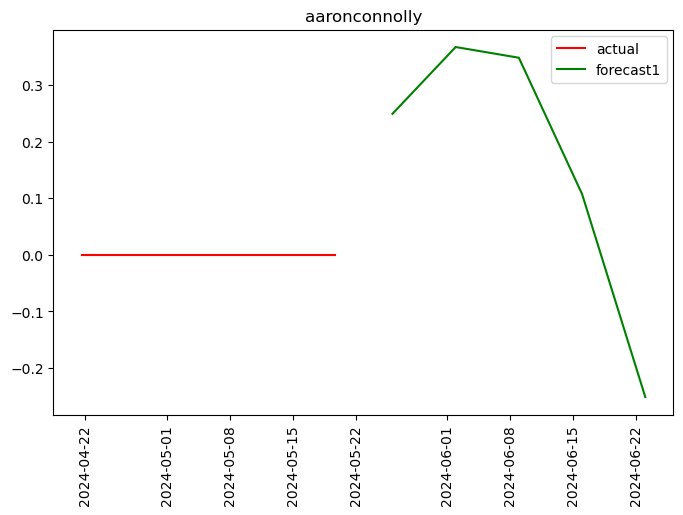

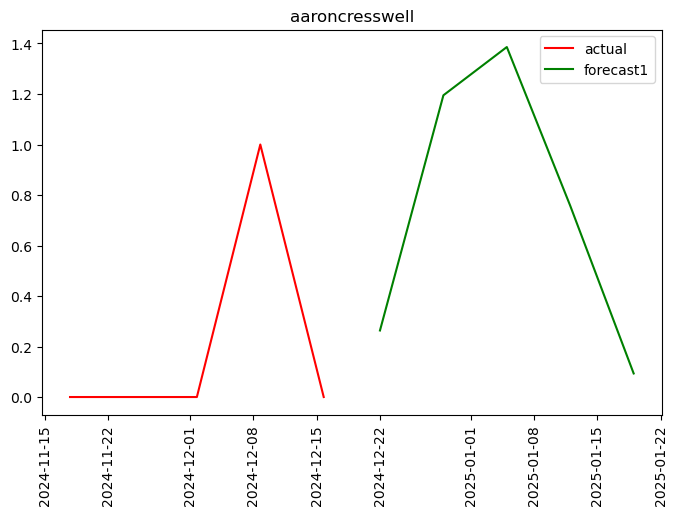

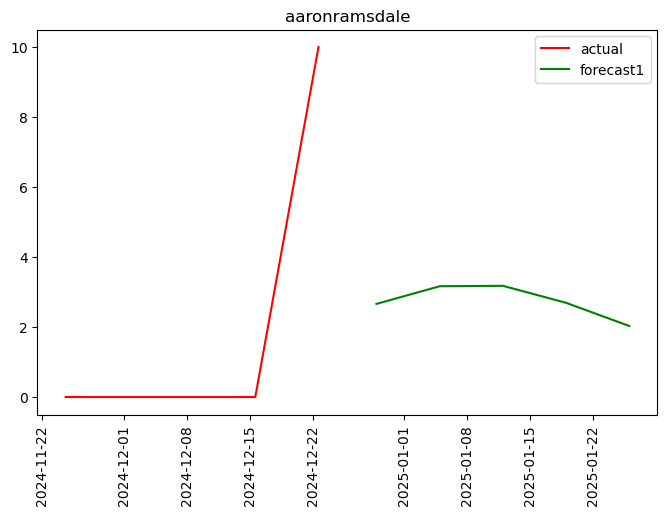

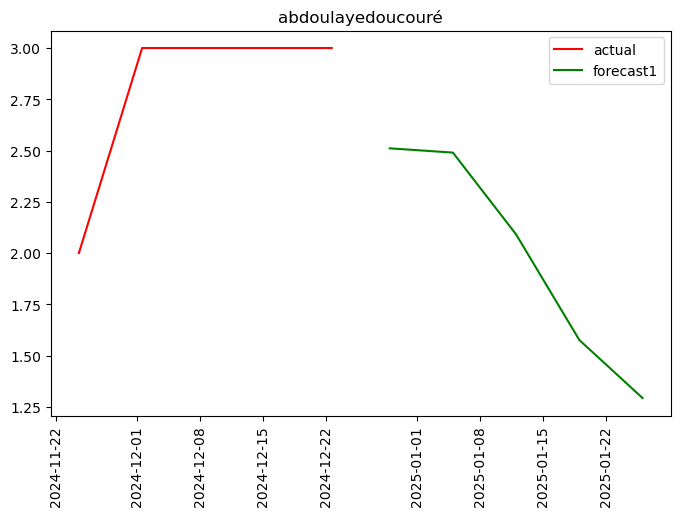

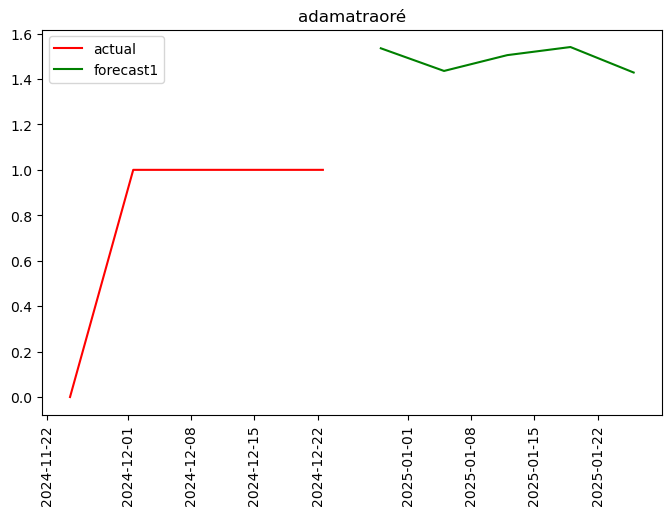

...

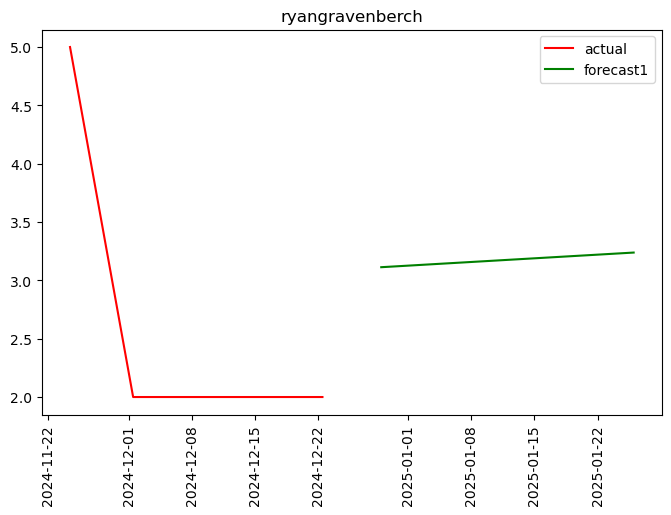

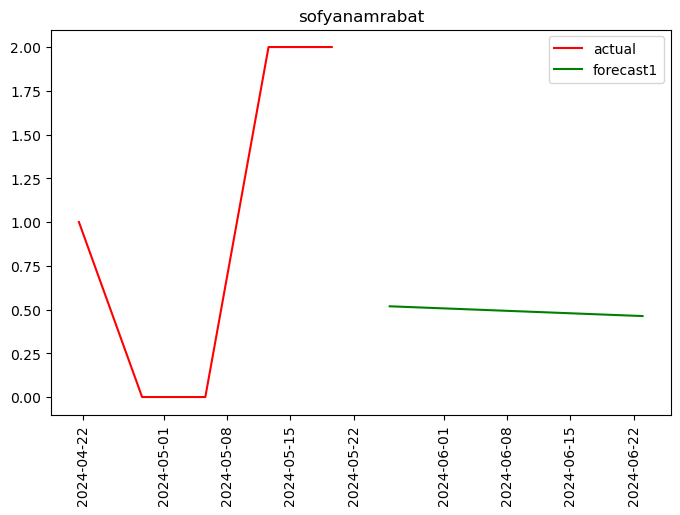

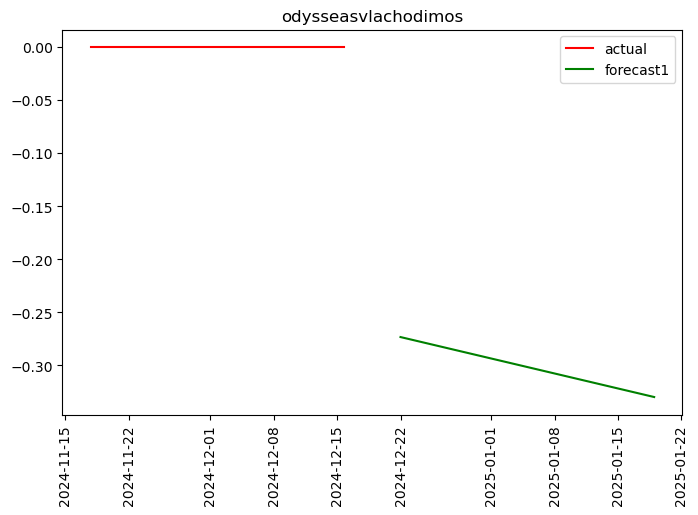

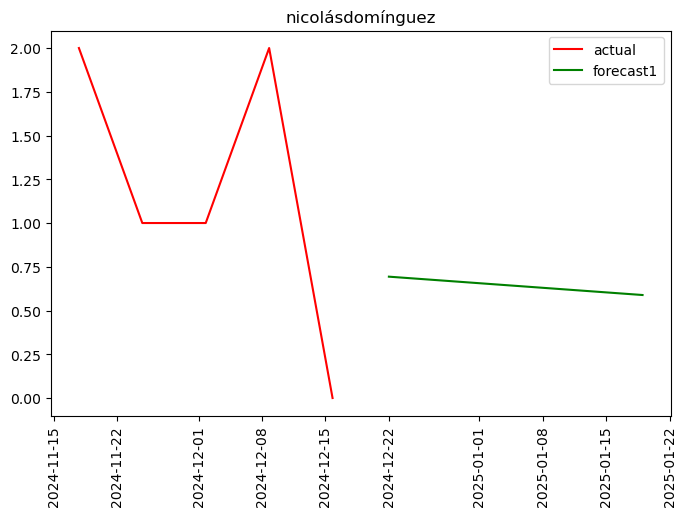

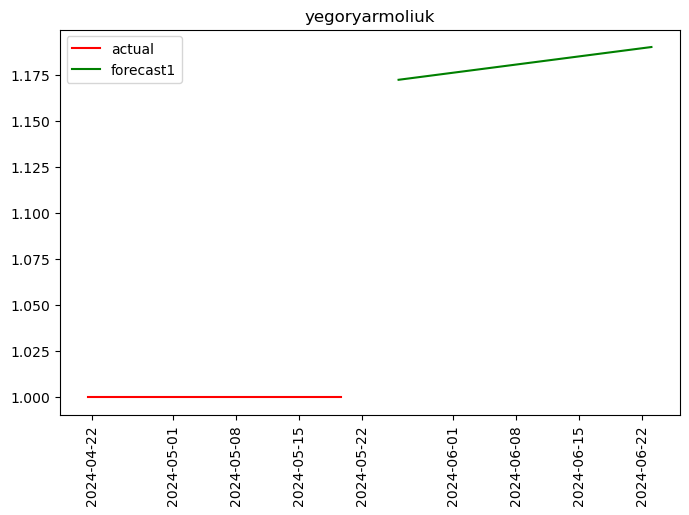

In [10]:
frcst_DF = dfs.dropna().drop_duplicates(subset= 'name').reset_index(drop=True)[['name', 'position', 'opponent_team']]
frcst_DF['score'] = frcst_DF['name'].apply(lambda x: point_frsct(dfs, x, 5))
frcst_DF['score'] = frcst_DF['score'].fillna(0)

In [13]:
top =frcst_DF.sort_values(by = ['score'], ascending=False).head(50)

In [14]:
top.loc[(top['position'] == 'FWD') | (top['position'] == 'MID')].reset_index(drop=True)
# top.loc[(top['position'] == 'GK')].reset_index(drop=True)

,name,position,opponent_team,score
0,diogoteixeiradasilva,FWD,9,9.408992
1,bukayosaka,MID,8,9.085866
2,colepalmer,MID,9,6.997959
3,brennanjohnson,FWD,15,6.625403
4,brunoborgesfernandes,MID,5,6.229739
5,jarrodbowen,MID,14,6.109198
6,amadouonana,MID,2,5.890598
7,mohamedsalah,MID,10,5.854938
8,rodrigohernandez,MID,20,5.806052
9,mateokovačić,MID,6,5.797988


In [ ]:
frcst_DF[frcst_DF['name'].str.contains('carval')]

In [ ]:
point_frsct(dfs, 'davidrayamartin', 5)

In [ ]:
frcst_DF[frcst_DF['name'].str.contains('wel')]

### ----------Ends here-----------------

In [ ]:
        model.add_regressor("assists", standardize = False)
        model.add_regressor("bonus", standardize = False)
        model.add_regressor("bps", standardize = False)
        model.add_regressor("goals_conceded", standardize = False)
        model.add_regressor("goals_scored", standardize = False)
        model.add_regressor("selected", standardize = False)
        model.add_regressor("threat", standardize = False)
        model.add_regressor("value", standardize = False)
        model.add_regressor("xP", standardize = False)
        model.add_regressor("clean_sheets_1", standardize = False)

In [ ]:
for c in df.columns:
    exec(f'model.add_regressor("{c}", standardize = False)')

In [ ]:
for a in ['a', 'b', 'c']:
    exec(f'{a} = 1')

In [ ]:
b

In [ ]:
a

In [ ]:
import matplotlib.pyplot as plt

y_test = outdf['y']
y_test_pred = outdf['yhat']
# Calculate residuals
residuals = y_test - y_test_pred

# Plot residuals
plt.scatter(y_test_pred, residuals)
plt.hlines(y=0, xmin=min(y_test_pred), xmax=max(y_test_pred), colors='r')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

In [ ]:
forecast1['ds']

In [ ]:
import seaborn as sns

In [ ]:
sns.boxplot(dffn['assists'])

In [ ]:
df_ref['goals_conceded'].value_counts()

In [ ]:
len(df_final)

In [ ]:
len(dffn)

In [ ]:
len(df_ref)

In [ ]:
dffnn

In [ ]:
dffnn = dffn[contin_var_final]

In [ ]:
data = dffn[[ i for i in dffn.columns if i != "total_points"]]
label = dffn['total_points']

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from imblearn.over_sampling import SMOTE

# Load data
data = dffn

# Assuming 'target' is the column you want to predict, and the rest are features
X = data.drop('total_points', axis=1)
y = data['total_points']

In [ ]:
# Handle imbalance with SMOTE
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X, y)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Fit the scaler on the training data and transform both training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [ ]:
# Initialize the Random Forest Regressor
rf = RandomForestRegressor(n_jobs= -1, random_state=42)

# Train the model
rf.fit(X_train_scaled, y_train)

In [ ]:
# Predict on the test set
y_test_pred = rf.predict(X_test_scaled)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_test_pred)
r2 = r2_score(y_test, y_test_pred)

print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2}")


In [ ]:
# Calculate Cross-Validation scores
cv_scores = cross_val_score(rf, X_train_scaled, y_train, cv=5, scoring='r2')
print(f"Cross-Validation R^2 Scores: {cv_scores}")
print(f"Average Cross-Validation R^2: {np.mean(cv_scores)}")

In [ ]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_test - y_test_pred

# Plot residuals
plt.scatter(y_test_pred, residuals)
plt.hlines(y=0, xmin=min(y_test_pred), xmax=max(y_test_pred), colors='r')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

# Predict on training and test sets
y_train_pred = xgb.predict(X_train_scaled)
y_test_pred = xgb.predict(X_test_scaled)

# Calculate R^2 and MSE for training set
train_r2 = r2_score(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)

# Calculate R^2 and MSE for test set
test_r2 = r2_score(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"Training R^2: {train_r2}")
print(f"Training MSE: {train_mse}")
print(f"Test R^2: {test_r2}")
print(f"Test MSE: {test_mse}")

In [ ]:
def uniFut(col_name, fut_ds):

    m = Prophet()
    pdf = dffn[[col_name, 'ds']].rename(columns={col_name:'y'})
    m.fit(pdf)
    return m.predict(fut_ds)[['ds', 'yhat']].rename(columns={'yhat':col_name})

In [ ]:
unDF = pd.DataFrame(columns=['ds'])
for uncol in df_train.drop(['ds', 'y'], axis=1).columns:
    print(uncol)
    unDF = pd.merge(unDF, uniFut(uncol, fut), on = 'ds', how ='outer' )

In [ ]:
contin_var_final

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data, label, test_size=0.2, random_state=42)

In [ ]:
# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Fit the scaler on the training data and transform both training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
scale_pos_weight = (len(label) - np.sum(label)) / np.sum(label) 
xgb = XGBRegressor(scale_pos_weight=scale_pos_weight, random_state=42)

In [ ]:
xgb.fit(X_train_scaled, y_train)

In [ ]:
y_pred = xgb.predict(X_test_scaled)

In [ ]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2}")

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

# Predict on training and test sets
y_train_pred = xgb.predict(X_train_scaled)
y_test_pred = xgb.predict(X_test_scaled)

# Calculate R^2 and MSE for training set
train_r2 = r2_score(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)

# Calculate R^2 and MSE for test set
test_r2 = r2_score(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"Training R^2: {train_r2}")
print(f"Training MSE: {train_mse}")
print(f"Test R^2: {test_r2}")
print(f"Test MSE: {test_mse}")


In [ ]:
from sklearn.model_selection import cross_val_score

# Perform cross-validation
cv_scores = cross_val_score(xgb, X_train_scaled, y_train, cv=5, scoring='r2')

print(f"Cross-Validation R^2 Scores: {cv_scores}")
print(f"Average Cross-Validation R^2: {np.mean(cv_scores)}")


In [ ]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_test - y_test_pred

# Plot residuals
plt.scatter(y_test_pred, residuals)
plt.hlines(y=0, xmin=min(y_test_pred), xmax=max(y_test_pred), colors='r')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()


In [ ]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_test - y_test_pred

# Plot residuals
plt.scatter(y_test_pred, residuals)
plt.hlines(y=0, xmin=min(y_test_pred), xmax=max(y_test_pred), colors='r', linestyles='dashed')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()


In [ ]:
# Predict on the training set
y_train_pred = xgb.predict(X_train_scaled)

# Calculate R^2 and MSE for training set
train_r2 = r2_score(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)

# Calculate R^2 and MSE for test set
test_r2 = r2_score(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"Training R^2: {train_r2}")
print(f"Training MSE: {train_mse}")
print(f"Test R^2: {test_r2}")
print(f"Test MSE: {test_mse}")


In [ ]:
for biv in ["clean_sheets", "penalties_missed", "penalties_saved",  "was_home", "red_cards", "yellow_cards"]:
    print(biv, stats.pointbiserialr(df[biv], df['total_points']))


In [ ]:

# Create a sample DataFrame
data = {'Binary': [0, 1, 0, 1, 0, 1],
        'Continuous': [2.3, 3.4, 2.1, 4.3, 2.2, 4.5]}
df = pd.DataFrame(data)

# Calculate point-biserial correlation
binary = df['Binary']
continuous = df['Continuous']
correlation, p_value = stats.pointbiserialr(binary, continuous)

print(f"Point-Biserial Correlation: {correlation}")
print(f"P-value: {p_value}")


In [ ]:
chi2_contingency(pd.crosstab(df['was_home'], df['yellow_cards']))

In [ ]:
clean_sheets: #penalties_missed, was_home, yellow_cards
#penalties_missed: yellow_cards
#was_home: yellow_cards
red_cards: 
#yellow_cards

In [ ]:
yellow_cards, penalties_missed

In [ ]:
spearmanr(df.iloc[:,0], df.iloc[:,1])

In [ ]:
df.columns

In [ ]:
df.iloc[:,0]

In [ ]:
for col in df.columns:
    df[col]

In [ ]:
df.head()

In [ ]:
len(df)

In [ ]:
 df1 = df.dropna()

In [ ]:
len(df1)

In [ ]:
print([i for i in df.iloc[1]])

In [ ]:
dffn.columns

In [ ]:
df['name'][df['name'].str.contains('sala')]

In [ ]:
ddf = df[df['name'] == player]


ddf.set_index("kickoff_time", inplace=True)
if not (ddf.sort_index()[:"2023"].empty or ddf.sort_index()["2024":].empty):    
    ddf = ddf.sort_index().asfreq("W", method="bfill")
    ddf.reset_index(inplace=True)
    ddf.rename({"kickoff_time":"ds", "total_points":"y"}, axis=1, inplace=True)
    ddf['ds'] = ddf['ds'].apply(lambda x:x.tz_localize(None))
    ###m = Prophet(changepoint_prior_scale=0.01, interval_width = 0.95)
    m = Prophet(changepoint_prior_scale=0.01, interval_width = 0.95)
    #m = Prophet(growth='flat', interval_width = 0.95)
    m.fit(ddf)
    future = m.make_future_dataframe(periods=50)
    forecast = m.predict(future)
    out = forecast.set_index('ds')['yhat'].resample("D").median().tail(10).mean()
else:
    out = 0
    print(" Obsolete player found ---------------:", player)
return out
        


In [ ]:
def point_frsct(player):
    try:
        
        ddf = df[df['name'] == player]

        ddf.set_index("kickoff_time", inplace=True)
        if not (ddf.sort_index()[:"2023"].empty or ddf.sort_index()["2024":].empty):    
            ddf = ddf.sort_index().asfreq("W", method="bfill")
            ddf.reset_index(inplace=True)
            ddf.rename({"kickoff_time":"ds", "total_points":"y"}, axis=1, inplace=True)
            ddf['ds'] = ddf['ds'].apply(lambda x:x.tz_localize(None))
            ###m = Prophet(changepoint_prior_scale=0.01, interval_width = 0.95)
            m = Prophet(changepoint_prior_scale=0.01, interval_width = 0.95)
            #m = Prophet(growth='flat', interval_width = 0.95)
            m.fit(ddf)
            future = m.make_future_dataframe(periods=50)
            forecast = m.predict(future)
            out = forecast.set_index('ds')['yhat'].resample("D").median().tail(10).mean()
        else:
            out = 0
            print(" Obsolete player found ---------------:", player)
        return out
        
    except Exception as e:
        print("Exception found !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!\n", e) 
        print(ddf)
    

In [ ]:
frcst_DF = df.dropna().drop_duplicates(subset= 'name')
frcst_DF['score'] = frcst_DF['name'].apply(point_frsct)
frcst_DF['score'] = frcst_DF['score'].fillna(0)

In [ ]:
#df = df[["name", "kickoff_time", "total_points", "position", "team"]]

In [ ]:
frcst_DF.sort_values(by = ['score'], ascending=False).head(30)

In [ ]:
#player_df = pd.read_csv("/Users/gokul/Documents/code/FPL/Fantasy-Premier-League/data/2023-24/cleaned_players.csv")
#player_df['name'] = player_df.apply(lambda x: re.sub(r'[^\w]|[_\d]', '', str(x['first_name']+x['second_name'])).lower(), axis=1)
#f_df = pd.merge(frcst_DF, player_df, on= 'name', how='full')[['name', 'element_type', 'score']]

#--- Analysis

In [ ]:
frcst_DF = frcst_DF.sort_values(by = ['score'], ascending=False).reset_index()

In [ ]:
#frcst_DF['position'] = frcst_DF['position'].str.replace('MID|FWD', 'MID-FWD', regex=True)
fdf = frcst_DF.groupby('position').head(20).sort_values(by = ['position', 'score'], ascending = False)

In [ ]:
top = frcst_DF.sort_values(by = ['score'], ascending=False).head(100)

In [ ]:
top[['position', 'score']].groupby('position').mean()

In [ ]:
fdf[fdf['position'] == 'MID']

#--- Individual Analysis

In [ ]:
%matplotlib inline

In [ ]:
for player in fdf[fdf['position'] == 'FWD']['name'][:10]:

#player = "mateokovačić"
    ddf = df[df['name'] == player].sort_index()
    #ddf = ddf[["kickoff_time", "total_points"]]
    
    #ddf = ddf.set_index("kickoff_time").sort_index().asfreq("D", method="pad")
    ddf = ddf.set_index("kickoff_time").sort_index().asfreq("W", method="bfill")
    #ddf['total_points'] = ddf['total_points'].interpolate(method='linear')
    ddf.reset_index(inplace=True)
    ddf.rename({"kickoff_time":"ds", "total_points":"y"}, axis=1, inplace=True)
    ddf['ds'] = ddf['ds'].apply(lambda x:x.tz_localize(None))
    m = Prophet(changepoint_prior_scale=0.01, interval_width = 0.95)
    #m = Prophet(growth='flat', interval_width = 0.95)
    m.fit(ddf)
    future = m.make_future_dataframe(periods=50)
    forecast = m.predict(future)
    
    out = forecast.set_index('ds')['yhat'].resample("D").median().tail(10).mean()
    pd.concat([ddf.set_index('ds')['y'], forecast.set_index('ds')['yhat']], axis=1).plot(title=player+" - "+str(out))

In [ ]:
m.plot(forecast)

In [ ]:
m.plot_components(forecast)

#-----------------

In [ ]:
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(10)